# Bloque II — Intervenciones territoriales de la política de integración sociourbana

**Análisis de obras y del programa Mi Pieza a partir de bases abiertas oficiales**

Tesis doctoral — *Políticas públicas habitacionales e integración sociourbana en barrios populares en el Área Metropolitana de Tucumán (2016-2023)*
CONICET – FAU UNT

---

### Alcance

El cuaderno analiza **qué se ejecutó, con qué línea programática, con qué financiamiento y dónde**, en dos escalas: el universo nacional y el recorte del Área Metropolitana de Tucumán (AMT), definido por los barrios RENABAP validados espacialmente en QGIS 3.34.

### Fuentes (repositorio `Camilamop/RENABAP`, rama `master`)

| Archivo | Fuente | Unidad de análisis |
|---|---|---|
| `Datos-abiertos-FISU.csv` · `-BID.csv` · `-FF.csv` | datos.gob.ar | proyecto de obra, según financiamiento |
| `Obras_monitor_datastudio.csv` | Monitor de obras (DataStudio) | obra |
| `mi-pieza_datos_gob_ar.csv` | datos.gob.ar | solicitud individual de Mi Pieza (microdato) |
| `Obras_mipieza_datastudio.csv` | Monitor Mi Pieza (DataStudio) | barrio (agregado) |
| `RENABAP_AMT_2018/2022/2023.csv` | RENABAP + selección espacial en QGIS | barrio popular del AMT |
| `RENABAP_2023.csv` · `limite_amt.gpkg` | RENABAP · CETyHaP | polígonos y límite metropolitano |
| `indice_icc.csv` | INDEC | variación mensual del ICC |

Las fuentes de obras **no son sumables**: datos.gob.ar publica el *proyecto contratado* (con línea, financiamiento y acta de inicio) y el Monitor la *obra* (con inversión, familias y avance). Se usan de forma comparada, nunca concatenada.

### Estructura

0. Configuración · 1. Carga de fuentes · 2. Auditoría de calidad y armonización · 3. Obras — escala nacional · 4. Obras — AMT · 5. Análisis financiero (ICC) · 6. Mi Pieza — escala nacional · 7. Mi Pieza — AMT · 8. Cartografía · 9. Exportación

---
## 0. Configuración
### 0.1 Librerías y formato numérico argentino

In [ ]:
# 0.1 — Librerías y formato numérico argentino
import os, re, unicodedata, warnings
from numbers import Number

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("styler.format.thousands", ".")
pd.set_option("styler.format.decimal", ",")

# Formato argentino (1.234.567,89) en tablas, textos y ejes.
# Los CSV exportados conservan los números como números.


def fmt_ar(x, dec=0):
    try:
        if pd.isna(x):
            return "NaN"
    except (TypeError, ValueError):
        return str(x)
    s = f"{x:,.{dec}f}"
    return s.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


pd.set_option("display.float_format", lambda x: fmt_ar(x, 2))

# Años e identificadores van sin separador de miles (2023, no 2.023)
_SIN_MILES = re.compile(r"(^|[_ ])(anio|año|year|decada|década)([_ ]|$)"
                        r"|^(id|id_renabap|id_barrio|.*_id)$", re.I)


def _es_numero(x):
    return isinstance(x, (Number, np.number)) and not isinstance(x, (bool, np.bool_))


def _decimales(valores):
    v = pd.to_numeric(pd.Series(list(valores)), errors="coerce").astype(float)
    v = v[np.isfinite(v)]
    if v.empty:
        return 0
    for d in (0, 1):
        if np.allclose(v, v.round(d), rtol=0, atol=1e-9):
            return d
    return 2


def _formateador(valores, nombre=None, dec=None):
    valores = list(valores)
    nums = [x for x in valores if _es_numero(x)]
    sin_miles = bool(_SIN_MILES.search(str(nombre))) if nombre is not None else False
    if dec is None:
        dec = _decimales(nums) if nums else 0

    def f(x):
        if isinstance(x, pd.Timestamp):
            return x.strftime("%Y-%m-%d") if x == x.normalize() else str(x)
        if not _es_numero(x):
            return x if isinstance(x, str) else str(x)
        if pd.isna(x):
            return "NaN"
        if sin_miles:
            return str(int(x)) if float(x).is_integer() else str(x)
        if dec == 2 and float(x).is_integer():
            return fmt_ar(x, 0)
        return fmt_ar(x, dec)
    return f


def _decimales_tabla(df):
    # Si una columna usa 1 decimal, las columnas decimales sin fracción también,
    # para que no convivan "70" y "71,7" en la misma tabla.
    decs = {}
    for j in range(df.shape[1]):
        nums = [x for x in df.iloc[:, j] if _es_numero(x)]
        decs[j] = _decimales(nums) if nums else 0
    con_uno = any(d == 1 for d in decs.values())
    for j in range(df.shape[1]):
        if con_uno and decs[j] == 0 and pd.api.types.is_float_dtype(df.iloc[:, j]):
            decs[j] = 1
    return decs


def _df_ar(df):
    out = pd.DataFrame(index=df.index)
    decs = _decimales_tabla(df)
    for j in range(df.shape[1]):
        col = df.iloc[:, j]
        out[j] = col.map(_formateador(col, df.columns[j], decs[j])).values
    out.columns = df.columns
    idx = df.index
    if idx.nlevels == 1 and idx.name is not None and pd.api.types.is_numeric_dtype(idx):
        out.index = pd.Index(idx.map(_formateador(idx, idx.name)), name=idx.name)
    return out


def texto_ar(obj, pie=False, **kw):
    """Reemplaza a print(df) y df.to_string() con formato argentino."""
    if isinstance(obj, pd.DataFrame):
        return _df_ar(obj).to_string(**kw)
    if isinstance(obj, pd.Series):
        txt = _df_ar(obj.to_frame()).iloc[:, 0].to_string(**kw)
        if pie:
            nombre = f"Name: {obj.name}, " if obj.name is not None else ""
            txt += f"\n{nombre}dtype: {obj.dtype}"
        return txt
    if isinstance(obj, tuple) and all(_es_numero(v) for v in obj):
        return "(" + ", ".join(fmt_ar(v) for v in obj) + ")"
    if _es_numero(obj):
        return fmt_ar(obj, _decimales([obj]))
    return str(obj)


@pd.api.extensions.register_dataframe_accessor("ar")
@pd.api.extensions.register_series_accessor("ar")
class _AccesorAR:
    def __init__(self, obj):
        self._obj = obj

    def to_string(self, **kw):
        return texto_ar(self._obj, **kw)


def _html_ar(df):
    """Cómo se muestran los DataFrame en el cuaderno."""
    try:
        max_f = pd.get_option("display.max_rows") or len(df)
        min_f = pd.get_option("display.min_rows") or 10
        max_c = pd.get_option("display.max_columns") or df.shape[1]
        vista, recortada = df, False
        if len(df) > max_f:
            vista, recortada = pd.concat([df.head(min_f // 2), df.tail(min_f // 2)]), True
        if df.shape[1] > max_c:
            vista = pd.concat([vista.iloc[:, :max_c // 2], vista.iloc[:, -(max_c // 2):]], axis=1)
            recortada = True
        sty = vista.style
        decs = _decimales_tabla(vista)
        for j, c in enumerate(vista.columns):
            sty = sty.format(_formateador(vista.iloc[:, j], c, decs[j]), subset=[c], escape="html")
        idx = vista.index
        if idx.nlevels == 1 and idx.name is not None and pd.api.types.is_numeric_dtype(idx):
            sty = sty.format_index(_formateador(idx, idx.name), axis=0)
        else:
            sty = sty.format_index(escape="html", axis=0)
        sty = sty.format_index(escape="html", axis=1).set_table_attributes('class="dataframe"')
        html = sty.to_html()
        if recortada:
            html += (f"<p>Se muestran {fmt_ar(len(vista))} de {fmt_ar(len(df))} filas "
                     f"× {fmt_ar(df.shape[1])} columnas</p>")
        return html
    except Exception:
        return df._repr_html_()


try:
    _fmt = get_ipython().display_formatter.formatters
    _fmt["text/html"].for_type(pd.DataFrame, _html_ar)
    _fmt["text/plain"].for_type(pd.Series, lambda s, p, cycle: p.text(texto_ar(s, pie=True)))
except NameError:
    pass


def _tick_ar(v, pos=None):
    if v == 0:
        return "0"
    s = fmt_ar(v, 2)
    return s.rstrip("0").rstrip(",") if "," in s else s


EJE_AR = FuncFormatter(_tick_ar)


def formato_ejes_ar(fig=None):
    for ax in (fig or plt.gcf()).axes:
        for eje in (ax.xaxis, ax.yaxis):
            if type(eje.get_major_formatter()) is ScalarFormatter:
                eje.set_major_formatter(EJE_AR)


# plt.show aplica el formato AR antes de mostrar cada figura
if not hasattr(plt, "_show_original"):
    plt._show_original = plt.show


def _show_ar(*args, **kwargs):
    for n in plt.get_fignums():
        formato_ejes_ar(plt.figure(n))
    return plt._show_original(*args, **kwargs)


plt.show = _show_ar

### 0.2 Paleta y estilo de los gráficos

Una sola paleta para todo el cuaderno, con colores asignados por **función** y no por orden de aparición: la misma categoría tiene siempre el mismo color, en los gráficos y en los mapas.

| Uso | Regla |
|---|---|
| Una sola serie | azul |
| Dos fuentes de obras | datos.gob.ar azul · Monitor naranja |
| Referencia vs. foco (país vs. AMT, corriente vs. constante) | gris la referencia · azul el foco |
| Elemento destacado (Tucumán) | naranja sobre azul |
| Categorías fijas (estado, dimensión, escala, situación) | diccionarios `COLOR_*` |
| Magnitud en mapas | rampa de un solo tono, de claro a azul |

In [ ]:
# 0.2 — Paleta y estilo de los gráficos
AZUL, VIOLETA, MAGENTA, CORAL, NARANJA, AMARILLO, LILA, PETROLEO = (
    "#2F4B7C", "#A05195", "#D45087", "#F95D6A", "#FF7C43", "#FFA600", "#665191", "#003F5C")
GRIS, GRIS_CLARO, TINTA = "#BDBDBD", "#EEEEEE", "#444444"

COLOR_FUENTE = {"datos.gob.ar": AZUL, "Monitor": NARANJA}
COLOR_REFERENCIA = {"País": GRIS, "AMT": AZUL, "Corriente": GRIS, "Constante": AZUL}
COLOR_ESTADO_OBRA = {"Terminado": AZUL, "En ejecución": NARANJA,
                     "En contratación": AMARILLO, "Pagado": VIOLETA}
COLOR_ESTADO_MP = {"Activa": AZUL, "Seleccionada": NARANJA, "Inscripta": GRIS}
COLOR_DIMENSION = {"Infraestructuras": AZUL, "Equipamiento": NARANJA,
                   "Calidad ambiental": VIOLETA, "Situación dominial": AMARILLO,
                   "Vivienda": MAGENTA, "Planificación": LILA,
                   "Sin especificar": GRIS, "Sin clasificar": GRIS_CLARO}
COLOR_ESCALA = {"barrial": AZUL, "comunitaria": NARANJA, "ambas": VIOLETA,
                "sin determinar": GRIS}
COLOR_SITUACION = {"Obra + Mi Pieza": AZUL, "Sólo obra": VIOLETA,
                   "Sólo Mi Pieza": NARANJA, "Sin intervención": GRIS}
CMAP_MAGNITUD = LinearSegmentedColormap.from_list("magnitud", ["#E3E8F0", AZUL])

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.alpha": 0.25,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "font.size": 10,
    "legend.frameon": False,
})


def barras_h(ax, serie, titulo="", xlabel="", color=AZUL, resaltar=None):
    """Barras horizontales de una serie, ordenadas de mayor a menor (arriba)."""
    s = serie.sort_values()
    colores = [NARANJA if i == resaltar else color for i in s.index]
    ax.barh(s.index.astype(str), s.values, color=colores, height=0.7)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel("")


def barras_agrupadas(ax, df, colores, titulo="", xlabel=""):
    """Una barra por columna del DataFrame, agrupadas por fila."""
    df = df.fillna(0)
    y, n = np.arange(len(df)), df.shape[1]
    alto = 0.8 / n
    for k, c in enumerate(df.columns):
        ax.barh(y + ((n - 1) / 2 - k) * alto, df[c].values, height=alto * 0.92,
                color=colores.get(c, GRIS), label=c)
    ax.set_yticks(y); ax.set_yticklabels(df.index)
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.legend(loc="lower right")


def barras_apiladas(ax, df, colores, titulo="", xlabel="% de obras"):
    izq = np.zeros(len(df))
    for c in df.columns:
        ax.barh(df.index.astype(str), df[c].values, left=izq, color=colores.get(c, GRIS),
                label=c, edgecolor="white", linewidth=1, height=0.7)
        izq += df[c].values
    ax.set_title(titulo); ax.set_xlabel(xlabel); ax.set_ylabel("")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="Estado")


def mapa_base(titulo):
    """Lámina con el límite del AMT y, debajo, un mapa base en grises con las vías
    principales (CARTO Positron). Si no hay conexión, el mapa sale igual, sin fondo."""
    fig, ax = plt.subplots(figsize=(9, 10))
    limite_map.boundary.plot(ax=ax, color=TINTA, linewidth=0.9, zorder=4)
    xmin, ymin, xmax, ymax = limite_map.total_bounds
    ax.set_xlim(xmin - 1500, xmax + 1500); ax.set_ylim(ymin - 1500, ymax + 1500)
    for url, atribucion in MAPA_BASE:
        try:
            ctx.add_basemap(ax, crs=CRS_MAPA, source=url, attribution=atribucion,
                            attribution_size=6, zorder=0)
            break
        except Exception as e:
            print(f"Mapa base no disponible en {url.split('/')[2]} ({type(e).__name__}).")
    ax.set_title(titulo, fontsize=12, pad=14)
    ax.set_axis_off()
    ax.annotate("Fuente: elaboración propia sobre RENABAP 2023 y SISU (datos.gob.ar).",
                xy=(0.01, 0.035), xycoords="axes fraction", fontsize=7, color="#555555")
    return fig, ax

### 0.3 Rutas y parámetros

Todo lo que puede ajustarse sin tocar el resto del cuaderno está acá.

In [ ]:
# 0.3 — Rutas y parámetros
BASE = "https://raw.githubusercontent.com/Camilamop/RENABAP/master"
RAW = f"{BASE}/data/raw"
PROC = f"{BASE}/data/processed/qgis"

FUENTES = {
    "obras_fisu":      f"{RAW}/Datos-abiertos-FISU.csv",
    "obras_bid":       f"{RAW}/Datos-abiertos-BID.csv",
    "obras_ff":        f"{RAW}/Datos-abiertos-FF.csv",
    "obras_monitor":   f"{RAW}/Obras_monitor_datastudio.csv",
    "mipieza_micro":   f"{RAW}/mi-pieza_datos_gob_ar.csv",
    "mipieza_monitor": f"{RAW}/Obras_mipieza_datastudio.csv",
    "amt_2018":        f"{PROC}/RENABAP_AMT_2018.csv",
    "amt_2022":        f"{PROC}/RENABAP_AMT_2022.csv",
    "amt_2023":        f"{PROC}/RENABAP_AMT_2023.csv",
    "renabap_2023":    f"{RAW}/RENABAP_2023.csv",
    "limite_amt":      f"{RAW}/limite_amt.gpkg",
    "icc":             f"{RAW}/indice_icc.csv",
}

# Universo AMT: "union" toma los barrios de cualquiera de los tres relevamientos,
# porque una obra puede estar en un barrio que después salió del registro.
CORTE_AMT = "union"          # "union" | "2018" | "2022" | "2023"

# Imputar los genéricos de cada fuente con la obra descrita en la otra (ver 3.12)
IMPUTAR_GENERICOS = True

# Mes al que se llevan todos los montos a precios constantes (cierre del período)
MES_BASE_ICC = "2023-12"

# Las 24 jurisdicciones, para que tablas y gráficos provinciales muestren todas (aunque estén en cero)
PROVINCIAS = [
    "Buenos Aires", "Catamarca", "Chaco", "Chubut", "Ciudad Autónoma de Buenos Aires",
    "Córdoba", "Corrientes", "Entre Ríos", "Formosa", "Jujuy", "La Pampa", "La Rioja",
    "Mendoza", "Misiones", "Neuquén", "Río Negro", "Salta", "San Juan", "San Luis",
    "Santa Cruz", "Santa Fe", "Santiago del Estero", "Tierra del Fuego", "Tucumán",
]

# Sólo para el control del recorte AMT por nombre de municipio (4.2)
MUNICIPIOS_AMT = [
    "san miguel de tucuman", "yerba buena", "tafi viejo", "las talitas",
    "banda del rio sali", "alderetes", "lules", "san isidro de lules",
    "el manantial", "san pablo y villa nougues", "cevil redondo",
    "los pocitos", "san felipe y santa barbara", "la esperanza",
    "colombres", "delfin gallo", "los nogales", "san andres",
]
# Las bases alternan "Lules" y "San Isidro de Lules" para el mismo municipio
EQUIVALENCIAS_MUNICIPIO = {"lules": "san isidro de lules"}

CRS_GEO = "EPSG:4326"        # coordenadas originales del RENABAP
CRS_METRICO = "EPSG:5345"    # POSGAR 2007 faja 3, para superficies en Tucumán
CRS_MAPA = "EPSG:3857"       # el de los mapas base web, sólo para dibujar

EXPORTAR = True              # guarda tablas .csv y figuras .png en ./salidas/
os.makedirs("salidas/tablas", exist_ok=True)
os.makedirs("salidas/figuras", exist_ok=True)

### 0.4 Funciones de lectura, normalización y exportación

In [ ]:
# 0.4 — Funciones de lectura, normalización y exportación
VACIOS_DECLARADOS = {"varios", "s/d", "sin dato", "-", "", "nan"}


def leer_csv(url, **kw):
    """Los archivos del portal alternan UTF-8 y Latin-1."""
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(url, encoding=enc, **kw)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo decodificar {url}")


def sin_tildes(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s))
    return "".join(c for c in s if not unicodedata.combining(c))


def norm_texto(s):
    """Minúsculas, sin tildes ni dobles espacios: para comparar textos entre fuentes."""
    if pd.isna(s):
        return np.nan
    return re.sub(r"\s+", " ", sin_tildes(str(s)).lower()).strip()


def norm_patron(s):
    """Sólo para buscar los patrones F3: además de norm_texto, borra los nombres de
    BARRIOS_EXCLUIDOS y unifica guiones ("intra - lote" = "intra-lote")."""
    if pd.isna(s):
        return np.nan
    s = norm_texto(s)
    for barrio in BARRIOS_EXCLUIDOS:
        s = re.sub(rf"\b{re.escape(norm_texto(barrio))}\b", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"\s*-\s*", "-", s)


def a_numero(x):
    """'153,571,116.49' -> 153571116.49 ; '97.78%' -> 97.78"""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace("%", "").replace("$", "").replace(" ", "").replace(",", "")
    try:
        return float(s)
    except ValueError:
        return np.nan


def a_fecha(x):
    """En la misma columna conviven 'dd/mm/aaaa' y 'aaaa-mm-dd'."""
    if pd.isna(x) or str(x).strip() == "":
        return pd.NaT
    s = str(x).strip()
    fmt = "%Y-%m-%d" if re.match(r"^\d{4}-", s) else "%d/%m/%Y"
    return pd.to_datetime(s, format=fmt, errors="coerce")


def ids_renabap(x):
    """'2760/2762' -> ['2760','2762'] ; '1154*' -> ['1154'] ; 'Varios' o '-' -> []"""
    if pd.isna(x) or norm_texto(str(x)) in VACIOS_DECLARADOS:
        return []
    partes = [p.strip().rstrip("*").strip() for p in re.split(r"[\/;,]", str(x).strip())]
    return [p for p in partes if p.isdigit()]


def id_provisorio(x):
    """El asterisco marca barrios con registro no vigente (baja, fusión o revisión)."""
    return bool(pd.notna(x) and "*" in str(x))


def sin_identificador(x):
    return pd.isna(x) or norm_texto(str(x)) in VACIOS_DECLARADOS


def unificar_municipio(m):
    return EQUIVALENCIAS_MUNICIPIO.get(m, m)


def jurisdiccion(p):
    """Las obras declaradas en más de una provincia ("Varios", "Buenos Aires/Chaco")
    se agrupan como multiprovinciales: no se reparten para no contarlas dos veces."""
    return p if p in PROVINCIAS else "Multiprovincial"


def explotar(df, col_id="ids_renabap"):
    """Una fila por par obra–barrio. Sirve para contar barrios, nunca para sumar montos."""
    d = df.explode(col_id).rename(columns={col_id: "id_renabap"})
    d = d[d["id_renabap"].notna()].copy()
    d["id_renabap"] = d["id_renabap"].astype(str)
    return d


def guardar_tabla(df, nombre):
    if EXPORTAR:
        df.to_csv(f"salidas/tablas/{nombre}.csv", index=True, encoding="utf-8-sig")


def guardar_fig(nombre):
    formato_ejes_ar(plt.gcf())
    if EXPORTAR:
        plt.savefig(f"salidas/figuras/{nombre}.png", bbox_inches="tight", dpi=200)

### 0.5 Esquema de clasificación F3 — tipo, dimensión y escala

Cada obra se clasifica en tres capas encadenadas, buscando patrones en su nombre:

| Capa | Contenido | Origen |
|---|---|---|
| **Tipo** | nueve ejes de intervención | vocabulario efectivo de las bases |
| **Dimensión / subdimensión** | Infraestructuras · Equipamiento · Calidad ambiental · Situación dominial · Vivienda | matrices del Capítulo II |
| **Escala** | barrial · comunitaria | alcance del impacto de la intervención |

Criterios adoptados:

1. **Multietiqueta.** Un nombre suele enumerar varios componentes (`"Red de agua, Red cloacal y Conexiones domiciliarias"`), así que una obra puede activar varios tipos y dimensiones. Se conservan las columnas booleanas y se agrega una categoría `_principal` para los cruces que piden categoría única (gana el primer eje o subdimensión del diccionario que coincide).
2. **Genéricos.** Los nombres que sólo dicen "Obras de Integración Socio Urbana" quedan como `sin_especificar`: es la fuente la que no declara componentes.
3. **Tipo y dimensión se clasifican por separado** y después se contrastan (3.9), para ver dónde el vocabulario de la fuente y las matrices no se superponen.
4. **Escala.** Primero se busca una expresión diagnóstica (`nexo`, `intralote`, `canal`…); si no hay, se usa la escala por defecto de la subdimensión y la obra queda marcada con `escala_verificar = True`. Es un **primer análisis a gran escala, con valores de referencia**: el alcance real depende de cada proyecto y debe estudiarse caso por caso. En el AMT se realiza un análisis detallado sobre los casos de estudio.
5. **Vivienda** es la quinta dimensión de las matrices (Capítulo II).
6. **Planificación** no es una dimensión de las intervenciones sino un paso previo, no obligatorio. Corresponde a la línea PrePEG; PEG combina proyecto y ejecución de obra y se trata como obra. Se informa en una fila aparte de las tablas de dimensión y como atributo `caracter_intervencion`.
7. **Imputación de genéricos entre fuentes.** Las dos fuentes no comparten clave de obra, pero el monto contratado (datos.gob.ar) y la inversión (Monitor) coinciden al centavo. Con los montos únicos en cada fuente se arman pares obra a obra (2.8). Una obra genérica toma la clasificación de su par, si el par está descrito, y queda registrada en `origen_clasificacion`. Se controla con `IMPUTAR_GENERICOS` (0.3) y 3.12 compara los resultados con y sin imputación.

In [ ]:
# 0.5 — Esquema de clasificación F3
# Los patrones van en minúscula y sin tildes, porque se comparan contra norm_patron().

# Nombres de barrio que contienen palabras de los patrones: se borran del texto antes
# de clasificar para que el nombre del barrio no active un tipo.
BARRIOS_EXCLUIDOS = [
    "Obras Sanitarias", "Parque Las Rosas", "El Basural", "Toma Canal",
    "Puente Santa Mónica", "Tierras Vivas", "Tierras Nuevas Para Neuquén",
]

# --- Capa 1: tipo de intervención ---------------------------------------------
EJES = {
    "infraestructura_servicios": [
        r"red de agua", r"agua potable", r"\bcloac", r"red cloacal", r"desagu", r"pluvial",
        r"electric", r"energia electrica", r"red de distribucion", r"hidraulicas",
        r"\bgas\b", r"tendido", r"agua", r"estacion de bombeo", r"electrificacion",
        r"infraestructura", r"servicios", r"infrastructura",
    ],
    "conexiones_intradomiciliarias": [
        r"intra[- ]?lote", r"intra[- ]?slote", r"intra[- ]?domiciliar",
        r"intra[- ]?domciliar", r"intra[- ]?conexion",
        r"conexiones domiciliar", r"conexiones e instalaciones", r"instalaciones intra",
        r"intras? (?:de )?(?:electric|agua|cloaca|sanitari)", r"nexo",
    ],
    "movilidad_accesibilidad": [
        r"vereda", r"cordon cuneta", r"red peatonal", r"peatonal", r"red vial", r"vial",
        r"pavimen", r"calzada", r"puente", r"escalera", r"senda", r"alumbrado",
        r"via publica", r"pasillos", r"pasaje", r"iluminacion", r"calles", r"luminarias",
        r"pavimento",
    ],
    "ambiente": [
        r"residuos", r"ambiental", r"centro verde", r"ecopunto", r"punto verde", r"defensa",
        r"encauzamiento", r"canal", r"mitigacion", r"saneamiento ambiental",
        r"planta de separacion", r"basural", r"basurales", r"centro de acopio", r"cauce",
        r"saneamiento hidraulico", r"accesibilidad",
    ],
    "espacio_publico": [
        r"plaza", r"playon", r"espacio publico", r"espacio recreativo", r"recreativ",
        r"recreacion", r"deportiv", r"arbolado", r"forestac", r"parquizac",
    ],
    "equipamiento_comunitario": [
        r"equipamiento", r"centro comunitario", r"centro barrial", r"\bsum\b",
        r"espacio productivo", r"salon de usos", r"salud", r"cepla", r"jardin", r"educativ",
        r"comedor", r"posta", r"casa convivencial", r"espacio comunitario", r"memorial",
        r"deporte", r"deportivo", r"polideportivo", r"espacio verde",
    ],
    "vivienda": [
        r"vivienda", r"nucleo(s)? humedo", r"mejora(miento)? de vivienda",
        r"refaccion", r"relocalizacion", r"modulo habitacional", r"\bmv\b",
    ],
    "suelo_regularizacion": [
        r"(?<!intra )(?<!intra-)(?<!intra)\blote", r"adquisicion de tierra",
        r"tierra privada", r"mensura", r"loteo", r"dominial", r"redimensionamiento",
    ],
    "planificacion_proyecto": [
        r"proyecto ejecutivo", r"\bpre ?peg\b", r"diseno de un proyecto",
        r"diseno de proyecto", r"plan de", r"estudio",
        r"anteproyecto", r"asistencia tecnica", r"formulacion de proyecto",
    ],
}

EJES_ETIQUETA = {
    "infraestructura_servicios":     "Infraestructura de servicios",
    "conexiones_intradomiciliarias": "Conexiones intradomiciliarias",
    "movilidad_accesibilidad":       "Movilidad y accesibilidad",
    "ambiente":                      "Ambiente",
    "espacio_publico":               "Espacio público",
    "equipamiento_comunitario":      "Equipamiento comunitario",
    "vivienda":                      "Vivienda",
    "suelo_regularizacion":          "Suelo y regularización",
    "planificacion_proyecto":        "Planificación / proyecto",
}

# Nombres que no declaran componentes
PATRONES_GENERICOS = [
    r"^obras? de integracion socio ?-? ?urbanas?\.?$",
    r"^obras? de integracion sociourbanas?\.?$",
    r"^proyecto de integracion socio ?-? ?urbana$",
    r"^obras? de integracion urbana$",
    r"^obras? de interacion socio urbana$",
    r"^obras? de integracion socio urbanas? \(?etapa \d\)?$",
    r"^obras? de integracion socio urbana -?$",
]
# Segunda pasada: invocan la política sin declarar componentes, aunque no sean exactos
# ("Obras de Integración Socio Urbana - Barrio San Jacinto")
GENERICO_AMPLIO = (r"integracion soci|integraion soci|integracion urbana|integracion urbanistica"
                   r"|obras de infraestructura$|infraestructura urbana|urbanizacion|renovacion urbana"
                   r"|proyecto integral|plan integral|intervencion integral|urbanismo integral"
                   r"|mejoramiento integral|consolidacion soci|inclusion soci|activacion barrial|^pot b")

# --- Capa 2: dimensión y subdimensión (matrices del Capítulo II) ----------------
SUBDIMENSIONES = {
    "servicios_basicos_energia": {
        "dimension": "Infraestructuras", "etiqueta": "Servicios básicos y energía",
        "patrones": [r"red de agua", r"agua potable", r"\bcloac", r"desagu", r"pluvial",
                     r"nexo", r"red cloacal", r"energia electrica", r"agua", r"sanitari",
                     r"\bgas\b", r"electric", r"red de distribucion", r"intra[- ]?lote",
                     r"intra[- ]?slote", r"intra[- ]?domiciliar", r"intra[- ]?domciliar",
                     r"intra[- ]?conexion", r"conexiones domiciliar",
                     r"conexiones e instalaciones", r"hidraulicas", r"instalaciones intra",
                     r"intras? (?:de )?(?:electric|agua|cloaca|sanitari)", r"infraestructura",
                     r"infrastructura", r"tendido electric", r"estacion de bombeo",
                     r"electrificacion", r"tendido"]},
    "movilidad_conectividad": {
        "dimension": "Infraestructuras", "etiqueta": "Movilidad y conectividad",
        "patrones": [r"vereda", r"cordon cuneta", r"red peatonal", r"peatonal", r"vial",
                     r"red vial", r"pavimen", r"calzada", r"puente", r"escalera",
                     r"pavimento", r"servicios", r"senda", r"apertura de calle", r"alumbrado",
                     r"luminaria", r"via publica", r"pasillos", r"pasaje", r"iluminacion",
                     r"calles", r"luminarias", r"accesibilidad"]},
    "espacio_publico_deporte_cultura": {
        "dimension": "Equipamiento", "etiqueta": "Espacio público, deporte y cultura",
        "patrones": [r"plaza", r"playon", r"espacio publico", r"espacio recreativo",
                     r"arbolado", r"forestac", r"parquizac", r"parque", r"plazoleta",
                     r"recreativ", r"deportiv", r"cultural", r"memorial", r"recreacion",
                     r"deporte", r"deportivo", r"polideportivo", r"espacio verde"]},
    "salud_educacion": {
        "dimension": "Equipamiento", "etiqueta": "Salud y educación",
        "patrones": [r"salud", r"cepla", r"jardin", r"educativ", r"escuela", r"posta",
                     r"centro de atencion primaria", r"\bcaps\b"]},
    "administracion_bienestar": {
        "dimension": "Equipamiento", "etiqueta": "Administración y bienestar",
        "patrones": [r"centro comunitario", r"centro barrial", r"comedor",
                     r"casa convivencial", r"bienestar", r"desarrollo social", r"\bsum\b",
                     r"salon de usos", r"espacio comunitario", r"equipamiento"]},
    "servicios_consumo": {
        "dimension": "Equipamiento", "etiqueta": "Servicios y consumo",
        "patrones": [r"mercado", r"\bferia\b", r"comercial", r"productiv",
                     r"espacio productivo", r"polo\b", r"vivero", r"planta"]},
    "ambiental": {
        "dimension": "Calidad ambiental", "etiqueta": "Condiciones ambientales",
        "patrones": [r"residuos", r"ambiental", r"defensa", r"encauzamiento", r"canal",
                     r"mitigacion", r"saneamiento ambiental", r"planta de separacion",
                     r"basural", r"basurales", r"ecopunto", r"punto verde", r"centro verde",
                     r"centro de acopio", r"cauce", r"saneamiento"]},
    "regularizacion_tenencia": {
        "dimension": "Situación dominial", "etiqueta": "Regularización y seguridad en la tenencia",
        "patrones": [r"mensura", r"dominial", r"regularizacion", r"redimensionamiento",
                     r"loteo"]},
    "produccion_suelo": {
        "dimension": "Situación dominial", "etiqueta": "Producción de suelo urbanizado",
        "patrones": [r"lotes? con servicios", r"adquisicion de predio",
                     r"adquisicion de tierra", r"tierra privada",
                     r"(?<!intra )(?<!intra-)(?<!intra)\blote"]},
    "mejoramiento_vivienda": {
        "dimension": "Vivienda", "etiqueta": "Mejoramiento y provisión de vivienda",
        "patrones": [r"vivienda", r"mejora(miento)? de vivienda", r"refaccion",
                     r"modulo habitacional", r"\bmv\b", r"nucleo(s)? humedo",
                     r"relocalizacion"]},
    "instrumento_planificacion": {
        "dimension": "Planificación", "etiqueta": "Planificación y proyecto",
        "patrones": [r"proyecto ejecutivo", r"\bpre ?peg\b", r"diseno de un proyecto",
                     r"diseno de proyecto", r"anteproyecto",
                     r"asistencia tecnica", r"formulacion de proyecto",
                     r"plan de", r"estudio"]},
}

# Planificación queda deliberadamente fuera de las matrices
DIMENSIONES = ["Infraestructuras", "Equipamiento", "Calidad ambiental",
               "Situación dominial", "Vivienda"]

# Dimensión que corresponde, en principio, a cada tipo (se pone a prueba en 3.9)
TIPO_A_DIM = {
    "infraestructura_servicios":     "Infraestructuras",
    "conexiones_intradomiciliarias": "Infraestructuras",
    "movilidad_accesibilidad":       "Infraestructuras",
    "ambiente":                      "Calidad ambiental",
    "espacio_publico":               "Equipamiento",
    "equipamiento_comunitario":      "Equipamiento",
    "vivienda":                      "Vivienda",
    "suelo_regularizacion":          "Situación dominial",
    "planificacion_proyecto":        "Planificación",
}

# --- Capa 3: escala, según el alcance del impacto -------------------------------
#   barrial     -> el impacto queda dentro del barrio (p. ej., calles internas: los barrios
#                  populares suelen ser periféricos y sin tránsito pasante)
#   comunitaria -> el impacto excede el barrio y alcanza la zona (p. ej., un canal)
ESCALA_COMUNITARIA = [
    r"colectora", r"troncal",                                   # vínculo con la red troncal
    r"canal", r"cauce", r"arroyo", r"defensa", r"encauzamiento",
    r"saneamiento hidraulico",                                  # cuencas: aguas arriba y abajo
    r"planta de (?:separacion|tratamiento)", r"centro verde",   # residuos de la zona
    r"puente", r"acceso al barrio",                             # conexión con el entorno
    r"cepla", r"centro de atencion primaria", r"\bcaps\b", r"escuela", r"sanitario",
    r"salud",                                                   # área de influencia mayor
    r"adquisicion de tierras", r"tierra privada", r"lotes? con servicios",
    r"relocalizacion",                                          # suelo nuevo
]
ESCALA_BARRIAL = [
    r"intra[- ]?lote", r"intra[- ]?domiciliar", r"intra[- ]?conexion", r"instalaciones intra",
    r"intras? (?:de )?(?:electric|agua|cloaca|sanitari)", r"conexiones domiciliar",
    r"conexiones (?:de agua|electricas|a la cloaca|de gas|cloacales)",  # redacción del Monitor
    r"nucleo(s)? humedo", r"vivienda", r"mejora(miento)? de vivienda", r"refaccion",
    r"vereda", r"cordon cuneta", r"red peatonal", r"pasillos?", r"red vial", r"calles? intern",
    r"extension de red", r"\bnexo",
]
GRUPOS_ESCALA = {"barrial": ESCALA_BARRIAL, "comunitaria": ESCALA_COMUNITARIA}

# Escala por defecto cuando el nombre no trae ninguna expresión diagnóstica
ESCALA_DEFECTO = {
    "servicios_basicos_energia":       "barrial",
    "movilidad_conectividad":          "barrial",
    "espacio_publico_deporte_cultura": "barrial",
    "administracion_bienestar":        "barrial",
    "salud_educacion":                 "comunitaria",
    "servicios_consumo":               "comunitaria",
    "ambiental":                       "comunitaria",
    "regularizacion_tenencia":         "barrial",
    "produccion_suelo":                "comunitaria",
    "mejoramiento_vivienda":           "barrial",
    "instrumento_planificacion":       "sin determinar",   # no produce impacto territorial
}

# Cuando el nombre no informa nada pero la línea programática sí. POT no se imputa.
LINEA_A_CLASIFICACION = {
    "MV":             ("vivienda", "mejoramiento_vivienda"),
    "VIVIENDA":       ("vivienda", "mejoramiento_vivienda"),
    "LOTES":          ("suelo_regularizacion", "regularizacion_tenencia"),
    "LOTES (Adq.)":   ("suelo_regularizacion", "regularizacion_tenencia"),
    "PrePEG":         ("planificacion_proyecto", "instrumento_planificacion"),
    "INTEGRAR SALUD": ("equipamiento_comunitario", "salud_educacion"),
}

# Acciones registradas como obra que no transforman el territorio: quedan sin clasificar
# y se cuantifican aparte. Las obras BID "...afectadas por el COVID 19" sí son obras
# físicas (mejora de viviendas), por eso el patrón es específico.
FUERA_DE_MATRIZ = {
    "Fortalecimiento comunitario COVID-19":
        r"fortalecimiento comunitario.*covid|acciones de emergencia.*covid",
}

### 0.6 Funciones de clasificación F3

In [ ]:
# 0.6 — Funciones de clasificación F3
def _principal(fila, claves, prefijo):
    if fila["sin_especificar"]:
        return "sin_especificar"
    for k in claves:
        if fila[f"{prefijo}{k}"]:
            return k
    return "sin_clasificar"


def clasificar_f3(serie_texto):
    txt = serie_texto.map(norm_patron).fillna("")
    out = pd.DataFrame(index=serie_texto.index)
    generico = txt.str.match("|".join(PATRONES_GENERICOS), na=False)
    out["sin_especificar"] = generico

    for eje, patrones in EJES.items():
        out[f"eje_{eje}"] = txt.str.contains("|".join(patrones), regex=True, na=False) & ~generico
    out["n_ejes"] = out[[f"eje_{e}" for e in EJES]].sum(axis=1)
    out["eje_principal"] = out.apply(lambda f: _principal(f, list(EJES), "eje_"), axis=1)

    for sub, cfg in SUBDIMENSIONES.items():
        out[f"sub_{sub}"] = txt.str.contains("|".join(cfg["patrones"]), regex=True, na=False) & ~generico
    out["n_subdimensiones"] = out[[f"sub_{s}" for s in SUBDIMENSIONES]].sum(axis=1)
    for dim in DIMENSIONES:
        subs = [s for s, c in SUBDIMENSIONES.items() if c["dimension"] == dim]
        out[f"dim_{dim}"] = out[[f"sub_{s}" for s in subs]].any(axis=1)
    out["n_dimensiones"] = out[[f"dim_{d}" for d in DIMENSIONES]].sum(axis=1)
    out["subdimension_principal"] = out.apply(
        lambda f: _principal(f, list(SUBDIMENSIONES), "sub_"), axis=1)
    out["dimension_principal"] = out["subdimension_principal"].map(
        lambda s: SUBDIMENSIONES[s]["dimension"] if s in SUBDIMENSIONES
        else ("Sin especificar" if s == "sin_especificar" else "Sin clasificar"))

    fuerza_com = txt.str.contains("|".join(ESCALA_COMUNITARIA), regex=True, na=False)
    fuerza_bar = txt.str.contains("|".join(ESCALA_BARRIAL), regex=True, na=False)

    def _escala(i):
        """Devuelve (escala, escala_verificar)."""
        if out.at[i, "sin_especificar"]:
            return "sin determinar", True
        if fuerza_com[i] and fuerza_bar[i]:
            return "ambas", False
        if fuerza_com[i]:
            return "comunitaria", False
        if fuerza_bar[i]:
            return "barrial", False
        defectos = {ESCALA_DEFECTO[s] for s in SUBDIMENSIONES if out.at[i, f"sub_{s}"]}
        defectos.discard("sin determinar")
        if not defectos:
            return "sin determinar", True
        return ("ambas", True) if len(defectos) > 1 else (defectos.pop(), True)

    res = [_escala(i) for i in out.index]
    out["escala"] = [r[0] for r in res]
    out["escala_verificar"] = [r[1] for r in res]
    return out


def marcar_fuera_de_matriz(df, col_texto):
    d = df.copy()
    txt = d[col_texto].map(norm_patron).fillna("")
    d["fuera_de_matriz"] = pd.Series(np.nan, index=d.index, dtype=object)
    cols_bool = [c for c in d.columns if c.startswith(("eje_", "sub_", "dim_")) and d[c].dtype == bool]
    for etiqueta, patron in FUERA_DE_MATRIZ.items():
        m = txt.str.contains(patron, regex=True, na=False)
        d.loc[m, "fuera_de_matriz"] = etiqueta
        d.loc[m, cols_bool] = False
        d.loc[m, ["eje_principal", "subdimension_principal"]] = "sin_clasificar"
        d.loc[m, "dimension_principal"] = "Sin clasificar"
        d.loc[m, "escala"] = "sin determinar"
        d.loc[m, ["n_ejes", "n_subdimensiones", "n_dimensiones"]] = 0
    return d


def completar_clasificacion(d, col_texto, col_linea="linea_programatica"):
    """Segunda pasada (genéricos no exactos) y tercera (imputación por línea programática).
    Deja registrado en origen_clasificacion cómo se clasificó cada obra."""
    d = d.copy()
    d["origen_clasificacion"] = np.where(
        d["sin_especificar"], "genérico",
        np.where(d["eje_principal"] == "sin_clasificar", "sin clasificar", "nombre"))
    txt = d[col_texto].map(norm_patron).fillna("")

    m2 = ((d["eje_principal"] == "sin_clasificar") & d["fuera_de_matriz"].isna()
          & txt.str.contains(GENERICO_AMPLIO, na=False))
    d.loc[m2, ["sin_especificar", "escala_verificar"]] = True
    d.loc[m2, ["eje_principal", "subdimension_principal"]] = "sin_especificar"
    d.loc[m2, "dimension_principal"] = "Sin especificar"
    d.loc[m2, "escala"] = "sin determinar"
    d.loc[m2, "origen_clasificacion"] = "genérico"

    if col_linea in d.columns:
        sin_info = (d["eje_principal"].isin(["sin_clasificar", "sin_especificar"])
                    & d["fuera_de_matriz"].isna())
        for linea, (eje, sub) in LINEA_A_CLASIFICACION.items():
            m3 = sin_info & (d[col_linea] == linea)
            dim = SUBDIMENSIONES[sub]["dimension"]
            d.loc[m3, [f"eje_{eje}", f"sub_{sub}"]] = True
            if f"dim_{dim}" in d:
                d.loc[m3, f"dim_{dim}"] = True
            d.loc[m3, "eje_principal"] = eje
            d.loc[m3, "subdimension_principal"] = sub
            d.loc[m3, "dimension_principal"] = dim
            d.loc[m3, "escala"] = ESCALA_DEFECTO[sub]
            d.loc[m3, "escala_verificar"] = True
            d.loc[m3, "sin_especificar"] = False
            d.loc[m3, "origen_clasificacion"] = "línea programática"

    d["n_ejes"] = d[[f"eje_{e}" for e in EJES]].sum(axis=1)
    d["n_subdimensiones"] = d[[f"sub_{x}" for x in SUBDIMENSIONES]].sum(axis=1)
    d["n_dimensiones"] = d[[f"dim_{x}" for x in DIMENSIONES]].sum(axis=1)
    return d


def aplicar_f3(df, col_texto, completar=True):
    d = pd.concat([df, clasificar_f3(df[col_texto])], axis=1)
    d = marcar_fuera_de_matriz(d, col_texto)
    return completar_clasificacion(d, col_texto) if completar else d


def emparejar_fuentes(gob, mon):
    """Pares obra a obra entre datos.gob.ar y el Monitor. No hay clave común, pero el monto
    contratado y la inversión coinciden al centavo: uso los montos que aparecen una sola vez
    en cada fuente y, si las dos traen barrio, exijo que compartan al menos uno."""
    g = gob[["proyecto_id", "monto_total", "ids_renabap"]].assign(m=gob["monto_total"].round(2))
    o = mon[["obra_id", "inversion_total", "ids_renabap"]].assign(m=mon["inversion_total"].round(2))
    unicos = set(g["m"].value_counts().loc[lambda s: s == 1].index) & \
             set(o["m"].value_counts().loc[lambda s: s == 1].index)
    p = g[g["m"].isin(unicos)].merge(o[o["m"].isin(unicos)], on="m", suffixes=("_gob", "_mon"))
    # Montos repetidos (p. ej., la misma acción en varias provincias): se emparejan si además
    # coincide exactamente la lista de barrios y esa combinación es única en cada fuente
    g2, o2 = g[~g["m"].isin(unicos)].copy(), o[~o["m"].isin(unicos)].copy()
    g2["k"] = g2["m"].astype(str) + "|" + g2["ids_renabap"].map(lambda l: "/".join(sorted(l)))
    o2["k"] = o2["m"].astype(str) + "|" + o2["ids_renabap"].map(lambda l: "/".join(sorted(l)))
    k_unicas = (set(g2["k"].value_counts().loc[lambda s: s == 1].index)
                & set(o2["k"].value_counts().loc[lambda s: s == 1].index))
    k_unicas = {k for k in k_unicas if not k.endswith("|")}       # sin barrios no hay con qué confirmar
    p2 = g2[g2["k"].isin(k_unicas)].merge(o2[o2["k"].isin(k_unicas)].drop(columns="m"), on="k",
                                          suffixes=("_gob", "_mon")).drop(columns="k")
    p = pd.concat([p, p2], ignore_index=True)
    con_ids = p["ids_renabap_gob"].str.len().gt(0) & p["ids_renabap_mon"].str.len().gt(0)
    comparten = [bool(set(a) & set(b)) for a, b in zip(p["ids_renabap_gob"], p["ids_renabap_mon"])]
    p["comparten_barrio"] = np.where(con_ids, comparten, np.nan)
    return p[~con_ids | p["comparten_barrio"].eq(1)][["proyecto_id", "obra_id", "m", "comparten_barrio"]]


def imputar_genericos(destino, origen, pares, col_id_d, col_id_o, nombre_origen):
    """A cada obra genérica le copia la clasificación de su par en la otra fuente,
    si el par está descrito."""
    cols = ([c for c in destino.columns if c.startswith(("eje_", "sub_", "dim_", "n_"))
             and c in origen.columns and c != "n_barrios"]
            + ["subdimension_principal", "dimension_principal", "escala", "escala_verificar"])
    d = destino.copy()
    par = d[col_id_d].map(dict(zip(pares[col_id_d], pares[col_id_o])))
    descritas = origen[~origen["sin_especificar"] & (origen["eje_principal"] != "sin_clasificar")
                       & origen["fuera_de_matriz"].isna()].set_index(col_id_o)
    m = d["sin_especificar"] & par.isin(descritas.index)
    d.loc[m, cols] = descritas.loc[par[m], cols].values
    d = d.astype({c: destino[c].dtype for c in cols})      # .loc con varias columnas pierde el tipo
    d.loc[m, "sin_especificar"] = False
    d.loc[m, "origen_clasificacion"] = f"imputada desde {nombre_origen}"
    print(f"Genéricos imputados desde {nombre_origen}: {fmt_ar(m.sum())} de {fmt_ar(destino['sin_especificar'].sum())}")
    return d


def patrones_disparados(serie_texto, patrones):
    """Para cada obra, qué patrones de la lista coincidieron."""
    txt = serie_texto.map(norm_patron).fillna("")
    return txt.map(lambda s: ", ".join(p for p in patrones if re.search(p, s)))


def patrones_escala(serie_texto):
    txt = serie_texto.map(norm_patron).fillna("")
    def fila(s):
        partes = []
        for k, pats in GRUPOS_ESCALA.items():
            hits = [p for p in pats if re.search(p, s)]
            if hits:
                partes.append(f"{k}: " + ", ".join(hits))
        return " | ".join(partes)
    return txt.map(fila)

### 0.7 Funciones de análisis comunes a las dos escalas

Las mismas funciones producen las tablas nacionales (sección 3) y las del AMT (sección 4), así los resultados son comparables por construcción.

In [ ]:
# 0.7 — Funciones de análisis comunes a las dos escalas
MONTO = {"datos.gob.ar": "monto_total", "Monitor": "inversion_total"}


def incidencia(fuentes, columnas, nombre):
    """Tabla multietiqueta: una obra cuenta en todas las categorías que activa (no suma 100 %).
    columnas = {columna booleana: etiqueta}."""
    t = {}
    for f, d in fuentes.items():
        n = pd.Series({et: int(d[c].sum()) for c, et in columnas.items()})
        t[(f, "obras")] = n
        t[(f, "%")] = (n / len(d) * 100).round(1)
        t[(f, "monto")] = pd.Series({et: d.loc[d[c], MONTO[f]].sum() for c, et in columnas.items()})
    t = pd.DataFrame(t)
    t.index.name = nombre
    return t


def clasificables(d):
    """Obras que entran en la clasificación F3 (sin las acciones fuera de matriz)."""
    return d[d["fuera_de_matriz"].isna()]


def distribucion(fuentes, col, nombre):
    """Tabla de categoría principal: excluyente, suma 100 %."""
    t = {}
    for f, d in fuentes.items():
        vc = d[col].value_counts()
        t[(f, "obras")] = vc
        t[(f, "%")] = (vc / len(d) * 100).round(1)
    t = pd.DataFrame(t).fillna(0)
    t.index.name = nombre
    return t.sort_values((list(fuentes)[0], "obras"), ascending=False)


def tablas_f3(fuentes, sufijo, referencia=None):
    """Tipo, subdimensión, dimensión y escala para cada fuente. Si se pasa la referencia
    nacional, agrega el % del país y la brecha (escala − país).
    Las acciones fuera de matriz no entran: no son obras clasificables."""
    fuentes = {f: clasificables(d) for f, d in fuentes.items()}
    col_tipo = {f"eje_{e}": EJES_ETIQUETA[e] for e in EJES}
    col_tipo["sin_especificar"] = "Sin especificar (genéricos)"
    col_sub = {f"sub_{s}": f'{c["etiqueta"]} ({c["dimension"]})' for s, c in SUBDIMENSIONES.items()}
    col_dim = {f"dim_{d}": d for d in DIMENSIONES}
    col_dim["sub_instrumento_planificacion"] = "Planificación (paso previo)"
    T = {
        "tipo": incidencia(fuentes, col_tipo, "tipo de intervención"),
        "subdimension": incidencia(fuentes, col_sub, "subdimensión"),
        "dimension": incidencia(fuentes, col_dim, "dimensión"),
        "dimension_principal": distribucion(fuentes, "dimension_principal", "dimensión principal"),
        "escala": distribucion(fuentes, "escala", "escala"),
    }
    for f, d in fuentes.items():
        T["escala"][(f, "a verificar")] = d[d["escala_verificar"]]["escala"].value_counts()
    T["escala"] = T["escala"].fillna(0)

    if referencia is not None:
        for k in ("tipo", "subdimension", "dimension"):
            for f in fuentes:
                T[k][(f, "% país")] = referencia[k][(f, "%")]
                T[k][(f, "brecha")] = (T[k][(f, "%")] - T[k][(f, "% país")]).round(1)
    for k in T:
        T[k] = T[k][[c for f in fuentes for c in T[k].columns if c[0] == f]]
    for k in ("tipo", "subdimension", "dimension"):
        T[k] = T[k].sort_values((list(fuentes)[0], "obras"), ascending=False)
    for k, t in T.items():
        guardar_tabla(t, f"f3_{k}_{sufijo}")
    return T


def mostrar_f3(T):
    titulos = {"tipo": "TIPO de intervención (multietiqueta, no suma 100 %)",
               "subdimension": "SUBDIMENSIÓN (multietiqueta)",
               "dimension": "DIMENSIÓN (multietiqueta)",
               "dimension_principal": "DIMENSIÓN PRINCIPAL (suma 100 %)",
               "escala": "ESCALA (suma 100 %) y cuántas quedan a verificar"}
    for k, t in T.items():
        print(f"\n{titulos[k]}")
        display(t)


def calidad_clasificacion(fuentes):
    """Sobre las obras clasificables; las acciones fuera de matriz se informan aparte."""
    return pd.DataFrame({
        f: {"acciones fuera de matriz (excluidas)": int(d0["fuera_de_matriz"].notna().sum()),
            "obras clasificables": len(d),
            "genéricas (sin especificar)": int(d["sin_especificar"].sum()),
            "sin tipo asignado": int((d["eje_principal"] == "sin_clasificar").sum()),
            "sin dimensión asignada": int((d["dimension_principal"] == "Sin clasificar").sum()),
            "escala inferida por defecto": int(d["escala_verificar"].sum()),
            "multietiqueta (≥ 2 tipos)": int((d["n_ejes"] >= 2).sum()),
            "promedio de tipos por obra": round(float(d["n_ejes"].mean()), 2)}
        for f, d0 in fuentes.items() for d in [clasificables(d0)]})


def estado_y_avance(ob, mon, sufijo, escala):
    """Estado según financiamiento (datos.gob.ar) y según unidad ejecutora (Monitor),
    más la distribución del avance físico declarado."""
    est_fin = pd.crosstab(ob["financiamiento"], ob["estado"], normalize="index").mul(100).round(1)
    est_ue = pd.crosstab(mon["tipo_ue"], mon["estado"], normalize="index").mul(100).round(1)
    guardar_tabla(est_fin, f"estado_financiamiento_{sufijo}")
    guardar_tabla(est_ue, f"estado_ue_monitor_{sufijo}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    barras_apiladas(axes[0], est_fin, COLOR_ESTADO_OBRA,
                    f"datos.gob.ar — estado según financiamiento ({escala})")
    barras_apiladas(axes[1], est_ue, COLOR_ESTADO_OBRA,
                    f"Monitor — estado según unidad ejecutora ({escala})")
    plt.tight_layout(); guardar_fig(f"estado_{sufijo}"); plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
    for ax, (f, d) in zip(axes, {"datos.gob.ar": ob, "Monitor": mon}.items()):
        av = d["avance_fisico"].dropna()
        ax.hist(av, bins=20, color=COLOR_FUENTE[f], edgecolor="white")
        ax.set_title(f"{f} — avance físico declarado (n = {fmt_ar(len(av))})")
        ax.set_xlabel("% de avance físico"); ax.grid(axis="y")
    plt.tight_layout(); guardar_fig(f"avance_fisico_{sufijo}"); plt.show()

    print("Avance físico por financiamiento (datos.gob.ar):")
    display(ob.groupby("financiamiento")["avance_fisico"].describe().round(1))
    print("Avance físico por unidad ejecutora (Monitor):")
    display(mon.groupby("tipo_ue")["avance_fisico"].describe().round(1))
    print(f"Sin avance informado: datos.gob.ar {fmt_ar(ob['avance_fisico'].isna().sum())} · "
          f"Monitor {fmt_ar(mon['avance_fisico'].isna().sum())}")


def unidad_ejecutora(ob, mon, sufijo):
    ue = pd.crosstab(ob["tipo_ue"], ob["financiamiento"])
    ue["Total"] = ue.sum(axis=1)
    ue["Monto total"] = ob.groupby("tipo_ue")["monto_total"].sum()
    ue["Monto promedio"] = ob.groupby("tipo_ue")["monto_total"].mean()
    ue = ue.sort_values("Total", ascending=False)

    ue_m = (mon.groupby("tipo_ue")
               .agg(obras=("obra_id", "count"), inversion_total=("inversion_total", "sum"),
                    inversion_promedio=("inversion_total", "mean"), familias=("familias", "sum")))
    ue_m["%_obras"] = (ue_m["obras"] / ue_m["obras"].sum() * 100).round(1)
    ue_m["%_inversion"] = (ue_m["inversion_total"] / ue_m["inversion_total"].sum() * 100).round(1)
    ue_m["inversion_por_familia"] = (ue_m["inversion_total"] / ue_m["familias"]).round(0).astype("Int64")
    # Algunos registros traen familias con decimales: se redondea el total
    ue_m["familias"] = ue_m["familias"].round(0).astype("Int64")
    ue_m = ue_m.sort_values("obras", ascending=False)

    comp = pd.DataFrame({
        "datos.gob.ar (% proyectos)": (ob["tipo_ue"].value_counts(normalize=True) * 100).round(1),
        "Monitor (% obras)": (mon["tipo_ue"].value_counts(normalize=True) * 100).round(1),
    }).fillna(0).sort_values("Monitor (% obras)", ascending=False)
    comp.index.name = "unidad ejecutora"

    for t, n in [(ue, "ue_datosgobar"), (ue_m, "ue_monitor"), (comp, "ue_comparacion")]:
        guardar_tabla(t, f"{n}_{sufijo}")
    print("datos.gob.ar:"); display(ue)
    print("Monitor:"); display(ue_m)
    print("Composición por unidad ejecutora en las dos fuentes:"); display(comp)


def serie_mensual(df, titulo, nombre, ancho=12):
    """Obras iniciadas por mes y monto corriente vs. constante. Sólo entran las que
    tienen acta de inicio, así las dos barras comparan el mismo subconjunto."""
    base = df.loc[df["monto_constante"].notna(), ["periodo_inicio", "monto_total", "monto_constante"]].copy()
    base["periodo"] = pd.PeriodIndex(base["periodo_inicio"], freq="M")
    serie = (base.groupby("periodo")
                 .agg(obras=("monto_total", "size"), corriente=("monto_total", "sum"),
                      constante=("monto_constante", "sum")))
    # Los meses sin obras quedan en cero: si desaparecen, el gráfico falsea el ritmo
    serie = serie.reindex(pd.period_range(serie.index.min(), serie.index.max(), freq="M"), fill_value=0)
    serie.index.name = "periodo"
    serie[["corriente", "constante"]] = serie[["corriente", "constante"]] / 1e9

    fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(ancho, 7.5),
                                   gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})
    x, w = np.arange(len(serie)), 0.42
    ax1.bar(x - w / 2, serie["corriente"], width=w, color=COLOR_REFERENCIA["Corriente"], label="Corriente")
    ax1.bar(x + w / 2, serie["constante"], width=w, color=COLOR_REFERENCIA["Constante"],
            label=f"Constante ({MES_BASE_ICC})")
    ax1.set_ylabel("Monto contratado\n(miles de millones de $)")
    ax1.legend(loc="upper left"); ax1.set_title(titulo)
    ax2.bar(x, serie["obras"], width=0.7, color=AZUL)
    ax2.set_ylabel("Obras con\nacta de inicio")
    for ax in (ax1, ax2):
        ax.grid(axis="x", visible=False); ax.grid(axis="y", visible=True)
    ax2.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax2.set_xlabel("Mes del acta de inicio")
    ax2.set_xticks(x)
    ax2.set_xticklabels([p.strftime("%Y-%m") if p.month in (1, 7) else "" for p in serie.index], rotation=90)
    ax2.set_xlim(-0.8, len(serie) - 0.2)
    guardar_tabla(serie, nombre); guardar_fig(nombre); plt.show()
    return serie


def por_anio(df, titulo, nombre):
    t = (df.dropna(subset=["anio_inicio"]).groupby("anio_inicio")[["monto_total", "monto_constante"]].sum())
    t.index = t.index.astype(int)
    t.columns = ["Corriente", "Constante"]
    guardar_tabla(t, nombre)
    ax = (t / 1e9).plot(kind="bar", color=[COLOR_REFERENCIA[c] for c in t.columns], rot=0)
    ax.set_title(titulo); ax.grid(axis="y"); ax.grid(axis="x", visible=False)
    ax.set_ylabel("Miles de millones de $"); ax.set_xlabel("Año del acta de inicio")
    ax.legend(["Corriente", f"Constante ({MES_BASE_ICC})"])
    guardar_fig(nombre); plt.show()
    t.columns = ["Corriente", f"Constante ({MES_BASE_ICC})"]
    return t

---
## 1. Carga de fuentes

Se cargan las bases tal como vienen (`*_crudo`). La armonización se hace en la sección 2, después de auditarlas.

### 1.1 Obras — datos.gob.ar

In [ ]:
# 1.1 — Obras según datos.gob.ar (tres archivos, uno por fuente de financiamiento)
partes = []
for clave, etiqueta in [("obras_fisu", "FISU"), ("obras_bid", "BID"), ("obras_ff", "FF")]:
    d = leer_csv(FUENTES[clave])
    d["archivo_origen"] = etiqueta
    partes.append(d)
    print(f"{etiqueta:5s} {fmt_ar(len(d)):>6} filas")

print("¿Las tres bases comparten esquema?", len({tuple(d.columns) for d in partes}) == 1)
obras_crudo = pd.concat(partes, ignore_index=True)
print("Obras datos.gob.ar:", texto_ar(obras_crudo.shape))
obras_crudo.head(3)

FISU   1.216 filas
BID       50 filas
FF        49 filas
¿Las tres bases comparten esquema? True
Obras datos.gob.ar: (1.315, 14)


,ID RENABAP,Provincia,Municipio,Barrio,Localidad,Tipo de UE,Tipo de Proyecto,Nombre de Proyecto,Financiamiento,Estado,Monto Total,Acta de Inicio Real,% Avance físico,archivo_origen
0,4637,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,Barrio Padre Mugica,Ciudad Autónoma de Buenos Aires,OSC,POT,Equipamientos educativo - mejoramiento de jardin,FISU,En ejecución,"269,219,376.83",2024-04-15,40.25%,FISU
1,68,Buenos Aires,La Plata,Sin Nombre (esos locos bajitos),Gonnet,OSC,POT,Equipamientos Comunitario y Espacio Recreativo,FISU,En ejecución,"186,308,259.30",2023-12-01,25.97%,FISU
2,194,Buenos Aires,La Plata,Ruta del Sol,El Peligro,OSC,POT,Equipamiento Productivo,FISU,En ejecución,"181,540,041.99",2023-12-15,20.00%,FISU


### 1.2 Obras — Monitor de obras

In [ ]:
# 1.2 — Monitor de obras (DataStudio)
monitor_crudo = leer_csv(FUENTES["obras_monitor"])
print("Monitor de obras:", texto_ar(monitor_crudo.shape))
monitor_crudo.head(3)

Monitor de obras: (1.322, 10)


,Provincia,Municipio,ID RENABAP,Barrio,Nombre de la obra,Unidad Ejecutora,Estado,Inversión total,Familias beneficiarias,Avance físico
0,Buenos Aires,Necochea,629,Barrio Los Malvones,"Veredas, Cordón cuneta, Pluviales, Alumbrado, Red de agua, Conexiones de agua, Red cloacal en Barrio Los Malvones",Municipio,Terminado,"104.732.597,30",96,1.00002
1,Buenos Aires,Tandil,4282/608,Movediza I y II,"Veredas, Conexiones eléctricas, Conexiones de agua, Conexiones a la cloaca en Movediza I y II",OSC,Terminado,"225.958.394,26",193,1
2,Chaco,Resistencia,2235,Los Aromitos,Centro comunitario en Los Aromitos,Provincia,Terminado,"23.652.933,37",30,1


### 1.3 Mi Pieza — microdato

In [ ]:
# 1.3 — Mi Pieza: microdato nacional (~58 MB; leo sólo las columnas que uso)
COLS_MP = ["id", "provincia", "id_barrio", "piso_vivienda", "pared_vivienda",
           "techo_vivienda", "tipo_obra", "monto", "estado", "sorteo",
           "cantidad_grupo_familiar"]
mipieza_crudo = leer_csv(FUENTES["mipieza_micro"], usecols=COLS_MP,
                         dtype={"id_barrio": "string", "provincia": "string",
                                "tipo_obra": "string", "estado": "string"})
print("Mi Pieza (microdato):", texto_ar(mipieza_crudo.shape))
mipieza_crudo.head(3)

Mi Pieza (microdato): (489.429, 11)


,id,provincia,id_barrio,cantidad_grupo_familiar,piso_vivienda,pared_vivienda,techo_vivienda,tipo_obra,monto,estado,sorteo
0,1,Buenos Aires,462,3,Cemento alisado,Ladrillo,Chapa,"Mejoramiento de pared,Mejoramiento de piso",240.000,Activa,2
1,2,Buenos Aires,462,3,Cemento alisado,Madera,Chapa,Mejoramiento de aberturas,100.000,Activa,1
2,3,Buenos Aires,407,10,Cemento alisado,Ladrillo,Losa,"Mejoramiento de pared,Refacción menor de plomería y/o electricidad",240.000,Activa,2


### 1.4 Mi Pieza — Monitor

In [ ]:
# 1.4 — Mi Pieza agregado por barrio (Monitor)
mipieza_mon_crudo = leer_csv(FUENTES["mipieza_monitor"])
print("Mi Pieza (Monitor, agregado barrial):", texto_ar(mipieza_mon_crudo.shape))
mipieza_mon_crudo.head(3)

Mi Pieza (Monitor, agregado barrial): (5.051, 9)


,Provincia,Municipio,ID RENABAP,Barrio,Obras no iniciadas,Obras en ejecución,Obras terminadas,Adjudicaciones rechazadas,Inversión total
0,Buenos Aires,Lomas de Zamora,25,Laberinto,0,1,6,2,2.740.000
1,Buenos Aires,La Plata,46,Sin Nombre,0,3,68,7,24.260.000
2,Buenos Aires,Esteban Echeverría,785,El Gauchito Gil,0,6,61,5,26.710.000


### 1.5 Universo de barrios del AMT

Subconjuntos de los tres relevamientos RENABAP ya recortados con el límite AMT en QGIS (regla *intersecta*).

In [ ]:
# 1.5 — Barrios del AMT por relevamiento y universo de análisis
amt = {}
for anio, col_id in [("2018", "id_renabap"), ("2022", "ID Renabap"), ("2023", "id_renabap")]:
    d = leer_csv(FUENTES[f"amt_{anio}"], dtype=str).rename(columns={col_id: "id_renabap"})
    d["id_renabap"] = d["id_renabap"].astype(str).str.strip()
    amt[anio] = d
    print(f"AMT {anio}: {fmt_ar(len(d))} barrios")

if CORTE_AMT == "union":
    IDS_AMT = set().union(*[set(d["id_renabap"]) for d in amt.values()])
else:
    IDS_AMT = set(amt[CORTE_AMT]["id_renabap"])
print(f"\nUniverso AMT ({CORTE_AMT}): {fmt_ar(len(IDS_AMT))} barrios")
for anio in amt:
    print(f"  ausentes en {anio}: {fmt_ar(len(IDS_AMT - set(amt[anio]['id_renabap'])))}")

# Nombre de cada barrio, con prioridad 2023 > 2022 > 2018
NOMBRES_AMT = {}
for anio, col in [("2018", "Nombre del barrio"), ("2022", "Nombre del barrio"), ("2023", "nombre_barrio")]:
    NOMBRES_AMT.update(dict(zip(amt[anio]["id_renabap"], amt[anio][col])))

# Ubicación de todos los barrios del país (2023), para saber a qué provincia, departamento
# y localidad pertenecen los barrios de las obras multiprovinciales
UBICACION = (leer_csv(FUENTES["renabap_2023"], dtype={"id_renabap": str},
                      usecols=["id_renabap", "provincia", "departamento", "localidad"])
             .assign(id_renabap=lambda d: d["id_renabap"].str.strip())
             .drop_duplicates("id_renabap").set_index("id_renabap"))

FUERA_2023 = IDS_AMT - set(amt["2023"]["id_renabap"])
if FUERA_2023:
    print("\nBarrios que figuran en 2018/2022 y no en 2023 (salida del registro, no cierre del barrio):")
    for i in sorted(FUERA_2023):
        print(f"  {i}: {NOMBRES_AMT.get(i)}")

AMT 2018: 144 barrios
AMT 2022: 170 barrios
AMT 2023: 213 barrios

Universo AMT (union): 214 barrios
  ausentes en 2018: 70
  ausentes en 2022: 44
  ausentes en 2023: 1

Barrios que figuran en 2018/2022 y no en 2023 (salida del registro, no cierre del barrio):
  2756: Barrio Santa Ana


### 1.6 Índice del Costo de la Construcción (ICC)

In [ ]:
# 1.6 — ICC (INDEC): separador ';', decimal ',', una fila por mes y apertura,
# valores en variación % mensual
icc_crudo = pd.read_csv(FUENTES["icc"], sep=";", decimal=",")
icc_crudo["fecha"] = pd.to_datetime(icc_crudo["periodo"], format="%d/%m/%Y", errors="coerce")
icc_crudo["periodo_m"] = icc_crudo["fecha"].dt.to_period("M").astype(str)
print("Aperturas:", icc_crudo["nivel_general_aperturas"].unique().tolist())
print(f"Cobertura: {icc_crudo['periodo_m'].min()} a {icc_crudo['periodo_m'].max()} "
      f"({fmt_ar(icc_crudo['periodo_m'].nunique())} meses)")

Aperturas: ['nivel_general', 'materiales', 'mano_de_obra', 'gastos_generales']
Cobertura: 2015-11 a 2026-07 (129 meses)


---
## 2. Auditoría de calidad de datos y armonización

Problemas identificados en las bases:

1. **`ID RENABAP` compuesto.** Parte de los proyectos declara varios barrios en un mismo campo (`"2760/2762"`) y algunos declaran `"Varios"` o un guion. Esto obliga a fijar un criterio de imputación territorial (2.3).
2. **Montos como texto** con separador de miles, y fechas en dos formatos dentro de la misma columna.
3. **No hay clave de obra común** entre datos.gob.ar y el Monitor: `id_renabap` une barrios, no obras. Sí coinciden los montos al centavo, lo que permite emparejar la mayoría de las obras (2.8).
4. **Identificadores con asterisco** (`1154*`): barrios con registro no vigente. Se limpia el asterisco para unir y se conserva la marca en `id_provisorio`.

### 2.1 Tipos, nulos y valores únicos por fuente

In [ ]:
# 2.1 — Tipos, nulos y valores únicos de las bases crudas
def auditar(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(1),
        "únicos": df.nunique(dropna=True),
    })


for nombre, df in [("Obras datos.gob.ar", obras_crudo), ("Monitor de obras", monitor_crudo),
                   ("Mi Pieza (microdato)", mipieza_crudo), ("Mi Pieza (Monitor)", mipieza_mon_crudo)]:
    print(f"===== {nombre} — {fmt_ar(df.shape[0])} filas × {fmt_ar(df.shape[1])} columnas =====")
    display(auditar(df))

===== Obras datos.gob.ar — 1.315 filas × 14 columnas =====


,tipo,nulos,%_nulos,únicos
ID RENABAP,object,121,"9,2",964
Provincia,object,0,"0,0",31
Municipio,object,0,"0,0",245
Barrio,object,121,"9,2",868
Localidad,object,1,"0,1",425
Tipo de UE,object,0,"0,0",5
Tipo de Proyecto,object,0,"0,0",8
Nombre de Proyecto,object,0,"0,0",942
Financiamiento,object,0,"0,0",3
Estado,object,0,"0,0",4


===== Monitor de obras — 1.322 filas × 10 columnas =====


,tipo,nulos,%_nulos,únicos
Provincia,object,0,0,24
Municipio,object,0,0,238
ID RENABAP,object,0,0,963
Barrio,object,0,0,974
Nombre de la obra,object,0,0,1.267
Unidad Ejecutora,object,0,0,4
Estado,object,0,0,3
Inversión total,float64,0,0,1.320
Familias beneficiarias,object,0,0,418
Avance físico,object,0,0,618


===== Mi Pieza (microdato) — 489.429 filas × 10 columnas =====


,tipo,nulos,%_nulos,únicos
id,int64,0,"0,0",489.429
provincia,string,0,"0,0",24
id_barrio,string,0,"0,0",5.406
piso_vivienda,object,0,"0,0",6
pared_vivienda,object,0,"0,0",6
techo_vivienda,object,0,"0,0",6
tipo_obra,string,0,"0,0",35
monto,int64,0,"0,0",6
estado,string,0,"0,0",4
sorteo,float64,233.833,"47,8",8


===== Mi Pieza (Monitor) — 5.051 filas × 9 columnas =====


,tipo,nulos,%_nulos,únicos
Provincia,object,0,0,24
Municipio,object,0,0,570
ID RENABAP,object,0,0,5.051
Barrio,object,0,0,3.565
Obras no iniciadas,int64,0,0,12
Obras en ejecución,int64,0,0,47
Obras terminadas,int64,0,0,333
Adjudicaciones rechazadas,int64,0,0,63
Inversión total,int64,0,0,1.949


### 2.2 Identificador territorial

In [ ]:
# 2.2 — Diagnóstico del identificador territorial
# La auditoría anterior no ve el vacío declarado como texto ("-", "Varios"): acá se separa
def diagnosticar_id(serie):
    txt = serie.astype(str).str.strip()
    return pd.Series({
        "registros": len(txt),
        "id_simple": txt.str.fullmatch(r"\d+").sum(),
        "id_con_asterisco": txt.str.fullmatch(r"\d+\*").sum(),
        "id_compuesto": txt.str.contains("/").sum(),
        "sin_identificador": serie.map(sin_identificador).sum(),
        "nulos_reales": serie.isna().sum(),
    })


diag = pd.DataFrame({
    "datos.gob.ar":     diagnosticar_id(obras_crudo["ID RENABAP"]),
    "Monitor obras":    diagnosticar_id(monitor_crudo["ID RENABAP"]),
    "Monitor Mi Pieza": diagnosticar_id(mipieza_mon_crudo["ID RENABAP"]),
}).T
diag["%_utilizable"] = ((diag["id_simple"] + diag["id_con_asterisco"] + diag["id_compuesto"])
                        / diag["registros"] * 100).round(1)
guardar_tabla(diag, "2_diagnostico_identificador")

print("Valores no numéricos en el identificador del Monitor de obras:")
print(monitor_crudo.loc[monitor_crudo["ID RENABAP"].map(sin_identificador), "ID RENABAP"]
      .value_counts().ar.to_string())
diag

Valores no numéricos en el identificador del Monitor de obras:
ID RENABAP
-         113
Varios      4


,registros,id_simple,id_con_asterisco,id_compuesto,sin_identificador,nulos_reales,%_utilizable
datos.gob.ar,1.315,984,0,203,124,121,"90,3"
Monitor obras,1.322,1.012,0,193,117,0,"91,1"
Monitor Mi Pieza,5.051,5.017,34,0,0,0,"100,0"


Los registros del Monitor sin identificador no son celdas vacías: traen un guion o "Varios". Por eso 2.1 informa 0 % de nulos y 2.2 los cuenta como *sin identificador*. Para el análisis territorial un guion es tan inutilizable como un vacío.

### 2.3 Criterio de imputación territorial

Se trabaja con **dos tablas paralelas** por fuente:

- **`obras` / `monitor`** — una fila por *obra*. Se usan para **contar intervenciones y sumar montos**: una obra multibarrial cuenta una sola vez.
- **`obras_barrio` / `monitor_barrio`** — una fila por *par obra–barrio*. Se usan **sólo para cobertura territorial** (qué barrios fueron alcanzados). Sus montos **no se suman**.

### 2.4 Armonización — obras datos.gob.ar

In [ ]:
# 2.4 — Armonización de obras datos.gob.ar
obras = obras_crudo.copy()
obras.columns = [c.strip() for c in obras.columns]
obras = obras.rename(columns={
    "ID RENABAP": "id_renabap_raw", "Provincia": "provincia", "Municipio": "municipio",
    "Barrio": "barrio", "Localidad": "localidad", "Tipo de UE": "tipo_ue",
    "Tipo de Proyecto": "linea_programatica", "Nombre de Proyecto": "nombre_proyecto",
    "Financiamiento": "financiamiento", "Estado": "estado", "Monto Total": "monto_total",
    "Acta de Inicio Real": "acta_inicio", "% Avance físico": "avance_fisico",
})
obras["monto_total"] = obras["monto_total"].map(a_numero)
obras["avance_fisico"] = obras["avance_fisico"].map(a_numero)     # ya viene en % (0–100)
obras["acta_inicio"] = obras["acta_inicio"].map(a_fecha)
obras["anio_inicio"] = obras["acta_inicio"].dt.year

for c in ["provincia", "municipio", "barrio", "localidad", "estado",
          "financiamiento", "linea_programatica", "tipo_ue"]:
    obras[c] = obras[c].astype(str).str.strip()
    obras.loc[obras[c].isin(["nan", ""]), c] = np.nan
obras["estado"] = obras["estado"].str.capitalize()      # BID trae ' En ejecución'

obras["municipio_norm"] = obras["municipio"].map(norm_texto)   # 'San Miguel De/de Tucumán'
obras["municipio_amt"] = obras["municipio_norm"].map(unificar_municipio)
obras["ids_renabap"] = obras["id_renabap_raw"].map(ids_renabap)
obras["id_provisorio"] = obras["id_renabap_raw"].map(id_provisorio)
obras["n_barrios"] = obras["ids_renabap"].str.len()
obras["multibarrial"] = obras["n_barrios"] > 1
obras["sin_id"] = obras["n_barrios"] == 0
obras["proyecto_id"] = "P" + obras.index.astype(str).str.zfill(5)

print("Obras datos.gob.ar armonizadas:", texto_ar(obras.shape))
print(f"  multibarriales: {fmt_ar(obras['multibarrial'].sum())} · "
      f"sin barrio identificable: {fmt_ar(obras['sin_id'].sum())}")
obras[["proyecto_id", "provincia", "municipio", "linea_programatica", "financiamiento",
       "estado", "monto_total", "avance_fisico", "n_barrios"]].head()

Obras datos.gob.ar armonizadas: (1.315, 23)
  multibarriales: 203 · sin barrio identificable: 128


,proyecto_id,provincia,municipio,linea_programatica,financiamiento,estado,monto_total,avance_fisico,n_barrios
0,P00000,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,POT,FISU,En ejecución,"269.219.376,83","40,25",1
1,P00001,Buenos Aires,La Plata,POT,FISU,En ejecución,"186.308.259,30","25,97",1
2,P00002,Buenos Aires,La Plata,POT,FISU,En ejecución,"181.540.041,99",20,1
3,P00003,Buenos Aires,Lomas de Zamora,POT,FISU,En ejecución,"1.273.196.907,29","64,36",1
4,P00004,Buenos Aires,General San Martín,POT,FISU,En ejecución,"29.355.856,79",100,4


### 2.5 Armonización — Monitor de obras

In [ ]:
# 2.5 — Armonización del Monitor de obras
monitor = monitor_crudo.copy()
monitor.columns = [c.strip() for c in monitor.columns]
monitor = monitor.rename(columns={
    "Provincia": "provincia", "Municipio": "municipio", "ID RENABAP": "id_renabap_raw",
    "Barrio": "barrio", "Nombre de la obra": "nombre_obra", "Unidad Ejecutora": "tipo_ue",
    "Estado": "estado", "Inversión total": "inversion_total",
    "Familias beneficiarias": "familias", "Avance físico": "avance_fisico",
})
monitor["inversion_total"] = monitor["inversion_total"].map(a_numero)
monitor["familias"] = monitor["familias"].map(a_numero)
# El avance viene en proporción (0–1) y algunos valores superan apenas el 1
monitor["avance_fisico"] = (monitor["avance_fisico"].map(a_numero) * 100).clip(upper=100)
monitor["municipio_norm"] = monitor["municipio"].map(norm_texto)
monitor["municipio_amt"] = monitor["municipio_norm"].map(unificar_municipio)
monitor["ids_renabap"] = monitor["id_renabap_raw"].map(ids_renabap)
monitor["id_provisorio"] = monitor["id_renabap_raw"].map(id_provisorio)
monitor["n_barrios"] = monitor["ids_renabap"].str.len()
monitor["obra_id"] = "M" + monitor.index.astype(str).str.zfill(5)

print("Monitor armonizado:", texto_ar(monitor.shape))
monitor[["obra_id", "provincia", "municipio", "barrio", "estado", "inversion_total",
         "familias", "avance_fisico", "n_barrios"]].head(3)

Monitor armonizado: (1.322, 16)


,obra_id,provincia,municipio,barrio,estado,inversion_total,familias,avance_fisico,n_barrios
0,M00000,Buenos Aires,Necochea,Barrio Los Malvones,Terminado,"104.732.597,30",96,100,1
1,M00001,Buenos Aires,Tandil,Movediza I y II,Terminado,"225.958.394,26",193,100,2
2,M00002,Chaco,Resistencia,Los Aromitos,Terminado,"23.652.933,37",30,100,1


### 2.6 Armonización — Mi Pieza (microdato)

**Unidad de análisis: sólo `Activa` es adjudicación.**

- `Inscripta` son solicitudes que nunca entraron a sorteo (campo `sorteo` vacío en el 100 % de los casos).
- `Seleccionada` coincide exactamente, provincia por provincia, con las *adjudicaciones rechazadas* del Monitor Mi Pieza (verificación en 6.5). La equivalencia surge de la coincidencia numérica, no de documentación oficial.

`mp_adj` (sólo adjudicadas) es la base de todos los análisis de Mi Pieza; los otros estados se reportan aparte.

In [ ]:
# 2.6 — Armonización de Mi Pieza (microdato)
mipieza = mipieza_crudo.copy()
mipieza["monto"] = pd.to_numeric(mipieza["monto"], errors="coerce")
mipieza["id_barrio"] = mipieza["id_barrio"].astype(str).str.strip()
mipieza["provincia_norm"] = mipieza["provincia"].map(norm_texto)
# "seleccionada" y "Seleccionada" son la misma categoría
mipieza["estado_norm"] = mipieza["estado"].map(norm_texto).map(
    {"activa": "Activa", "seleccionada": "Seleccionada", "inscripta": "Inscripta"})
mipieza["adjudicada"] = mipieza["estado_norm"] == "Activa"
# tipo_obra trae varios tipos en una misma celda, separados por coma
mipieza["tipo_obra_lista"] = (mipieza["tipo_obra"].fillna("").str.split(",")
                              .apply(lambda L: [x.strip() for x in L if x.strip()]))

mp_adj = mipieza[mipieza["adjudicada"]].copy()

print("Estados declarados en la base:")
print(mipieza["estado"].value_counts(dropna=False).ar.to_string())
print("\nDespués de unificar, y % de registros con sorteo:")
display(mipieza.groupby("estado_norm").agg(
    registros=("id", "size"), con_sorteo=("sorteo", lambda x: round(x.notna().mean() * 100, 1))))
print(f"Adjudicaciones (sólo Activa): {fmt_ar(len(mp_adj))}")

Estados declarados en la base:
estado
Activa          235.783
inscripta       233.833
seleccionada     15.109
Seleccionada      4.704

Después de unificar, y % de registros con sorteo:


,registros,con_sorteo
estado_norm,,
Activa,235.783,100
Inscripta,233.833,0
Seleccionada,19.813,100


Adjudicaciones (sólo Activa): 235.783


### 2.7 Armonización — Mi Pieza (Monitor)

In [ ]:
# 2.7 — Armonización de Mi Pieza (Monitor)
mipieza_mon = mipieza_mon_crudo.copy()
mipieza_mon.columns = [c.strip() for c in mipieza_mon.columns]
mipieza_mon = mipieza_mon.rename(columns={
    "Provincia": "provincia", "Municipio": "municipio", "ID RENABAP": "id_renabap_raw",
    "Barrio": "barrio", "Obras no iniciadas": "obras_no_iniciadas",
    "Obras en ejecución": "obras_en_ejecucion", "Obras terminadas": "obras_terminadas",
    "Adjudicaciones rechazadas": "adjudicaciones_rechazadas", "Inversión total": "inversion_total",
})
for c in ["obras_no_iniciadas", "obras_en_ejecucion", "obras_terminadas",
          "adjudicaciones_rechazadas", "inversion_total"]:
    mipieza_mon[c] = mipieza_mon[c].map(a_numero)
mipieza_mon["obras_total"] = mipieza_mon[["obras_no_iniciadas", "obras_en_ejecucion",
                                          "obras_terminadas"]].sum(axis=1)
mipieza_mon["provincia_norm"] = mipieza_mon["provincia"].map(norm_texto)
mipieza_mon["ids_renabap"] = mipieza_mon["id_renabap_raw"].map(ids_renabap)
mipieza_mon["id_provisorio"] = mipieza_mon["id_renabap_raw"].map(id_provisorio)
mipieza_mon_barrio = explotar(mipieza_mon)

print("Mi Pieza (Monitor) armonizado:", texto_ar(mipieza_mon.shape))
print(f"  identificadores provisorios (asterisco): {fmt_ar(mipieza_mon['id_provisorio'].sum())}")

Mi Pieza (Monitor) armonizado: (5.051, 13)
  identificadores provisorios (asterisco): 34


### 2.8 Correspondencia obra a obra entre fuentes

El monto contratado de datos.gob.ar y la inversión del Monitor coinciden al centavo. Si un monto aparece una sola vez en cada fuente, los dos registros se toman como la misma obra; cuando ambos traen barrio, se exige además que compartan al menos uno. Si el monto se repite, se empareja sólo cuando también coincide exactamente la lista de barrios. Es un emparejamiento empírico, no una clave oficial: conviene declararlo así.

In [ ]:
# 2.8 — Pares obra a obra por monto
pares = emparejar_fuentes(obras, monitor)
print(f"Pares 1:1: {fmt_ar(len(pares))} · datos.gob.ar sin par: {fmt_ar(len(obras) - len(pares))} "
      f"· Monitor sin par: {fmt_ar(len(monitor) - len(pares))}")
print(f"  con barrio en las dos fuentes: {fmt_ar(pares['comparten_barrio'].notna().sum())} "
      f"(todos comparten al menos un barrio)")
obras["par_monitor"] = obras["proyecto_id"].map(dict(zip(pares["proyecto_id"], pares["obra_id"])))
monitor["par_datosgobar"] = monitor["obra_id"].map(dict(zip(pares["obra_id"], pares["proyecto_id"])))
guardar_tabla(pares.set_index("proyecto_id"), "2_pares_obra_entre_fuentes")

Pares 1:1: 1.285 · datos.gob.ar sin par: 30 · Monitor sin par: 37
  con barrio en las dos fuentes: 1.172 (todos comparten al menos un barrio)


---
## 3. Obras — escala nacional

### 3.1 Aplicación de la clasificación F3

La imputación por línea programática sólo se aplica a datos.gob.ar, porque el Monitor no informa línea. Después, si `IMPUTAR_GENERICOS` es `True`, los genéricos de cada fuente se completan con la otra (criterio en 0.5, punto 7).

In [ ]:
# 3.1 — Clasificación F3 de las dos fuentes y tablas por barrio
obras = aplicar_f3(obras, "nombre_proyecto")
monitor = aplicar_f3(monitor, "nombre_obra")

# Guardo la versión sin imputar para comparar en 3.12
obras_sin_imputar, monitor_sin_imputar = obras.copy(), monitor.copy()
if IMPUTAR_GENERICOS:
    obras = imputar_genericos(obras_sin_imputar, monitor_sin_imputar, pares,
                              "proyecto_id", "obra_id", "Monitor")
    monitor = imputar_genericos(monitor_sin_imputar, obras_sin_imputar, pares,
                                "obra_id", "proyecto_id", "datos.gob.ar")

# Planificación no produce transformación territorial: se registra como atributo
EJES_OBRA = [e for e in EJES if e != "planificacion_proyecto"]
obras["caracter_intervencion"] = np.select(
    [obras["fuera_de_matriz"].notna(),
     obras["eje_planificacion_proyecto"] & ~obras[[f"eje_{e}" for e in EJES_OBRA]].any(axis=1)],
    ["acción fuera de matriz", "proyecto / estudio"], default="obra")

obras_barrio = explotar(obras)
monitor_barrio = explotar(monitor)
# Para estado, avance y unidad ejecutora del Monitor dejo afuera lo que no es obra
mon_obras = monitor[monitor["fuera_de_matriz"].isna()].copy()

print("\nOrigen de la clasificación:")
display(pd.DataFrame({"datos.gob.ar": obras["origen_clasificacion"].value_counts(),
                      "Monitor": monitor["origen_clasificacion"].value_counts()}).fillna(0).astype(int))
print("\nCarácter de la intervención según línea programática (datos.gob.ar):")
display(pd.crosstab(obras["linea_programatica"], obras["caracter_intervencion"], margins=True))
print("Calidad de la clasificación:")
calidad = calidad_clasificacion({"datos.gob.ar": obras, "Monitor": monitor})
guardar_tabla(calidad, "3_calidad_clasificacion")
calidad

Genéricos imputados desde Monitor: 114 de 114
Genéricos imputados desde datos.gob.ar: 1 de 11

Origen de la clasificación:


,datos.gob.ar,Monitor
origen_clasificacion,,
genérico,0,10
imputada desde Monitor,114,0
imputada desde datos.gob.ar,0,1
nombre,1.181,1.291
sin clasificar,20,20



Carácter de la intervención según línea programática (datos.gob.ar):


caracter_intervencion,acción fuera de matriz,obra,proyecto / estudio,All
linea_programatica,,,,
INTEGRAR SALUD,20,0,0,20
LOTES,0,106,0,106
LOTES (Adq.),0,15,0,15
MV,0,21,0,21
PEG,0,59,0,59
POT,0,1.067,0,1.067
PrePEG,0,0,20,20
VIVIENDA,0,7,0,7
All,20,1.275,20,1.315


Calidad de la clasificación:


,datos.gob.ar,Monitor
acciones fuera de matriz (excluidas),20,20
obras clasificables,1.295,1.302
genéricas (sin especificar),0,10
sin tipo asignado,0,0
sin dimensión asignada,0,0
escala inferida por defecto,302,279
multietiqueta (≥ 2 tipos),994,661
promedio de tipos por obra,"2,26","1,77"


### 3.2 Intervenciones de fortalecimiento barrial en contexto COVID-19

Las *"Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19"* (datos.gob.ar, línea INTEGRAR SALUD, financiamiento BID) y el *"Fortalecimiento comunitario en barrios populares en el marco del COVID 19"* (Monitor) son **las mismas acciones** registradas en las dos fuentes: los montos coinciden uno a uno. No producen transformación territorial, por eso quedan **fuera de la clasificación de tipos, subdimensiones y dimensiones** y se cuantifican acá. Son multiprovinciales: las fuentes las declaran con provincia, municipio y barrio "Varios", y sólo el `ID RENABAP` lista los barrios alcanzados.

In [ ]:
# 3.2 — Fortalecimiento barrial en contexto COVID-19: acciones por fuente, país y AMT
def ubicar(ids):
    """Provincias, departamentos y localidades de una lista de barrios (RENABAP 2023)."""
    u = UBICACION.reindex(sorted(ids)).dropna(how="all")
    return u["provincia"].dropna().unique(), u["departamento"].dropna().unique(), u["localidad"].dropna().unique()


def resumen_covid(df, col_id, col_monto):
    f = df[df["fuera_de_matriz"].notna()]
    barrios = set().union(*f["ids_renabap"].map(set)) if len(f) else set()
    b_amt = barrios & IDS_AMT
    prov, _, _ = ubicar(barrios)
    _, deptos_amt, _ = ubicar(b_amt)
    con_amt = f["ids_renabap"].map(lambda l: bool(set(l) & IDS_AMT))
    return pd.Series({
        "acciones (país)": len(f),
        "% de los registros de la fuente": round(len(f) / len(df) * 100, 1),
        "monto ($ corrientes)": f[col_monto].sum(),
        "% del monto de la fuente": round(f[col_monto].sum() / df[col_monto].sum() * 100, 1),
        "barrios alcanzados (país)": len(barrios),
        "provincias alcanzadas": len(prov),
        "acciones que alcanzan al AMT": int(con_amt.sum()),
        "monto de esas acciones ($)": f.loc[con_amt, col_monto].sum(),
        "barrios del AMT alcanzados": len(b_amt),
        "departamentos del AMT": len(deptos_amt),
    })


covid = pd.DataFrame({"datos.gob.ar": resumen_covid(obras, "proyecto_id", "monto_total"),
                      "Monitor": resumen_covid(monitor, "obra_id", "inversion_total")})
guardar_tabla(covid, "3_covid_resumen")
display(covid)

# Detalle acción por acción, con las dos fuentes emparejadas por monto
det = (pares[["proyecto_id", "obra_id"]]
       .merge(obras.loc[obras["fuera_de_matriz"].notna(), ["proyecto_id", "nombre_proyecto", "linea_programatica",
                                                          "financiamiento", "monto_total", "ids_renabap"]],
              on="proyecto_id", how="right")
       .merge(monitor.loc[monitor["fuera_de_matriz"].notna(), ["obra_id", "nombre_obra", "estado"]],
              on="obra_id", how="outer"))
det["barrios"] = det["ids_renabap"].map(lambda l: len(l) if isinstance(l, list) else 0)
det["provincias"] = det["ids_renabap"].map(lambda l: ", ".join(ubicar(l)[0]) if isinstance(l, list) else "")
det["barrios del AMT"] = det["ids_renabap"].map(
    lambda l: ", ".join(f"{NOMBRES_AMT[i]} ({i})" for i in sorted(set(l) & IDS_AMT)) if isinstance(l, list) else "")
det = det.drop(columns="ids_renabap").sort_values("monto_total", ascending=False)
print(f"Acciones emparejadas entre las dos fuentes: {fmt_ar(det['proyecto_id'].notna().mul(det['obra_id'].notna()).sum())} "
      f"de {fmt_ar(len(det))}")
guardar_tabla(det.set_index("proyecto_id"), "3_covid_detalle")
det

,datos.gob.ar,Monitor
acciones (país),"20,0","20,0"
% de los registros de la fuente,"1,5","1,5"
monto ($ corrientes),"609.870.000,0","609.870.000,0"
% del monto de la fuente,"0,1","0,1"
barrios alcanzados (país),"215,0","215,0"
provincias alcanzadas,"20,0","20,0"
acciones que alcanzan al AMT,"2,0","2,0"
monto de esas acciones ($),"55.810.500,0","55.810.500,0"
barrios del AMT alcanzados,"3,0","3,0"
departamentos del AMT,"2,0","2,0"


Acciones emparejadas entre las dos fuentes: 20 de 20


,proyecto_id,obra_id,nombre_proyecto,linea_programatica,financiamiento,monto_total,nombre_obra,estado,barrios,provincias,barrios del AMT
1,P01255,M01261,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,43.413.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,11,"Buenos Aires, Ciudad Autónoma de Buenos Aires",
2,P01254,M01262,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,43.413.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,10,Buenos Aires,
18,P01238,M01285,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,41.820.900,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,22,"Buenos Aires, Santa Fe, Río Negro, Santiago del Estero, Chubut, Salta",
8,P01248,M01272,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,41.760.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,12,"Buenos Aires, Misiones, Jujuy",
14,P01242,M01279,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,41.586.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,8,Buenos Aires,
6,P01250,M01269,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,41.064.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,9,Misiones,
4,P01252,M01266,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,40.890.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,7,"Buenos Aires, Chaco, Corrientes, Santa Fe",
3,P01253,M01263,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,40.542.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,7,Buenos Aires,
19,P01237,M01288,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,36.540.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,14,"Buenos Aires, Córdoba, Santa Fe, Misiones, Chaco, Río Negro",
17,P01239,M01284,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,INTEGRAR SALUD,BID,36.540.000,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Terminado,17,"Córdoba, Santa Fe, Salta, Catamarca, Buenos Aires, Entre Ríos, Formosa, Tucumán, Santiago del Estero","La Plaza Vieja (4144), Triángulo II (4148)"


### 3.3 Líneas programáticas y financiamiento

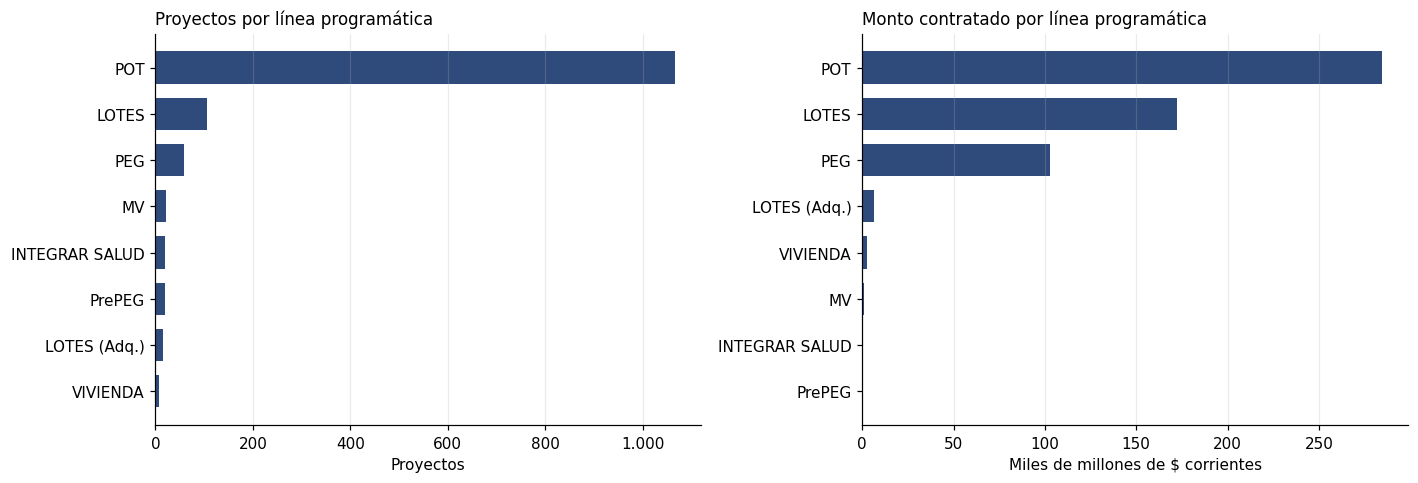

financiamiento,BID,FF,FISU,Total
linea_programatica,,,,
INTEGRAR SALUD,20,0,0,20
LOTES,0,0,106,106
LOTES (Adq.),0,0,15,15
MV,21,0,0,21
PEG,0,0,59,59
POT,9,26,1.032,1.067
PrePEG,0,20,0,20
VIVIENDA,0,3,4,7
Total,50,49,1.216,1.315


proyectos        monto_total    monto_mediano  %_monto
financiamiento linea_programatica                                                        
FISU           POT                      1032 277.970.150.288,23   133.290.291,80    48,80
               LOTES                     106 172.148.222.353,90 1.358.694.157,95    30,20
               PEG                        59 102.849.806.716,62 1.194.199.116,72    18,00
               LOTES (Adq.)               15   6.457.798.847,75   210.439.608,55     1,10
BID            POT                         9   5.963.006.105,32   537.078.730,51     1,00
FISU           VIVIENDA                    4   1.783.934.210,92   394.147.310,03     0,30
BID            MV                         21     788.493.479,96    41.984.012,55     0,10
FF             VIVIENDA                    3     744.081.353,94   272.522.404,00     0,10
               POT                        26     635.544.822,49    19.926.423,16     0,10
BID            INTEGRAR SALUD             20     609.870.000,00    35.191.500,00     0,10
FF             PrePEG                     20     228.940.988,32     4.905.800,00     0,00

In [ ]:
# 3.3 — Líneas programáticas y fuentes de financiamiento (sólo datos.gob.ar las informa)
tabla_lp = pd.crosstab(obras["linea_programatica"], obras["financiamiento"],
                       margins=True, margins_name="Total")
montos_lp = (obras.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                  .agg(proyectos="count", monto_total="sum", monto_mediano="median")
                  .sort_values("monto_total", ascending=False))
montos_lp["%_monto"] = (montos_lp["monto_total"] / montos_lp["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp, "3_linea_x_financiamiento")
guardar_tabla(montos_lp, "3_montos_por_linea")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
barras_h(axes[0], obras["linea_programatica"].value_counts(),
         "Proyectos por línea programática", "Proyectos")
barras_h(axes[1], obras.groupby("linea_programatica")["monto_total"].sum() / 1e9,
         "Monto contratado por línea programática", "Miles de millones de $ corrientes")
plt.tight_layout(); guardar_fig("3_lineas_programaticas"); plt.show()

display(tabla_lp)
montos_lp

### 3.4 Estado y avance físico

datos.gob.ar se abre por fuente de financiamiento y el Monitor por unidad ejecutora, porque el Monitor no informa financiamiento.

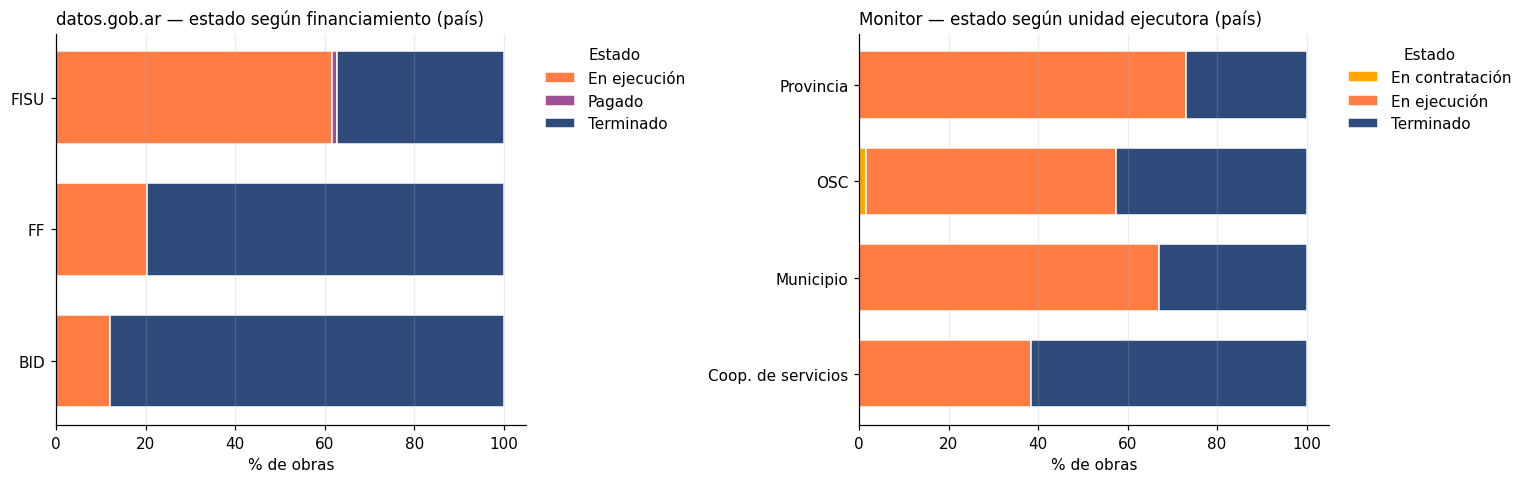

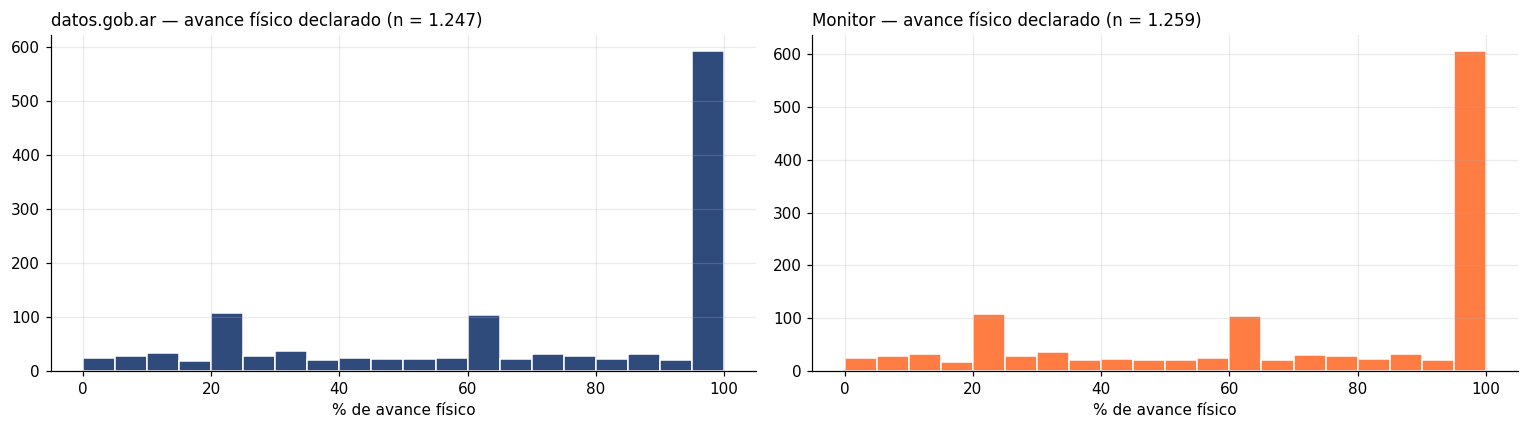

Avance físico por financiamiento (datos.gob.ar):


,count,mean,std,min,25%,50%,75%,max
financiamiento,,,,,,,,
BID,"30,0","92,4","18,7","29,4","100,0","100,0","100,0","100,0"
FF,"29,0","100,0","0,1","99,6","100,0","100,0","100,0","100,0"
FISU,"1.188,0","70,1","33,4","0,0","39,5","84,7","100,0","100,0"


Avance físico por unidad ejecutora (Monitor):


,count,mean,std,min,25%,50%,75%,max
tipo_ue,,,,,,,,
Coop. de servicios,"39,0","86,1","24,6","20,0","83,4","100,0","100,0","100,0"
Municipio,"329,0","64,3","35,5","0,0","30,8","71,0","100,0","100,0"
OSC,"809,0","74,3","31,7","0,8","52,6","100,0","100,0","100,0"
Provincia,"82,0","67,1","34,3","0,0","34,6","77,1","100,0","100,0"


Sin avance informado: datos.gob.ar 68 · Monitor 43


In [ ]:
# 3.4 — Estado y avance físico (nacional)
estado_y_avance(obras, mon_obras, "nacional", "país")

### 3.5 Unidad ejecutora — quién ejecuta la política en el territorio

In [ ]:
# 3.5 — Unidad ejecutora (nacional)
unidad_ejecutora(obras, mon_obras, "nacional")

datos.gob.ar:


financiamiento,BID,FF,FISU,Total,Monto total,Monto promedio
tipo_ue,,,,,,
OSC,41,25,772,838,"311.017.475.249,50","371.142.571,90"
Municipio,3,21,314,338,"178.915.914.980,80","529.337.026,57"
Provincia,6,3,76,85,"65.306.478.080,15","768.311.506,83"
Coop. de servicios,0,0,39,39,"8.482.182.009,25","217.491.846,39"
SIN UE,0,0,15,15,"6.457.798.847,75","430.519.923,18"


Monitor:


,obras,inversion_total,inversion_promedio,familias,%_obras,%_inversion,inversion_por_familia
tipo_ue,,,,,,,
OSC,834,"310.698.650.825,65","372.540.348,71",171.112,"64,1","55,1",1.815.762
Municipio,340,"179.160.506.427,80","526.942.665,96",101.331,"26,1","31,8",1.768.070
Provincia,89,"65.408.375.790,33","734.925.570,68",40.196,"6,8","11,6",1.627.236
Coop. de servicios,39,"8.482.182.009,25","217.491.846,39",9.372,"3,0","1,5",905.056


Composición por unidad ejecutora en las dos fuentes:


,datos.gob.ar (% proyectos),Monitor (% obras)
unidad ejecutora,,
OSC,"63,7","64,1"
Municipio,"25,7","26,1"
Provincia,"6,5","6,8"
Coop. de servicios,"3,0","3,0"
SIN UE,"1,1","0,0"


### 3.6 Distribución provincial

Jurisdicciones con obras: 23 de 24 · sin obras: Santa Cruz


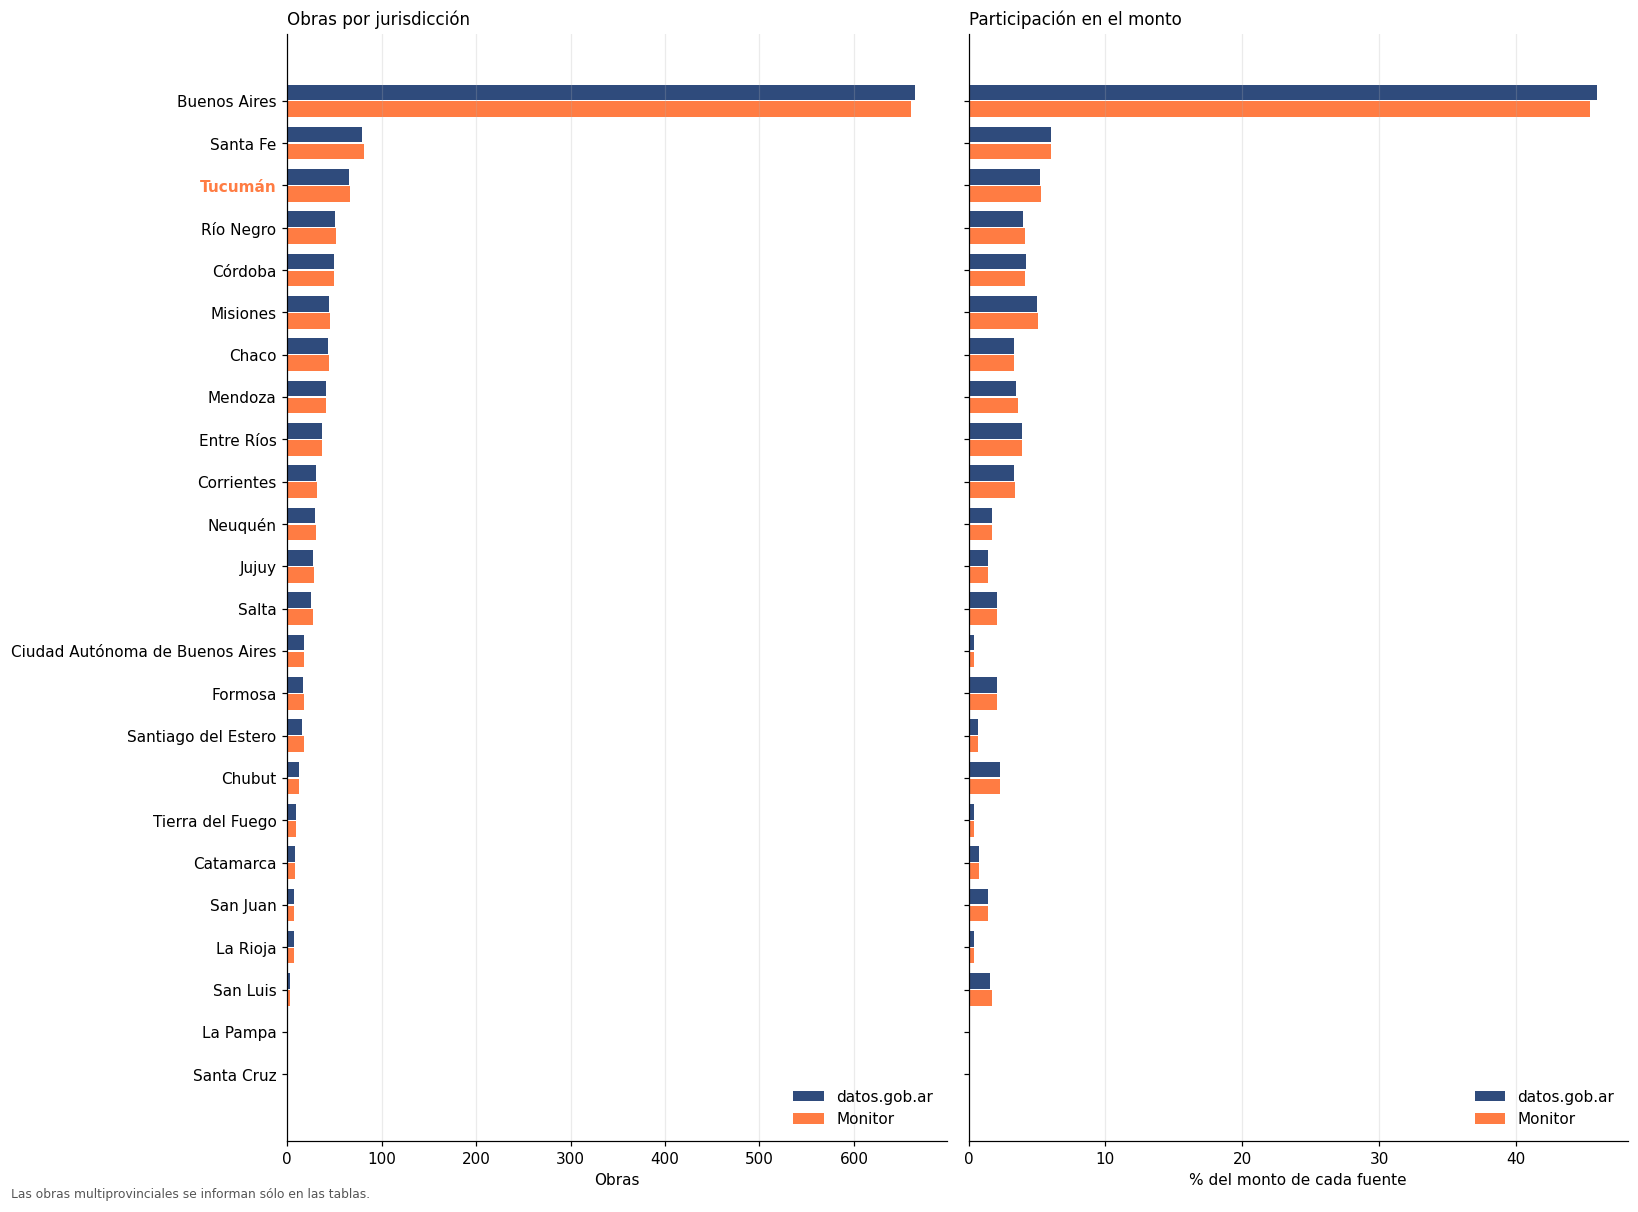

datos.gob.ar:


,proyectos,monto,%_proyectos,%_monto,barrios_alcanzados
jurisdicción,,,,,
Buenos Aires,665,"261.653.312.452,41","50,6","45,9",513
Santa Fe,79,"33.986.659.895,24","6,0","6,0",85
Tucumán,65,"29.828.793.143,24","4,9","5,2",57
Río Negro,51,"22.957.021.125,40","3,9","4,0",65
Córdoba,50,"24.177.609.891,62","3,8","4,2",34
Misiones,44,"28.627.343.224,19","3,3","5,0",46
Chaco,43,"18.658.091.575,04","3,3","3,3",38
Mendoza,41,"20.024.496.035,02","3,1","3,5",39
Entre Ríos,37,"21.968.241.671,47","2,8","3,9",32


Monitor:


,obras,monto,%_obras,%_monto,barrios_alcanzados,familias
jurisdicción,,,,,,
Buenos Aires,661,"256.154.125.105,85","50,8","45,4",513,169.729
Santa Fe,81,"34.051.225.209,23","6,2","6,0",83,23.660
Tucumán,66,"29.903.281.492,24","5,1","5,3",57,13.756
Río Negro,52,"22.980.534.036,48","4,0","4,1",65,12.457
Córdoba,50,"23.347.863.386,38","3,8","4,1",35,8.728
Misiones,45,"28.807.369.357,19","3,5","5,1",46,9.336
Chaco,44,"18.681.856.642,50","3,4","3,3",38,11.431
Mendoza,41,"20.024.496.035,01","3,1","3,6",39,4.081
Entre Ríos,37,"21.968.241.671,47","2,8","3,9",32,4.628


In [ ]:
# 3.6 — Distribución provincial de las dos fuentes (todas las jurisdicciones)
# PROVINCIAS y jurisdiccion() están en 0.3 y 0.4
def por_jurisdiccion(d, d_barrio, col_id, col_monto, etiqueta):
    d = d.assign(jurisdiccion=d["provincia"].map(jurisdiccion))
    t = (d.groupby("jurisdiccion")
          .agg(**{etiqueta: (col_id, "count"), "monto": (col_monto, "sum")})
          .reindex(PROVINCIAS + ["Multiprovincial"], fill_value=0))
    t[f"%_{etiqueta}"] = (t[etiqueta] / t[etiqueta].sum() * 100).round(1)
    t["%_monto"] = (t["monto"] / t["monto"].sum() * 100).round(1)
    t["barrios_alcanzados"] = (d_barrio.assign(jurisdiccion=d_barrio["provincia"].map(jurisdiccion))
                               .groupby("jurisdiccion")["id_renabap"].nunique()
                               .reindex(t.index, fill_value=0))
    if "familias" in d:
        t["familias"] = (d.groupby("jurisdiccion")["familias"].sum()
                          .reindex(t.index, fill_value=0).round(0).astype(int))
    t.index.name = "jurisdicción"
    # De mayor a menor, con las multiprovinciales al final
    return pd.concat([t.drop(index="Multiprovincial").sort_values(etiqueta, ascending=False),
                      t.loc[["Multiprovincial"]]])


prov = por_jurisdiccion(obras, obras_barrio, "proyecto_id", "monto_total", "proyectos")
prov_m = por_jurisdiccion(mon_obras, monitor_barrio[monitor_barrio["fuera_de_matriz"].isna()],
                          "obra_id", "inversion_total", "obras")
guardar_tabla(prov, "3_provincias_datosgobar")
guardar_tabla(prov_m, "3_provincias_monitor")

sin_obras = [p for p in PROVINCIAS if prov.loc[p, "proyectos"] == 0 and prov_m.loc[p, "obras"] == 0]
print(f"Jurisdicciones con obras: {fmt_ar(len(PROVINCIAS) - len(sin_obras))} de {fmt_ar(len(PROVINCIAS))}"
      + (f" · sin obras: {', '.join(sin_obras)}" if sin_obras else ""))

# Mismo orden en los dos paneles (según datos.gob.ar) para comparar fila a fila
orden = prov.drop(index="Multiprovincial").sort_values("proyectos").index
cant = pd.DataFrame({"datos.gob.ar": prov["proyectos"], "Monitor": prov_m["obras"]}).loc[orden]
monto = pd.DataFrame({"datos.gob.ar": prov["%_monto"], "Monitor": prov_m["%_monto"]}).loc[orden]

fig, axes = plt.subplots(1, 2, figsize=(15, 11), sharey=True)
barras_agrupadas(axes[0], cant, COLOR_FUENTE, "Obras por jurisdicción", "Obras")
barras_agrupadas(axes[1], monto, COLOR_FUENTE, "Participación en el monto", "% del monto de cada fuente")
for etiqueta in axes[0].get_yticklabels():
    if etiqueta.get_text() == "Tucumán":
        etiqueta.set_color(NARANJA); etiqueta.set_fontweight("bold")
fig.text(0.01, 0.005, "Las obras multiprovinciales se informan sólo en las tablas.", fontsize=8, color="#555555")
plt.tight_layout(); guardar_fig("3_provincias"); plt.show()

print("datos.gob.ar:"); display(prov)
print("Monitor:"); prov_m

### 3.7 Cobertura territorial — cuántos barrios alcanzaron las obras

In [ ]:
# 3.7 — Cobertura territorial de las dos fuentes de obras
s_gob, s_mon = set(obras_barrio["id_renabap"]), set(monitor_barrio["id_renabap"])
cob = pd.DataFrame({
    "registros": [len(obras), len(monitor)],
    "barrios_únicos": [len(s_gob), len(s_mon)],
}, index=pd.Index(["datos.gob.ar", "Monitor"], name="fuente"))
guardar_tabla(cob, "3_cobertura_fuentes")
print(cob.ar.to_string())
print(f"\nBarrios en ambas fuentes: {fmt_ar(len(s_gob & s_mon))} · "
      f"sólo datos.gob.ar: {fmt_ar(len(s_gob - s_mon))} · sólo Monitor: {fmt_ar(len(s_mon - s_gob))}")

             registros barrios_únicos
fuente                               
datos.gob.ar     1.315          1.224
Monitor          1.322          1.224

Barrios en ambas fuentes: 1.223 · sólo datos.gob.ar: 1 · sólo Monitor: 1


### 3.8 Tipo, subdimensión, dimensión y escala

Las tablas multietiqueta (tipo, subdimensión, dimensión) no suman 100 %: una obra cuenta en todas las categorías que activa. La dimensión principal y la escala son excluyentes. Planificación aparece en una fila aparte porque no es una dimensión de las intervenciones.

La escala es una lectura de referencia a gran escala, inferida del nombre de la obra: no reemplaza el estudio caso por caso.

In [ ]:
# 3.8 — Clasificación F3 a escala nacional, las dos fuentes
FUENTES_NAC = {"datos.gob.ar": obras, "Monitor": monitor}
F3_NAC = tablas_f3(FUENTES_NAC, "nacional")
mostrar_f3(F3_NAC)


TIPO de intervención (multietiqueta, no suma 100 %)


datos.gob.ar                          Monitor                         
                                     obras     %              monto   obras     %              monto
tipo de intervención                                                                                
Infraestructura de servicios           870 67,20 423.305.158.866,28     837 64,30 329.432.869.657,30
Movilidad y accesibilidad              560 43,20 224.149.973.918,53     651 50,00 300.053.666.286,38
Conexiones intradomiciliarias          501 38,70 102.574.504.157,02       2  0,20     218.017.634,54
Equipamiento comunitario               360 27,80 158.835.844.798,64     351 27,00 174.737.845.161,52
Espacio público                        325 25,10  93.830.499.403,69     143 11,00  75.086.114.066,63
Suelo y regularización                 152 11,70 221.886.392.132,92     154 11,80 231.461.727.757,80
Vivienda                               103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Ambiente                                33  2,50  29.760.577.536,72      20  1,50  21.638.108.033,23
Planificación / proyecto                21  1,60   2.270.342.386,38      20  1,50     228.940.988,32
Sin especificar (genéricos)              0  0,00               0,00      10  0,80     643.840.280,72


SUBDIMENSIÓN (multietiqueta)


datos.gob.ar                          Monitor                         
                                                          obras     %              monto   obras     %              monto
subdimensión                                                                                                             
Servicios básicos y energía (Infraestructuras)              856 66,10 412.777.032.141,11     836 64,20 329.393.402.271,07
Movilidad y conectividad (Infraestructuras)                 667 51,50 370.618.790.854,61     652 50,10 300.093.133.672,61
Espacio público, deporte y cultura (Equipamiento)           355 27,40 121.947.420.296,05     274 21,00 145.766.431.674,46
Administración y bienestar (Equipamiento)                   302 23,30 122.276.709.238,10     164 12,60  84.522.991.832,28
Producción de suelo urbanizado (Situación domin...          148 11,40 215.946.360.186,90     154 11,80 231.461.727.757,80
Mejoramiento y provisión de vivienda (Vivienda)             103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Condiciones ambientales (Calidad ambiental)                  29  2,20  31.215.660.942,53      20  1,50  21.638.108.033,23
Planificación y proyecto (Planificación)                     21  1,60   2.270.342.386,38      20  1,50     228.940.988,32
Salud y educación (Equipamiento)                             18  1,40  14.597.419.509,74      33  2,50  25.012.325.720,32
Servicios y consumo (Equipamiento)                           17  1,30  12.337.808.230,76      12  0,90   7.544.439.344,26
Regularización y seguridad en la tenencia (Situ...           10  0,80   7.596.955.675,36      17  1,30   2.591.228.070,87


DIMENSIÓN (multietiqueta)


datos.gob.ar                          Monitor                         
                                   obras     %              monto   obras     %              monto
dimensión                                                                                         
Infraestructuras                    1042 80,50 456.565.837.110,83    1021 78,40 361.593.808.468,99
Equipamiento                         496 38,30 185.531.005.656,00     375 28,80 178.971.664.233,23
Situación dominial                   152 11,70 221.886.392.132,92     154 11,80 231.461.727.757,80
Vivienda                             103  8,00  81.742.400.049,79     128  9,80  88.222.918.491,94
Calidad ambiental                     29  2,20  31.215.660.942,53      20  1,50  21.638.108.033,23
Planificación (paso previo)           21  1,60   2.270.342.386,38      20  1,50     228.940.988,32


DIMENSIÓN PRINCIPAL (suma 100 %)


datos.gob.ar       Monitor      
                           obras     %   obras     %
dimensión principal                                 
Infraestructuras        1.042,00 80,50    1021 78,40
Equipamiento              171,00 13,20     121  9,30
Vivienda                   26,00  2,00      42  3,20
Situación dominial         20,00  1,50      78  6,00
Planificación              20,00  1,50      19  1,50
Calidad ambiental          16,00  1,20      11  0,80
Sin especificar             0,00  0,00      10  0,80


ESCALA (suma 100 %) y cuántas quedan a verificar


datos.gob.ar                   Monitor                  
                      obras     % a verificar   obras     % a verificar
escala                                                                 
barrial                1065 82,20         253    1137 87,30         151
comunitaria             148 11,40           4     108  8,30          88
ambas                    62  4,80          25      29  2,20          12
sin determinar           20  1,50          20      28  2,20          28

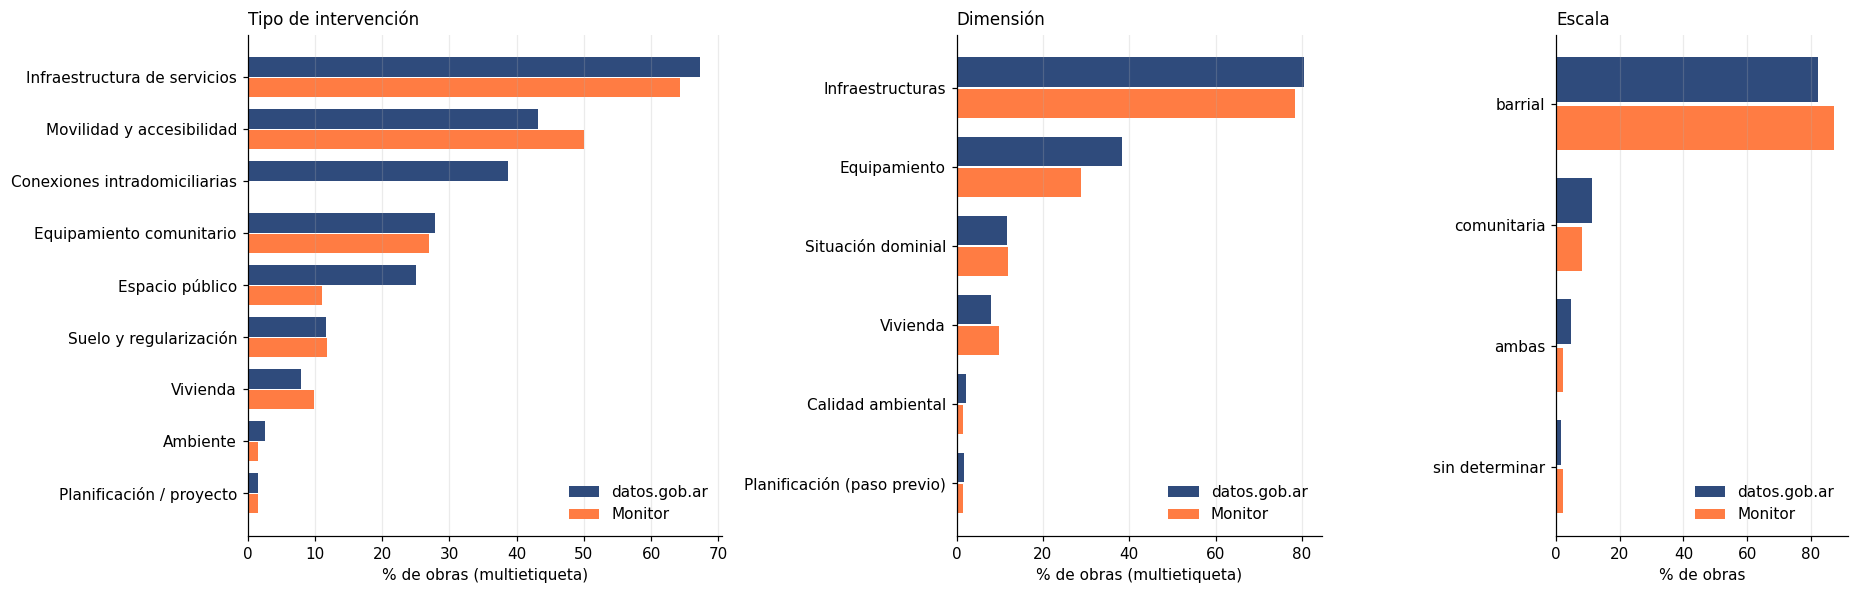

In [ ]:
# 3.8 (gráfico) — Composición por tipo, dimensión y escala en las dos fuentes
def pct(T, k, quitar=()):
    t = T[k].xs("%", axis=1, level=1).drop(index=list(quitar), errors="ignore")
    return t.iloc[::-1]


fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 0.8]})
barras_agrupadas(axes[0], pct(F3_NAC, "tipo", ["Sin especificar (genéricos)"]), COLOR_FUENTE,
                 "Tipo de intervención", "% de obras (multietiqueta)")
barras_agrupadas(axes[1], pct(F3_NAC, "dimension"), COLOR_FUENTE,
                 "Dimensión", "% de obras (multietiqueta)")
barras_agrupadas(axes[2], pct(F3_NAC, "escala"), COLOR_FUENTE, "Escala", "% de obras")
plt.tight_layout(); guardar_fig("3_f3_nacional"); plt.show()

### 3.9 Control de la clasificación

Herramientas de auditoría del esquema F3. Cada una exporta su planilla de trabajo a `salidas/tablas/`.

#### 3.9.1 Chequeos estructurales del vocabulario

In [ ]:
# 3.9.1 — Chequeos estructurales: se corren antes de mirar los datos
# Un patrón que está en EJES y en ninguna subdimensión produce obras con tipo y sin dimensión
patrones_sub = {p for cfg in SUBDIMENSIONES.values() for p in cfg["patrones"]}
huerfanos = {e: [p for p in ps if p not in patrones_sub] for e, ps in EJES.items()}
print("Patrones de EJES ausentes de toda subdimensión:")
for e, ps in huerfanos.items():
    if ps:
        print(f"  {EJES_ETIQUETA[e]:32s} -> {ps}")

# Un desajuste de nombre entre DIMENSIONES y SUBDIMENSIONES no da error: da columnas vacías
declaradas = {c["dimension"] for c in SUBDIMENSIONES.values()}
print("\nDimensiones listadas sin subdimensión:", [d for d in DIMENSIONES if d not in declaradas] or "ninguna")
print("Dimensiones usadas y no listadas      :",
      [d for d in declaradas if d not in DIMENSIONES and d != "Planificación"] or "ninguna")

Patrones de EJES ausentes de toda subdimensión:
  Ambiente                         -> ['saneamiento hidraulico']

Dimensiones listadas sin subdimensión: ninguna
Dimensiones usadas y no listadas      : ninguna


#### 3.9.2 Coherencia entre tipo y dimensión principal

In [ ]:
# 3.9.2 — Coherencia entre capas: tipo principal × dimensión principal
for f, d in FUENTES_NAC.items():
    coh = pd.crosstab(d["eje_principal"].map(lambda e: EJES_ETIQUETA.get(e, e)), d["dimension_principal"])
    guardar_tabla(coh, f"3_coherencia_tipo_dimension_{norm_texto(f).replace('.', '')}")
    print(f"\n{f}:")
    display(coh)


datos.gob.ar:


dimension_principal,Calidad ambiental,Equipamiento,Infraestructuras,Planificación,Sin clasificar,Situación dominial,Vivienda
eje_principal,,,,,,,
Ambiente,16,7,0,0,0,0,0
Conexiones intradomiciliarias,0,0,9,0,0,0,0
Equipamiento comunitario,0,92,0,0,0,0,0
Espacio público,0,72,0,0,0,0,0
Infraestructura de servicios,0,0,870,0,0,0,0
Movilidad y accesibilidad,0,0,163,0,0,0,0
Planificación / proyecto,0,0,0,20,0,0,0
Suelo y regularización,0,0,0,0,0,20,0
Vivienda,0,0,0,0,0,0,26



Monitor:


dimension_principal,Calidad ambiental,Equipamiento,Infraestructuras,Planificación,Sin clasificar,Sin especificar,Situación dominial,Vivienda
eje_principal,,,,,,,,
Ambiente,11,2,0,0,0,0,0,0
Equipamiento comunitario,0,74,0,0,0,0,0,0
Espacio público,0,45,0,0,0,0,0,0
Infraestructura de servicios,0,0,837,0,0,0,0,0
Movilidad y accesibilidad,0,0,184,0,0,0,0,0
Planificación / proyecto,0,0,0,19,0,0,0,0
Suelo y regularización,0,0,0,0,0,0,75,0
Vivienda,0,0,0,0,0,0,3,42
sin_clasificar,0,0,0,0,20,0,0,0


#### 3.9.3 Obras sin clasificar

In [ ]:
# 3.9.3 — Obras sin tipo o sin dimensión, para revisión manual
def sin_clasificar(d, fuente, col_nombre, col_id):
    sin_tipo = (d["eje_principal"] == "sin_clasificar") & ~d["sin_especificar"]
    sin_dim = d["dimension_principal"] == "Sin clasificar"
    rev = d[sin_tipo | sin_dim].copy()
    rev["situacion"] = np.select([sin_tipo[rev.index] & sin_dim[rev.index], sin_tipo[rev.index]],
                                 ["sin tipo y sin dimensión", "sin tipo, con dimensión"],
                                 default="con tipo, sin dimensión")
    rev.loc[rev["fuera_de_matriz"].notna(), "situacion"] = "fuera de matriz: " + rev["fuera_de_matriz"]
    rev["texto_clasificado"] = rev[col_nombre].map(norm_patron)
    for c in ["tipo_correcto", "dimension_correcta", "patron_a_agregar", "observaciones"]:
        rev[c] = ""
    cols = [c for c in [col_id, "situacion", "provincia", "municipio", "barrio", "id_renabap_raw",
                        "linea_programatica", col_nombre, "texto_clasificado", "estado",
                        "tipo_correcto", "dimension_correcta", "patron_a_agregar", "observaciones"]
            if c in rev.columns]
    rev = rev[cols].sort_values(["situacion", col_nombre])
    guardar_tabla(rev.set_index(col_id), f"3_sin_clasificar_{norm_texto(fuente).replace('.', '')}")
    print(f"{fuente}: {fmt_ar(len(rev))} obras a revisar de {fmt_ar(len(d))}")
    display(rev["situacion"].value_counts().to_frame("obras"))
    return rev


rev_gob = sin_clasificar(obras, "datos.gob.ar", "nombre_proyecto", "proyecto_id")
rev_mon = sin_clasificar(monitor, "Monitor", "nombre_obra", "obra_id")
print("Genéricos detectados en datos.gob.ar (muestra):")
obras.loc[obras["sin_especificar"], "nombre_proyecto"].value_counts().head(10).to_frame("proyectos")

datos.gob.ar: 20 obras a revisar de 1.315


,obras
situacion,
fuera de matriz: Fortalecimiento comunitario COVID-19,20


Monitor: 20 obras a revisar de 1.322


,obras
situacion,
fuera de matriz: Fortalecimiento comunitario COVID-19,20


Genéricos detectados en datos.gob.ar (muestra):


,proyectos
nombre_proyecto,


#### 3.9.4 Control por dimensión

Para cada dimensión y fuente: qué patrón la dispara, si es principal o secundaria, y las **discordancias** entre tipo y dimensión principal. El detalle se exporta; con `detalle=True` se muestra en pantalla.

In [ ]:
# 3.9.4 — Control de cada dimensión en las dos fuentes
def resumen_patrones(serie_texto, patrones):
    txt = serie_texto.map(norm_patron).fillna("")
    r = pd.DataFrame({"patrón": patrones,
                      "obras": [int(txt.str.contains(p, regex=True, na=False).sum()) for p in patrones]})
    return r.sort_values("obras", ascending=False).set_index("patrón")


def inspeccionar_dimension(DIM, df, fuente, col_nombre, col_id, detalle=False):
    subs = [s for s, c in SUBDIMENSIONES.items() if c["dimension"] == DIM]
    pat_dim = list(dict.fromkeys(p for s in subs for p in SUBDIMENSIONES[s]["patrones"]))
    pat_tipo = list(dict.fromkeys(p for t, d in TIPO_A_DIM.items() if d == DIM for p in EJES[t]))
    slug = norm_texto(f"{DIM} {fuente}").replace(" ", "_").replace(".", "")

    sel = df[df[f"dim_{DIM}"]].copy()
    sel["patrones_dimension"] = patrones_disparados(sel[col_nombre], pat_dim)
    esperada = df["eje_principal"].map(TIPO_A_DIM)
    disc = pd.concat([
        df[(esperada == DIM) & (df["dimension_principal"] != DIM)].assign(discordancia="tipo sí, dimensión no"),
        df[(df["dimension_principal"] == DIM) & (esperada != DIM) & df["eje_principal"].isin(TIPO_A_DIM)]
          .assign(discordancia="dimensión sí, tipo no")])
    disc["patrones_tipo"] = patrones_disparados(disc[col_nombre], pat_tipo)
    disc["patrones_dimension"] = patrones_disparados(disc[col_nombre], pat_dim)

    cols = [c for c in [col_id, "provincia", "municipio", "linea_programatica", col_nombre,
                        "patrones_dimension", "eje_principal", "subdimension_principal",
                        "dimension_principal", "escala"] if c in sel.columns]
    guardar_tabla(sel[cols].set_index(col_id), f"3_control_dim_{slug}")
    cols_d = [c for c in [col_id, "discordancia", "linea_programatica", col_nombre, "eje_principal",
                          "patrones_tipo", "dimension_principal", "patrones_dimension"] if c in disc.columns]
    guardar_tabla(disc[cols_d].set_index(col_id), f"3_discordancias_dim_{slug}")

    if detalle:
        print(f"DIMENSIÓN: {DIM} | FUENTE: {fuente}")
        display(resumen_patrones(df[col_nombre], pat_dim))
        display(sel["dimension_principal"].value_counts().to_frame("obras"))
        print("En el tipo y no en la dimensión:", [p for p in pat_tipo if p not in pat_dim] or "ninguno")
        print("En la dimensión y no en el tipo:", [p for p in pat_dim if p not in pat_tipo] or "ninguno")
        display(disc[cols_d].head(40)) if len(disc) else print("Sin discordancias entre tipo y dimensión.")
    return pd.Series({"obras con la dimensión": len(sel),
                      "como principal": int((df["dimension_principal"] == DIM).sum()),
                      "tipo sí, dimensión no": int((disc["discordancia"] == "tipo sí, dimensión no").sum()),
                      "dimensión sí, tipo no": int((disc["discordancia"] == "dimensión sí, tipo no").sum())})


PARAM_FUENTE = {"datos.gob.ar": dict(df=obras, col_nombre="nombre_proyecto", col_id="proyecto_id"),
                "Monitor": dict(df=monitor, col_nombre="nombre_obra", col_id="obra_id")}
control_dim = pd.DataFrame({(f, DIM): inspeccionar_dimension(DIM, fuente=f, **p)
                            for f, p in PARAM_FUENTE.items() for DIM in DIMENSIONES}).T
control_dim.index.names = ["fuente", "dimensión"]
guardar_tabla(control_dim, "3_control_dimensiones_resumen")
control_dim

obras con la dimensión  como principal  tipo sí, dimensión no  dimensión sí, tipo no
fuente       dimensión                                                                                               
datos.gob.ar Infraestructuras                      1042            1042                      0                      0
             Equipamiento                           496             171                      0                      7
             Calidad ambiental                       29              16                      7                      0
             Situación dominial                     152              20                      0                      0
             Vivienda                               103              26                      0                      0
Monitor      Infraestructuras                      1021            1021                      0                      0
             Equipamiento                           375             121                      0                      2
             Calidad ambiental                       20              11                      2                      0
             Situación dominial                     154              78                      0                      3
             Vivienda                               128              42                      3                      0

In [ ]:
# 3.9.4 (detalle) — Para mirar una dimensión en pantalla, cambiar DIM y FUENTE
DIM, FUENTE = "Situación dominial", "datos.gob.ar"
_ = inspeccionar_dimension(DIM, fuente=FUENTE, detalle=True, **PARAM_FUENTE[FUENTE])

DIMENSIÓN: Situación dominial | FUENTE: datos.gob.ar


,obras
patrón,
(?<!intra )(?<!intra-)(?<!intra)\blote,115
lotes? con servicios,108
adquisicion de predio,62
adquisicion de tierra,26
tierra privada,26
loteo,6
mensura,3
dominial,1
regularizacion,1


,obras
dimension_principal,
Infraestructuras,132
Situación dominial,20


En el tipo y no en la dimensión: ninguno
En la dimensión y no en el tipo: ['regularizacion', 'lotes? con servicios', 'adquisicion de predio']
Sin discordancias entre tipo y dimensión.


#### 3.9.5 Control de la escala

La escala se asigna en tres pasos: (1) expresión diagnóstica en el nombre → **confirmada**; (2) sin expresión, escala por defecto de las subdimensiones → **inferida**; (3) ni lo uno ni lo otro → **sin determinar**. La planilla de revisión ordena las obras por prioridad.

In [ ]:
# 3.9.5 — Control de la escala: origen, expresiones que la disparan y planilla de revisión
def origen_escala(d):
    no_aplica = (d["subdimension_principal"] == "instrumento_planificacion") & (d["escala"] == "sin determinar")
    return np.select(
        [d["fuera_de_matriz"].notna(), d["sin_especificar"], no_aplica,
         ~d["escala_verificar"], d["escala"] == "sin determinar"],
        ["fuera de matriz", "genérico", "no aplica (planificación)",
         "confirmada por expresión", "sin determinar"],
        default="inferida por subdimensión")


PRIORIDAD_ESCALA = ["1 · sin determinar", "2 · ambas por expresión",
                    "3 · inferida con subdimensiones en conflicto", "4 · inferida por subdimensión"]


def revisar_escala(df, fuente, col_nombre, col_id):
    d = df.copy()
    d["origen_escala"] = origen_escala(d)
    slug = norm_texto(fuente).replace(".", "")
    origen = pd.crosstab(d["escala"], d["origen_escala"], margins=True, margins_name="Total")

    txt = d[col_nombre].map(norm_patron).fillna("")
    expresiones = pd.DataFrame([{"escala": k, "patrón": p,
                                 "obras": int(txt.str.contains(p, regex=True, na=False).sum())}
                                for k, pats in GRUPOS_ESCALA.items() for p in pats]
                               ).set_index(["escala", "patrón"])

    d["prioridad_escala"] = np.select(
        [d["origen_escala"] == "sin determinar",
         (d["origen_escala"] == "confirmada por expresión") & (d["escala"] == "ambas"),
         (d["origen_escala"] == "inferida por subdimensión") & (d["escala"] == "ambas"),
         d["origen_escala"] == "inferida por subdimensión"],
        PRIORIDAD_ESCALA, default="")
    rev = d[d["prioridad_escala"] != ""].copy()
    rev["patrones_escala"] = patrones_escala(rev[col_nombre])
    rev["subdimensiones (escala por defecto)"] = rev.apply(
        lambda r: "; ".join(f"{SUBDIMENSIONES[s]['etiqueta']} ({ESCALA_DEFECTO[s]})"
                            for s in SUBDIMENSIONES if r[f"sub_{s}"]), axis=1)
    for c in ["escala_correcta", "fuente_de_verificacion", "observaciones"]:
        rev[c] = ""
    cols = [c for c in [col_id, "prioridad_escala", "provincia", "municipio", "barrio",
                        "linea_programatica", col_nombre, "dimension_principal",
                        "subdimensiones (escala por defecto)", "patrones_escala", "escala",
                        "escala_correcta", "fuente_de_verificacion", "observaciones"] if c in rev.columns]
    rev = rev[cols].sort_values(["prioridad_escala", col_nombre])

    guardar_tabla(origen, f"3_escala_origen_{slug}")
    guardar_tabla(expresiones, f"3_escala_expresiones_{slug}")
    guardar_tabla(rev.set_index(col_id), f"3_escala_revision_{slug}")
    print(f"===== {fuente} =====\nEscala según cómo se llegó a ella:")
    display(origen)
    print("Expresiones que no activan ninguna obra:",
          expresiones[expresiones["obras"] == 0].index.get_level_values("patrón").tolist() or "ninguna")
    print(f"Obras a revisar: {fmt_ar(len(rev))} ({fmt_ar(len(rev) / len(d) * 100, 1)} %)")
    display(rev["prioridad_escala"].value_counts().sort_index().to_frame("obras"))
    return rev


rev_esc = {f: revisar_escala(fuente=f, **p) for f, p in PARAM_FUENTE.items()}

===== datos.gob.ar =====
Escala según cómo se llegó a ella:


origen_escala,confirmada por expresión,fuera de matriz,inferida por subdimensión,no aplica (planificación),Total
escala,,,,,
ambas,37,0,25,0,62
barrial,812,0,253,0,1.065
comunitaria,144,0,4,0,148
sin determinar,0,20,0,20,40
Total,993,20,282,20,1.315


Expresiones que no activan ninguna obra: ['calles? intern', 'troncal', 'arroyo', '\\bcaps\\b', 'adquisicion de tierras']
Obras a revisar: 319 (24,3 %)


,obras
prioridad_escala,
2 · ambas por expresión,37
3 · inferida con subdimensiones en conflicto,25
4 · inferida por subdimensión,257


===== Monitor =====
Escala según cómo se llegó a ella:


origen_escala,confirmada por expresión,fuera de matriz,genérico,inferida por subdimensión,no aplica (planificación),Total
escala,,,,,,
ambas,17,0,0,12,0,29
barrial,986,0,0,151,0,1.137
comunitaria,20,0,0,88,0,108
sin determinar,0,20,10,0,18,48
Total,1.023,20,10,251,18,1.322


Expresiones que no activan ninguna obra: ['intra[- ]?lote', 'intra[- ]?domiciliar', 'intra[- ]?conexion', 'instalaciones intra', 'intras? (?:de )?(?:electric|agua|cloaca|sanitari)', 'conexiones domiciliar', 'mejora(miento)? de vivienda', 'refaccion', 'red peatonal', 'pasillos?', 'red vial', 'calles? intern', 'extension de red', '\\bnexo', 'colectora', 'troncal', 'cauce', 'defensa', 'encauzamiento', 'saneamiento hidraulico', 'planta de (?:separacion|tratamiento)', 'acceso al barrio', 'cepla', 'centro de atencion primaria', '\\bcaps\\b', 'escuela', 'sanitario', 'adquisicion de tierras', 'tierra privada', 'relocalizacion']
Obras a revisar: 268 (20,3 %)


,obras
prioridad_escala,
2 · ambas por expresión,17
3 · inferida con subdimensiones en conflicto,12
4 · inferida por subdimensión,239


#### 3.9.6 Auditoría de escala — obras sin escala definida

Registros que quedan con escala *sin determinar* y por qué. Son los que no entran en ninguna lectura de escala; se listan completos para revisarlos uno por uno.

In [ ]:
# 3.9.6 — Auditoría de escala: obras que quedan sin escala definida
MOTIVO_SIN_ESCALA = {
    "genérico": "nombre genérico, sin componentes declarados",
    "no aplica (planificación)": "planificación: no produce impacto territorial",
    "fuera de matriz": "acción fuera de matriz (COVID-19)",
    "sin determinar": "ninguna expresión ni subdimensión la define",
}


def auditar_escala(fuentes, sufijo):
    """Lista, por fuente, las obras con escala 'sin determinar' y el motivo."""
    partes = []
    for f, d in fuentes.items():
        col_id, col_nombre = PARAM_FUENTE[f]["col_id"], PARAM_FUENTE[f]["col_nombre"]
        s = d[d["escala"] == "sin determinar"]
        partes.append(pd.DataFrame({
            "fuente": f, "id": s[col_id], "provincia": s["provincia"], "municipio": s["municipio"],
            "barrios": s["id_renabap_raw"],
            "linea_programatica": s["linea_programatica"] if "linea_programatica" in s else np.nan,
            "nombre": s[col_nombre], "dimension_principal": s["dimension_principal"],
            "motivo": pd.Series(origen_escala(s), index=s.index).map(MOTIVO_SIN_ESCALA)}))
    t = pd.concat(partes, ignore_index=True).sort_values(["fuente", "motivo", "nombre"])
    resumen = pd.crosstab(t["motivo"], t["fuente"], margins=True, margins_name="Total")
    totales = {f: len(d) for f, d in fuentes.items()}
    resumen.loc["obras de la fuente"] = [totales.get(c, sum(totales.values())) for c in resumen.columns]
    guardar_tabla(resumen, f"escala_sin_definir_resumen_{sufijo}")
    guardar_tabla(t.set_index("id"), f"escala_sin_definir_{sufijo}")
    print("Obras sin escala definida, según motivo:")
    display(resumen)
    print(f"Detalle ({fmt_ar(len(t))} registros):")
    display(t)
    return t


sin_escala_nac = auditar_escala(FUENTES_NAC, "nacional")

Obras sin escala definida, según motivo:


fuente,Monitor,datos.gob.ar,Total
motivo,,,
acción fuera de matriz (COVID-19),20,20,40
"nombre genérico, sin componentes declarados",10,0,10
planificación: no produce impacto territorial,18,20,38
Total,48,40,88
obras de la fuente,1.322,1.315,2.637


Detalle (88 registros):


,fuente,id,provincia,municipio,barrios,linea_programatica,nombre,dimension_principal,motivo
41,Monitor,M01260,Varios,Varios,1169/1412,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
42,Monitor,M01261,Varios,Varios,1033/1090/1107/2549/2567/2570/2575/2577/2597/2932/2934,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
43,Monitor,M01262,Varios,Varios,74/162/334/437/508/645/754/796/1078/1305,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
44,Monitor,M01263,Varios,Varios,509/819/1157/1168/1469/4295/4591,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
47,Monitor,M01266,Varios,Varios,397/543/1560/2278/2297/2392/2987,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
36,datos.gob.ar,P01310,Santa Fe,Rosario/Santa Fe/Baigorria/Villa Gobernador Gálvez,1909/1786/1853/1832/2987/3040/1794/1775/1840/1776,PrePEG,Diseño de un Proyecto Ejecutivo Integral,Planificación,planificación: no produce impacto territorial
37,datos.gob.ar,P01311,Buenos Aires,Almirante Brown,337/483/154/1341/1167/1088/4501/1495/128/2943/1402,PrePEG,Diseño de un Proyecto Ejecutivo Integral,Planificación,planificación: no produce impacto territorial
38,datos.gob.ar,P01312,Río Negro,Cinco Saltos,2532,PrePEG,Diseño de un Proyecto Ejecutivo Integral,Planificación,planificación: no produce impacto territorial
39,datos.gob.ar,P01313,Río Negro,El Bolsón,3728/3729/3753/3730/3744/3745/4466,PrePEG,Diseño de un Proyecto Ejecutivo Integral,Planificación,planificación: no produce impacto territorial
20,datos.gob.ar,P01266,Buenos Aires,San Isidro,397/1174/1251/2939/1261/545/2937/2880/2938,PrePEG,Diseño de un proyecto ejecutivo general para la urbanización de barrios en el municipio de San Isidro,Planificación,planificación: no produce impacto territorial


### 3.10 Tabla maestra barrio–obra y convergencia entre fuentes

Formato largo: una fila por par barrio–obra de cada fuente. Es la base para cruzar con el resto de las tablas por `id_renabap`. La convergencia compara, barrio por barrio, qué registra cada fuente.

In [ ]:
# 3.10 — Tabla maestra barrio–obra (formato largo)
REF_COLS = {"2023": {"nombre_barrio": "nombre_barrio", "localidad": "localidad", "provincia": "provincia"},
            "2022": {"nombre_barrio": "Nombre del barrio", "localidad": "Localidad",
                     "provincia": "Nombre de provincia"},
            "2018": {"nombre_barrio": "Nombre del barrio", "localidad": "Localidad"}}

ids_todos = sorted(set(obras_barrio["id_renabap"]) | set(monitor_barrio["id_renabap"]) | IDS_AMT)
ref_barrios = pd.DataFrame(index=pd.Index(ids_todos, name="id_renabap"),
                           columns=["nombre_barrio", "provincia", "localidad"], dtype=object)
for anio in ("2023", "2022", "2018"):          # el primero tiene prioridad
    d = amt[anio].drop_duplicates("id_renabap").set_index("id_renabap")
    for destino, origen in REF_COLS[anio].items():
        if origen in d.columns:
            ref_barrios[destino] = ref_barrios[destino].combine_first(d[origen])
ref_barrios.loc[ref_barrios.index.isin(IDS_AMT), "provincia"] = \
    ref_barrios.loc[ref_barrios.index.isin(IDS_AMT), "provincia"].fillna("Tucumán")


def _primer_valor(s):
    s = s.dropna()
    return s.iloc[0] if len(s) else np.nan


# Fuera del AMT, nombre y localidad salen de lo que declara la fuente de obra
ref_barrios = (ref_barrios
               .combine_first(obras_barrio.groupby("id_renabap")[["barrio", "provincia", "localidad"]]
                              .agg(_primer_valor).rename(columns={"barrio": "nombre_barrio"}))
               .combine_first(monitor_barrio.groupby("id_renabap")[["barrio", "provincia"]]
                              .agg(_primer_valor).rename(columns={"barrio": "nombre_barrio"})))


def _secundarios(d, prefijo, col_principal):
    cols = [c for c in d.columns if c.startswith(prefijo) and d[c].dtype == bool]
    return d.apply(lambda r: "; ".join(sorted(c[len(prefijo):] for c in cols
                                              if r[c] and c[len(prefijo):] != r[col_principal])), axis=1)


COLS_MAESTRA = ["par_id", "id_renabap", "nombre_barrio", "provincia", "localidad", "en_amt",
                "fuente", "obra_id", "nombre_obra", "linea_programatica", "tipo_ue", "estado",
                "avance_fisico", "monto_declarado", "tipo_principal", "tipos_secundarios",
                "dimension_principal", "dimensiones_secundarias", "escala", "escala_verificar",
                "sin_especificar", "n_barrios", "id_provisorio"]


def a_largo(d, fuente, col_nombre, col_obra_id, col_monto):
    d = d.copy()
    d["fuente"], d["obra_id"] = fuente, d[col_obra_id]
    d["nombre_obra"], d["monto_declarado"] = d[col_nombre], d[col_monto]
    if "linea_programatica" not in d:
        d["linea_programatica"] = np.nan
    d["tipos_secundarios"] = _secundarios(d, "eje_", "eje_principal")
    d["dimensiones_secundarias"] = _secundarios(d, "dim_", "dimension_principal")
    d = d.rename(columns={"eje_principal": "tipo_principal"})
    d["par_id"] = d["obra_id"] + "-" + d["id_renabap"]
    d["en_amt"] = d["id_renabap"].isin(IDS_AMT)
    d = d.drop(columns=["provincia", "localidad"], errors="ignore").merge(
        ref_barrios, left_on="id_renabap", right_index=True, how="left")
    return d[COLS_MAESTRA]


maestra = pd.concat([a_largo(obras_barrio, "datos.gob.ar", "nombre_proyecto", "proyecto_id", "monto_total"),
                     a_largo(monitor_barrio, "Monitor", "nombre_obra", "obra_id", "inversion_total")],
                    ignore_index=True).sort_values(["id_renabap", "fuente", "obra_id"]).reset_index(drop=True)

print(f"Tabla maestra: {fmt_ar(len(maestra))} pares · barrios: {fmt_ar(maestra['id_renabap'].nunique())} "
      f"· en el AMT: {fmt_ar(maestra.loc[maestra['en_amt'], 'id_renabap'].nunique())}")
print(f"par_id duplicados: {fmt_ar(maestra['par_id'].duplicated().sum())} (esperado 0) · "
      f"sin nombre de barrio: {fmt_ar(maestra['nombre_barrio'].isna().sum())}")
guardar_tabla(maestra.set_index("par_id"), "3_maestra_barrio_obra")
guardar_tabla(obras.loc[obras["sin_id"], ["proyecto_id", "provincia", "municipio", "localidad",
                                          "nombre_proyecto", "linea_programatica", "monto_total"]]
              .set_index("proyecto_id"), "3_proyectos_sin_barrio")
maestra.head(6)

Tabla maestra: 3.472 pares · barrios: 1.225 · en el AMT: 41
par_id duplicados: 0 (esperado 0) · sin nombre de barrio: 0


,par_id,id_renabap,nombre_barrio,provincia,localidad,en_amt,fuente,obra_id,nombre_obra,linea_programatica,tipo_ue,estado,avance_fisico,monto_declarado,tipo_principal,tipos_secundarios,dimension_principal,dimensiones_secundarias,escala,escala_verificar,sin_especificar,n_barrios,id_provisorio
0,M01125-1001,1001,Villa Nueva,Buenos Aires,Berisso,False,Monitor,M01125,Veredas en Villa Nueva/Villa Arguello,NaN,OSC,En ejecución,"20,25","209.253.307,70",movilidad_accesibilidad,,Infraestructuras,,barrial,False,False,2,False
1,M01227-1001,1001,Villa Nueva,Buenos Aires,Berisso,False,Monitor,M01227,Centro comunitario + Centro de recreación y deporte en Villa Nueva,NaN,Municipio,En ejecución,"6,09","339.533.741,64",espacio_publico,equipamiento_comunitario,Equipamiento,,barrial,True,False,1,False
2,P00159-1001,1001,Villa Nueva,Buenos Aires,Berisso,False,datos.gob.ar,P00159,Construcción de Equipamiento Comunitario,POT,Municipio,En ejecución,"6,09","339.533.741,64",equipamiento_comunitario,,Equipamiento,,barrial,True,False,1,False
3,P00701-1001,1001,Villa Nueva,Buenos Aires,Berisso,False,datos.gob.ar,P00701,Obras de red peatonal y equipamiento urbano,POT,OSC,En ejecución,"20,25","209.253.307,70",movilidad_accesibilidad,equipamiento_comunitario,Infraestructuras,Equipamiento,barrial,False,False,2,False
4,M00691-1003,1003,Parque Peña,Buenos Aires,Mar Del Plata,False,Monitor,M00691,"Veredas, Conexiones eléctricas en Parque Peña",NaN,OSC,En ejecución,"78,91","101.669.282,47",infraestructura_servicios,movilidad_accesibilidad,Infraestructuras,Equipamiento,barrial,False,False,4,False
5,P00230-1003,1003,Parque Peña,Buenos Aires,Mar Del Plata,False,datos.gob.ar,P00230,"Obras de conexiones e instalaciones intra lote eléctricas, red peatonal, arbolado público y equipamiento urbano",POT,OSC,En ejecución,"78,91","101.669.282,47",infraestructura_servicios,conexiones_intradomiciliarias; equipamiento_comunitario; espacio_publico; movilidad_accesibilidad,Infraestructuras,Equipamiento,barrial,False,False,4,False


In [ ]:
# 3.10 (cont.) — Convergencia entre fuentes, barrio por barrio
def _conjunto(principal, secundarios):
    s = {str(principal)} if pd.notna(principal) and str(principal).strip() else set()
    if isinstance(secundarios, str) and secundarios.strip():
        s |= {x.strip() for x in secundarios.split(";") if x.strip()}
    return s


mm = maestra.assign(
    set_tipos=[_conjunto(p, s) for p, s in zip(maestra["tipo_principal"], maestra["tipos_secundarios"])],
    set_dims=[_conjunto(p, s) for p, s in zip(maestra["dimension_principal"], maestra["dimensiones_secundarias"])],
    set_esc=[{e} for e in maestra["escala"]])
agg = (mm.groupby(["id_renabap", "fuente"])
         .agg(n_obras=("par_id", "size"),
              tipos=("set_tipos", lambda s: set().union(*s)),
              dims=("set_dims", lambda s: set().union(*s)),
              escalas=("set_esc", lambda s: set().union(*s)))
         .unstack("fuente"))

conv = pd.DataFrame(index=agg.index)
for f, suf in [("datos.gob.ar", "gob"), ("Monitor", "mon")]:
    conv[f"n_obras_{suf}"] = agg[("n_obras", f)].fillna(0).astype(int)
    for campo in ("tipos", "dims", "escalas"):
        conv[f"{campo}_{suf}"] = agg[(campo, f)].map(lambda x: x if isinstance(x, set) else set())
conv["en_ambas"] = (conv["n_obras_gob"] > 0) & (conv["n_obras_mon"] > 0)
conv["coincide_n_obras"] = conv["n_obras_gob"] == conv["n_obras_mon"]
for campo in ("tipos", "dims", "escalas"):
    a, b = conv[f"{campo}_gob"], conv[f"{campo}_mon"]
    conv[f"coincide_{campo}"] = a == b
    conv[f"solo_gob_{campo}"] = ["; ".join(sorted(x - y)) for x, y in zip(a, b)]
    conv[f"solo_mon_{campo}"] = ["; ".join(sorted(y - x)) for x, y in zip(a, b)]
    conv[f"{campo}_gob"] = a.map(lambda s: "; ".join(sorted(s)))
    conv[f"{campo}_mon"] = b.map(lambda s: "; ".join(sorted(s)))
conv = conv.join(ref_barrios)
conv["en_amt"] = conv.index.isin(IDS_AMT)

amb = conv[conv["en_ambas"]]
print(f"Barrios: {fmt_ar(len(conv))} · con obras en ambas fuentes: {fmt_ar(len(amb))}")
for campo, etq in [("n_obras", "cantidad de obras"), ("tipos", "conjunto de tipos"),
                   ("dims", "conjunto de dimensiones"), ("escalas", "conjunto de escalas")]:
    c = amb[f"coincide_{campo}"].sum()
    print(f"  coincide {etq:24s}: {fmt_ar(c):>5} ({fmt_ar(c / len(amb) * 100, 1)} %)")
guardar_tabla(conv, "3_convergencia_barrio")

Barrios: 1.225 · con obras en ambas fuentes: 1.223
  coincide cantidad de obras       : 1.209 (98,9 %)
  coincide conjunto de tipos       :   411 (33,6 %)
  coincide conjunto de dimensiones :   873 (71,4 %)
  coincide conjunto de escalas     : 1.096 (89,6 %)


### 3.11 Tabla maestra obra a obra

Una fila por obra, con las dos fuentes lado a lado: los pares de 2.8 (misma obra en datos.gob.ar y en el Monitor) y, aparte, las obras que sólo figuran en una de ellas. Permite comparar registro a registro estado, avance, ejecutor y clasificación.

Las obras genéricas imputadas desde su par coinciden en la clasificación por construcción: por eso las tasas de coincidencia se calculan sin ellas.

In [ ]:
# 3.11 — Tabla maestra obra a obra (pares por monto + obras sin par)
COLS_GOB = {"proyecto_id": "proyecto_id", "provincia": "provincia", "municipio": "municipio",
            "id_renabap_raw": "barrios", "nombre_proyecto": "nombre", "linea_programatica": "linea_programatica",
            "financiamiento": "financiamiento", "tipo_ue": "tipo_ue", "estado": "estado",
            "acta_inicio": "acta_inicio", "avance_fisico": "avance", "monto_total": "monto",
            "eje_principal": "tipo_principal", "dimension_principal": "dimension_principal",
            "escala": "escala", "escala_verificar": "escala_verificar",
            "origen_clasificacion": "origen_clasificacion", "ids_renabap": "ids"}
COLS_MON = {"obra_id": "obra_id", "provincia": "provincia", "municipio": "municipio",
            "id_renabap_raw": "barrios", "nombre_obra": "nombre", "tipo_ue": "tipo_ue",
            "estado": "estado", "avance_fisico": "avance", "inversion_total": "monto",
            "familias": "familias", "eje_principal": "tipo_principal",
            "dimension_principal": "dimension_principal", "escala": "escala",
            "escala_verificar": "escala_verificar", "origen_clasificacion": "origen_clasificacion",
            "fuera_de_matriz": "fuera_de_matriz", "ids_renabap": "ids"}

g = obras[list(COLS_GOB)].rename(columns=COLS_GOB).add_suffix("_gob").rename(columns={"proyecto_id_gob": "proyecto_id"})
m = monitor[list(COLS_MON)].rename(columns=COLS_MON).add_suffix("_mon").rename(columns={"obra_id_mon": "obra_id"})

maestra_obra = (pares[["proyecto_id", "obra_id"]]
                .merge(g, on="proyecto_id", how="outer")
                .merge(m, on="obra_id", how="outer"))
maestra_obra["emparejada"] = maestra_obra["proyecto_id"].notna() & maestra_obra["obra_id"].notna()
maestra_obra["fuentes"] = np.select(
    [maestra_obra["emparejada"], maestra_obra["proyecto_id"].notna()],
    ["ambas", "sólo datos.gob.ar"], default="sólo Monitor")

ids_todas = [set(a if isinstance(a, list) else []) | set(b if isinstance(b, list) else [])
             for a, b in zip(maestra_obra["ids_gob"], maestra_obra["ids_mon"])]
maestra_obra["en_amt"] = [bool(s & IDS_AMT) for s in ids_todas]
maestra_obra = maestra_obra.drop(columns=["ids_gob", "ids_mon"])

par = maestra_obra["emparejada"]
for campo in ["tipo_principal", "dimension_principal", "escala", "estado", "tipo_ue"]:
    maestra_obra[f"coincide_{campo}"] = (maestra_obra[f"{campo}_gob"] == maestra_obra[f"{campo}_mon"]).where(par)
maestra_obra["dif_avance"] = (maestra_obra["avance_gob"] - maestra_obra["avance_mon"]).round(2)

orden = ["proyecto_id", "obra_id", "fuentes", "en_amt"] + \
        [c for c in maestra_obra.columns if c not in ("proyecto_id", "obra_id", "fuentes", "en_amt", "emparejada")]
maestra_obra = maestra_obra[orden].sort_values(["fuentes", "provincia_gob", "proyecto_id"]).reset_index(drop=True)
guardar_tabla(maestra_obra, "3_maestra_obra_a_obra")
guardar_tabla(maestra_obra[maestra_obra["en_amt"]], "3_maestra_obra_a_obra_AMT")

print("Obras según fuente:")
display(pd.crosstab(maestra_obra["fuentes"], maestra_obra["en_amt"].map({True: "AMT", False: "resto del país"}),
                    margins=True, margins_name="Total"))

# Las imputadas copian la clasificación de su par: se excluyen de la comparación
sin_imput = par & ~maestra_obra["origen_clasificacion_gob"].astype(str).str.startswith("imputada") \
                & ~maestra_obra["origen_clasificacion_mon"].astype(str).str.startswith("imputada")
coinc = pd.DataFrame({
    escala_txt: {campo: f"{fmt_ar(d[f'coincide_{campo}'].mean() * 100, 1)} %"
                 for campo in ["tipo_principal", "dimension_principal", "escala", "estado", "tipo_ue"]}
    for escala_txt, d in [("país", maestra_obra[sin_imput]),
                          ("AMT", maestra_obra[sin_imput & maestra_obra["en_amt"]])]})
coinc.loc["pares comparados"] = [fmt_ar(sin_imput.sum()), fmt_ar((sin_imput & maestra_obra["en_amt"]).sum())]
print("Coincidencia entre fuentes en los pares (sin imputadas):")
display(coinc)
print(f"Diferencia de avance físico (datos.gob.ar − Monitor), mediana: "
      f"{fmt_ar(maestra_obra.loc[par, 'dif_avance'].median(), 2)} puntos")
maestra_obra.head(5)

Obras según fuente:


en_amt,AMT,resto del país,Total
fuentes,,,
ambas,50,1.235,1.285
sólo Monitor,1,36,37
sólo datos.gob.ar,0,30,30
Total,51,1.301,1.352


Coincidencia entre fuentes en los pares (sin imputadas):


,país,AMT
tipo_principal,"79,9 %","79,2 %"
dimension_principal,"85,6 %","79,2 %"
escala,"91,5 %","97,9 %"
estado,"98,9 %","100,0 %"
tipo_ue,"100,0 %","100,0 %"
pares comparados,1.172,49


Diferencia de avance físico (datos.gob.ar − Monitor), mediana: 0,00 puntos


,proyecto_id,obra_id,fuentes,en_amt,provincia_gob,municipio_gob,barrios_gob,nombre_gob,linea_programatica_gob,financiamiento_gob,tipo_ue_gob,estado_gob,acta_inicio_gob,avance_gob,monto_gob,tipo_principal_gob,dimension_principal_gob,escala_gob,escala_verificar_gob,origen_clasificacion_gob,provincia_mon,municipio_mon,barrios_mon,nombre_mon,tipo_ue_mon,estado_mon,avance_mon,monto_mon,familias_mon,tipo_principal_mon,dimension_principal_mon,escala_mon,escala_verificar_mon,origen_clasificacion_mon,fuera_de_matriz_mon,coincide_tipo_principal,coincide_dimension_principal,coincide_escala,coincide_estado,coincide_tipo_ue,dif_avance
0,P00001,M01042,ambas,False,Buenos Aires,La Plata,68,Equipamientos Comunitario y Espacio Recreativo,POT,FISU,OSC,En ejecución,2023-12-01,"25,97","186.308.259,30",espacio_publico,Equipamiento,barrial,True,nombre,Buenos Aires,La Plata,68,"Veredas, Espacio verde, Centro comunitario + Centro comunitario + Centro de recreación y deporte, Alumbrado en Sin Nombre (esos locos bajitos)",OSC,En ejecución,"25,97","186.308.259,30",30,movilidad_accesibilidad,Infraestructuras,barrial,False,nombre,NaN,False,False,True,True,True,0
1,P00002,M01152,ambas,False,Buenos Aires,La Plata,194,Equipamiento Productivo,POT,FISU,OSC,En ejecución,2023-12-15,20,"181.540.041,99",equipamiento_comunitario,Equipamiento,ambas,True,nombre,Buenos Aires,La Plata,194,Espacio productivo en Ruta del Sol,OSC,En ejecución,20,"181.540.041,99",66,equipamiento_comunitario,Equipamiento,comunitaria,True,nombre,NaN,True,True,False,True,True,0
2,P00003,M00767,ambas,False,Buenos Aires,Lomas de Zamora,72,Centro Verde - etapa 02,POT,FISU,OSC,En ejecución,2023-09-22,"64,36","1.273.196.907,29",ambiente,Calidad ambiental,comunitaria,False,nombre,Buenos Aires,Lomas de Zamora,72,Centro comunitario + Centro Verde + Centro Verde en Ocho de diciembre,OSC,En ejecución,"64,36","1.273.196.907,29",215,ambiente,Equipamiento,comunitaria,False,nombre,NaN,True,False,True,True,True,0
3,P00004,M00567,ambas,False,Buenos Aires,General San Martín,1561/625/1296/1232,Obras de Red Peatonal y Equipamiento Urbano,POT,FISU,OSC,En ejecución,2023-09-29,100,"29.355.856,79",movilidad_accesibilidad,Infraestructuras,barrial,False,nombre,Buenos Aires,General San Martín,1561/625/1296/1232,Veredas en La Carcova/Costa Esperanza/Veinticinco de Mayo/El Primaveral,OSC,En ejecución,100,"29.355.856,79",4.014,movilidad_accesibilidad,Infraestructuras,barrial,False,nombre,NaN,True,True,True,True,True,0
4,P00005,M00627,ambas,False,Buenos Aires,General Pueyrredón,4249,Obras de Red peatonal y Equipamiento Urbano,POT,FISU,OSC,En ejecución,2023-10-27,"89,81","25.683.193,02",movilidad_accesibilidad,Infraestructuras,barrial,False,nombre,Buenos Aires,General Pueyrredón,4249,Veredas en El Caribe,OSC,En ejecución,"89,81","25.683.193,02",69,movilidad_accesibilidad,Infraestructuras,barrial,False,nombre,NaN,True,True,True,True,True,0


### 3.12 Genéricos — efecto de la imputación entre fuentes

Comparación de la clasificación con y sin imputación. Los genéricos que quedan son los que no tienen par en la otra fuente o cuyo par también es genérico. Conviene reportar las dos versiones y declarar el criterio en la nota metodológica.

In [ ]:
# 3.12 — Clasificación con y sin imputación de genéricos
comp_imput = pd.concat({
    "sin imputar": calidad_clasificacion({"datos.gob.ar": obras_sin_imputar, "Monitor": monitor_sin_imputar}),
    "con imputación": calidad_clasificacion({"datos.gob.ar": obras, "Monitor": monitor})}, axis=1)
guardar_tabla(comp_imput, "3_imputacion_calidad")
display(comp_imput)

dim_imput = pd.concat({
    "sin imputar": distribucion({"datos.gob.ar": clasificables(obras_sin_imputar),
                                 "Monitor": clasificables(monitor_sin_imputar)},
                                "dimension_principal", "dimensión principal"),
    "con imputación": distribucion({f: clasificables(d) for f, d in FUENTES_NAC.items()},
                                   "dimension_principal", "dimensión principal")}, axis=1).fillna(0)
guardar_tabla(dim_imput, "3_imputacion_dimension_principal")
dim_imput

sin imputar          con imputación         
                                     datos.gob.ar  Monitor   datos.gob.ar  Monitor
acciones fuera de matriz (excluidas)        20,00    20,00          20,00    20,00
obras clasificables                      1.295,00 1.302,00       1.295,00 1.302,00
genéricas (sin especificar)                114,00    11,00           0,00    10,00
sin tipo asignado                            0,00     0,00           0,00     0,00
sin dimensión asignada                       0,00     0,00           0,00     0,00
escala inferida por defecto                413,00   280,00         302,00   279,00
multietiqueta (≥ 2 tipos)                  885,00   660,00         994,00   661,00
promedio de tipos por obra                   2,00     1,77           2,26     1,77

sin imputar                     con imputación                    
                    datos.gob.ar       Monitor         datos.gob.ar       Monitor      
                           obras     %   obras     %          obras     %   obras     %
dimensión principal                                                                    
Infraestructuras             929 71,70    1020 78,30       1.042,00 80,50    1021 78,40
Equipamiento                 170 13,10     121  9,30         171,00 13,20     121  9,30
Sin especificar              114  8,80      11  0,80           0,00  0,00      10  0,80
Vivienda                      26  2,00      42  3,20          26,00  2,00      42  3,20
Planificación                 20  1,50      19  1,50          20,00  1,50      19  1,50
Situación dominial            20  1,50      78  6,00          20,00  1,50      78  6,00
Calidad ambiental             16  1,20      11  0,80          16,00  1,20      11  0,80

---
## 4. Obras — Área Metropolitana de Tucumán

### 4.1 Recorte por identificador (criterio principal)

El recorte se hace por `id_renabap` contra los barrios validados en QGIS, no por nombre de municipio: así se evitan municipios escritos de forma inconsistente, localidades del AMT registradas bajo comunas rurales y proyectos que declaran municipio pero no barrio.

In [ ]:
# 4.1 — Recorte AMT por identificador
obras_amt_barrio = obras_barrio[obras_barrio["id_renabap"].isin(IDS_AMT)].copy()
obras_amt = obras[obras["proyecto_id"].isin(obras_amt_barrio["proyecto_id"])].copy()
monitor_amt_barrio = monitor_barrio[monitor_barrio["id_renabap"].isin(IDS_AMT)].copy()
monitor_amt = monitor[monitor["obra_id"].isin(monitor_amt_barrio["obra_id"])].copy()
mon_obras_amt = monitor_amt[monitor_amt["fuera_de_matriz"].isna()].copy()

b_gob, b_mon = set(obras_amt_barrio["id_renabap"]), set(monitor_amt_barrio["id_renabap"])
print(f"Universo AMT: {fmt_ar(len(IDS_AMT))} barrios")
print(f"  proyectos datos.gob.ar: {fmt_ar(len(obras_amt))} "
      f"(fuera de matriz: {fmt_ar(obras_amt['fuera_de_matriz'].notna().sum())}) · "
      f"obras Monitor: {fmt_ar(len(monitor_amt))} (fuera de matriz: {fmt_ar(monitor_amt['fuera_de_matriz'].notna().sum())})")
print(f"  barrios con obra — datos.gob.ar: {fmt_ar(len(b_gob))} "
      f"({fmt_ar(len(b_gob) / len(IDS_AMT) * 100, 1)} % del universo) · Monitor: {fmt_ar(len(b_mon))}")
print(f"  monto contratado datos.gob.ar: $ {fmt_ar(obras_amt['monto_total'].sum())} · "
      f"inversión Monitor: $ {fmt_ar(mon_obras_amt['inversion_total'].sum())} (corrientes)")

Universo AMT: 214 barrios
  proyectos datos.gob.ar: 50 (fuera de matriz: 2) · obras Monitor: 51 (fuera de matriz: 2)
  barrios con obra — datos.gob.ar: 41 (19,2 % del universo) · Monitor: 41
  monto contratado datos.gob.ar: $ 20.177.934.487 · inversión Monitor: $ 20.196.612.336 (corrientes)


### 4.2 Control del recorte por nombre de municipio

In [ ]:
# 4.2 — Control: ¿qué se pierde al depender del identificador?
por_muni = set(obras.loc[obras["municipio_amt"].isin([unificar_municipio(m) for m in MUNICIPIOS_AMT]),
                         "proyecto_id"])
solo_muni = por_muni - set(obras_amt["proyecto_id"])
solo_id = set(obras_amt["proyecto_id"]) - por_muni
print(f"Proyectos por identificador: {fmt_ar(len(obras_amt))} · por municipio: {fmt_ar(len(por_muni))}")
print(f"  sólo por municipio (sin id o con id fuera del AMT): {fmt_ar(len(solo_muni))}")
print(f"  sólo por identificador (municipio ausente o mal escrito): {fmt_ar(len(solo_id))}")
obras.loc[obras["proyecto_id"].isin(solo_muni | solo_id),
          ["proyecto_id", "municipio", "barrio", "id_renabap_raw", "linea_programatica", "nombre_proyecto"]]

Proyectos por identificador: 50 · por municipio: 50
  sólo por municipio (sin id o con id fuera del AMT): 2
  sólo por identificador (municipio ausente o mal escrito): 2


,proyecto_id,municipio,barrio,id_renabap_raw,linea_programatica,nombre_proyecto
215,P00215,Lules,NaN,NaN,LOTES,Adquisición de tierra privada y desarrollo de infraestructura para 261 lotes con servicios
1032,P01032,San Isidro De Lules,Ahuala,4045,POT,Obras de Integración Socio Urbana
1239,P01239,Varios,Varios,274/409/1654/1781/1804/1848/1853/2134/2135/2735/3638/3707/3709/4027/4144/4148/4354,INTEGRAR SALUD,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19
1245,P01245,Varios,Varios,676/1449/1642/1669/1812/1813/2212/2460/2584/2701/3320/3527/3542/4064,INTEGRAR SALUD,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19


Si aparecen muchos proyectos *sólo por municipio*, el recorte por identificador subregistra la inversión en el AMT y hay que documentarlo o ampliar el criterio.

### 4.3 Datos generales — líneas, estado, unidad ejecutora y municipios

In [ ]:
# 4.3 — Líneas programáticas y financiamiento en el AMT
tabla_lp_amt = pd.crosstab(obras_amt["linea_programatica"], obras_amt["financiamiento"],
                           margins=True, margins_name="Total")
montos_lp_amt = (obras_amt.groupby(["financiamiento", "linea_programatica"])["monto_total"]
                          .agg(proyectos="count", monto_total="sum")
                          .sort_values("monto_total", ascending=False))
montos_lp_amt["%_monto"] = (montos_lp_amt["monto_total"] / montos_lp_amt["monto_total"].sum() * 100).round(1)
guardar_tabla(tabla_lp_amt, "4_linea_x_financiamiento_amt")
guardar_tabla(montos_lp_amt, "4_montos_por_linea_amt")
display(tabla_lp_amt)
montos_lp_amt

financiamiento,BID,FF,FISU,Total
linea_programatica,,,,
INTEGRAR SALUD,2,0,0,2
POT,3,1,43,47
PrePEG,0,1,0,1
Total,5,2,43,50


proyectos       monto_total  %_monto
financiamiento linea_programatica                                      
FISU           POT                        43 18.768.235.431,46    93,00
BID            POT                         3  1.336.308.479,08     6,60
               INTEGRAR SALUD              2     55.810.500,00     0,30
FF             POT                         1     14.786.076,93     0,10
               PrePEG                      1      2.794.000,00     0,00

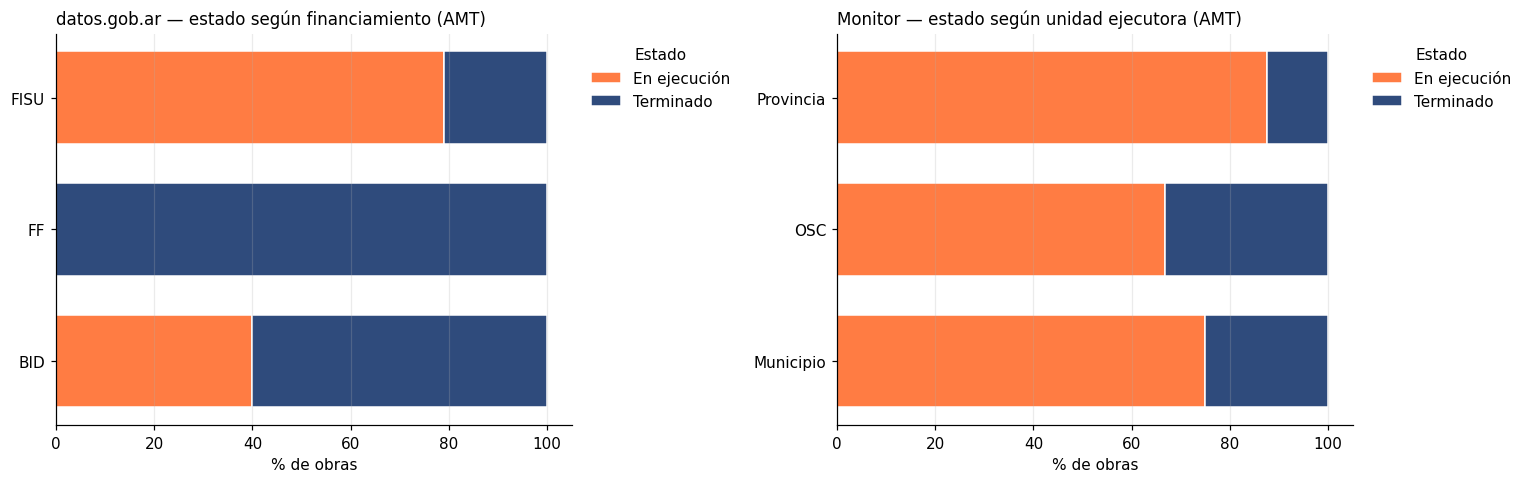

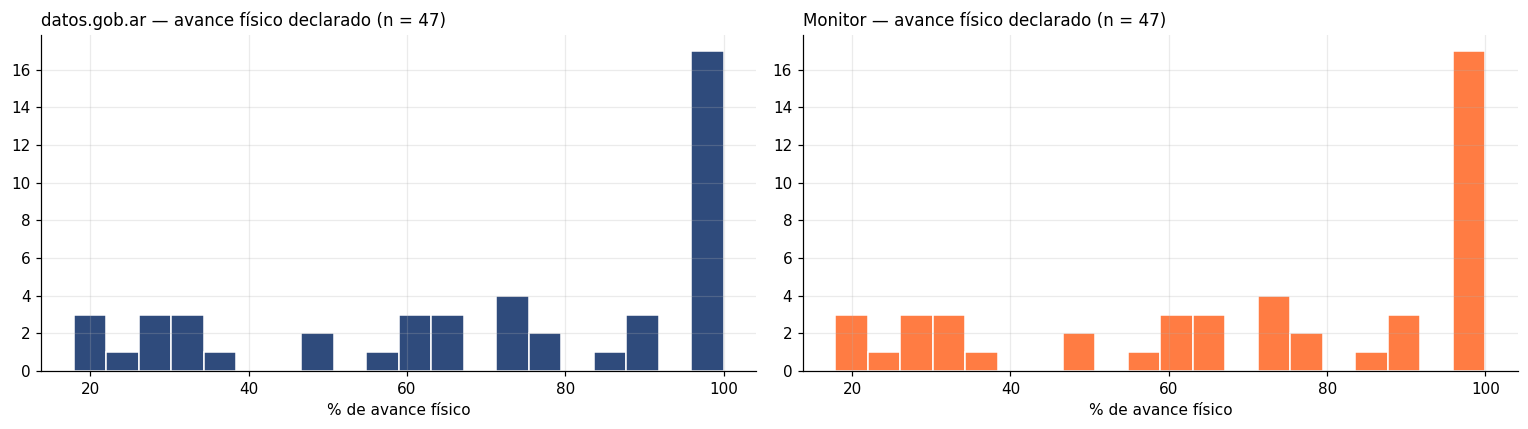

Avance físico por financiamiento (datos.gob.ar):


,count,mean,std,min,25%,50%,75%,max
financiamiento,,,,,,,,
BID,"3,0","75,7","40,1","29,4","63,6","97,8","98,9","100,0"
FF,"1,0","100,0",NaN,"100,0","100,0","100,0","100,0","100,0"
FISU,"43,0","69,6","28,7","17,9","48,4","73,7","100,0","100,0"


Avance físico por unidad ejecutora (Monitor):


,count,mean,std,min,25%,50%,75%,max
tipo_ue,,,,,,,,
Municipio,"11,0","76,9","28,1","27,2","59,0","90,6","100,0","100,0"
OSC,"21,0","78,0","21,9","31,3","65,1","75,4","100,0","100,0"
Provincia,"15,0","55,7","34,2","17,9","25,9","46,7","97,3","100,0"


Sin avance informado: datos.gob.ar 3 · Monitor 2


In [ ]:
# 4.3 (cont.) — Estado y avance físico en el AMT
estado_y_avance(obras_amt, mon_obras_amt, "amt", "AMT")

In [ ]:
# 4.3 (cont.) — Unidad ejecutora en el AMT
unidad_ejecutora(obras_amt, mon_obras_amt, "amt")

datos.gob.ar:


financiamiento,BID,FF,FISU,Total,Monto total,Monto promedio
tipo_ue,,,,,,
OSC,2,0,21,23,"5.577.849.285,26","242.515.186,32"
Provincia,3,0,12,15,"4.326.992.508,88","288.466.167,26"
Municipio,0,2,10,12,"10.273.092.693,33","856.091.057,78"


Monitor:


,obras,inversion_total,inversion_promedio,familias,%_obras,%_inversion,inversion_por_familia
tipo_ue,,,,,,,
OSC,21,"5.522.038.785,26","262.954.227,87",3.515,"42,9","27,3",1.570.993
Provincia,16,"4.401.480.857,88","275.092.553,62",5.701,"32,7","21,8",772.054
Municipio,12,"10.273.092.693,33","856.091.057,78",2.809,"24,5","50,9",3.657.206


Composición por unidad ejecutora en las dos fuentes:


,datos.gob.ar (% proyectos),Monitor (% obras)
unidad ejecutora,,
OSC,"46,0","42,9"
Provincia,"30,0","32,7"
Municipio,"24,0","24,5"


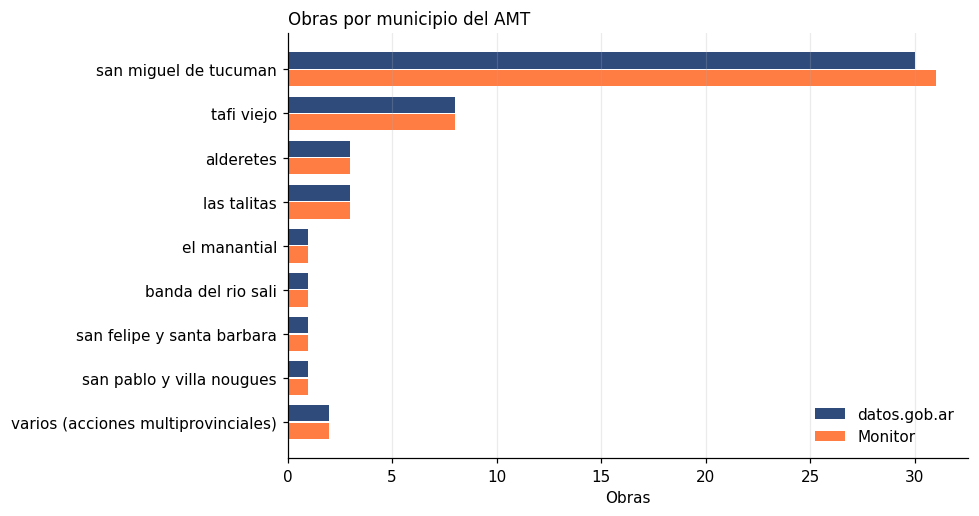

datos.gob.ar         Monitor        
                                           obras barrios   obras barrios
municipio_amt                                                           
san miguel de tucuman                         30      18      31      18
tafi viejo                                     8       5       8       5
alderetes                                      3       2       3       2
las talitas                                    3       3       3       3
el manantial                                   1       1       1       1
banda del rio sali                             1       1       1       1
san felipe y santa barbara                     1       1       1       1
san pablo y villa nougues                      1       1       1       1
varios (acciones multiprovinciales)            2       2       2       2


datos.gob.ar — 'varios (acciones multiprovinciales)': 2 registros (2 son acciones COVID fuera de matriz, ver 3.2)
  alcanzan 3 barrios del AMT en 2 departamentos (Tafí Viejo, Yerba Buena) y 3 localidades (Barrio San José III, Tafí Viejo, Yerba Buena - Marcos Paz)
    4064 San José — Barrio San José III (depto. Yerba Buena)
    4144 La Plaza Vieja — Yerba Buena - Marcos Paz (depto. Yerba Buena)
    4148 Triángulo II — Tafí Viejo (depto. Tafí Viejo)

Monitor — 'varios (acciones multiprovinciales)': 2 registros (2 son acciones COVID fuera de matriz, ver 3.2)
  alcanzan 3 barrios del AMT en 2 departamentos (Tafí Viejo, Yerba Buena) y 3 localidades (Barrio San José III, Tafí Viejo, Yerba Buena - Marcos Paz)
    4064 San José — Barrio San José III (depto. Yerba Buena)
    4144 La Plaza Vieja — Yerba Buena - Marcos Paz (depto. Yerba Buena)
    4148 Triángulo II — Tafí Viejo (depto. Tafí Viejo)

El RENABAP informa departamento y localidad, no municipio: por eso el detalle se da en esos términ

In [ ]:
# 4.3 (cont.) — Distribución por municipio. Cuento cada obra una vez por municipio.
def por_municipio(d_barrio, col_id):
    return (d_barrio.drop_duplicates(subset=[col_id, "municipio_amt"])
                    .groupby("municipio_amt")
                    .agg(obras=(col_id, "nunique"), barrios=("id_renabap", "nunique")))


ETIQUETA_VARIOS = "varios (acciones multiprovinciales)"
muni_amt = pd.concat({"datos.gob.ar": por_municipio(obras_amt_barrio, "proyecto_id"),
                      "Monitor": por_municipio(monitor_amt_barrio, "obra_id")}, axis=1).fillna(0).astype(int)
muni_amt = muni_amt.rename(index={"varios": ETIQUETA_VARIOS})
muni_amt = pd.concat([muni_amt.drop(index=ETIQUETA_VARIOS, errors="ignore")
                              .sort_values(("datos.gob.ar", "obras"), ascending=False),
                      muni_amt.loc[muni_amt.index == ETIQUETA_VARIOS]])
guardar_tabla(muni_amt, "4_amt_por_municipio")

fig, ax = plt.subplots(figsize=(9, 4.8))
barras_agrupadas(ax, muni_amt.xs("obras", axis=1, level=1).iloc[::-1], COLOR_FUENTE,
                 "Obras por municipio del AMT", "Obras")
plt.tight_layout(); guardar_fig("4_amt_municipios"); plt.show()
display(muni_amt)

# Qué hay detrás de "varios": la fuente no declara municipio (dice "Varios" en provincia,
# municipio, localidad y barrio); la ubicación sólo está en el ID RENABAP
for fuente, d_barrio, col_id in [("datos.gob.ar", obras_amt_barrio, "proyecto_id"),
                                 ("Monitor", monitor_amt_barrio, "obra_id")]:
    v = d_barrio[d_barrio["municipio_amt"] == "varios"]
    if v.empty:
        continue
    ubic = amt["2023"].set_index("id_renabap").reindex(sorted(set(v["id_renabap"])))
    covid_v = v.drop_duplicates(col_id)["fuera_de_matriz"].notna().sum()
    print(f"\n{fuente} — '{ETIQUETA_VARIOS}': {fmt_ar(v[col_id].nunique())} registros "
          f"({fmt_ar(covid_v)} son acciones COVID fuera de matriz, ver 3.2)")
    print(f"  alcanzan {fmt_ar(len(ubic))} barrios del AMT en "
          f"{fmt_ar(ubic['departamento'].nunique())} departamentos ({', '.join(sorted(ubic['departamento'].dropna().unique()))}) "
          f"y {fmt_ar(ubic['localidad'].nunique())} localidades ({', '.join(sorted(ubic['localidad'].dropna().unique()))})")
    for i, r in ubic.iterrows():
        print(f"    {i} {r['nombre_barrio']} — {r['localidad']} (depto. {r['departamento']})")
print("\nEl RENABAP informa departamento y localidad, no municipio: por eso el detalle se da en esos términos.")

### 4.4 Tipo, subdimensión, dimensión y escala — AMT frente al país

Cada tabla agrega, por fuente, el % nacional y la **brecha** (AMT − país) en puntos porcentuales.

In [ ]:
# 4.4 — Clasificación F3 en el AMT, comparada con el país
FUENTES_AMT = {"datos.gob.ar": obras_amt, "Monitor": monitor_amt}
F3_AMT = tablas_f3(FUENTES_AMT, "amt", referencia=F3_NAC)
mostrar_f3(F3_AMT)
print("\nCalidad de la clasificación en el AMT:")
calidad_amt = calidad_clasificacion(FUENTES_AMT)
guardar_tabla(calidad_amt, "4_calidad_clasificacion_amt")
calidad_amt


TIPO de intervención (multietiqueta, no suma 100 %)


datos.gob.ar                                       Monitor                                      
                                     obras     %             monto % país brecha   obras     %             monto % país brecha
tipo de intervención                                                                                                          
Infraestructura de servicios            24 50,00 13.962.815.167,90  67,20 -17,20      34 69,40 16.917.603.986,34  64,30   5,10
Movilidad y accesibilidad               21 43,80 11.381.629.101,43  43,20   0,60      22 44,90 11.978.232.026,45  50,00  -5,10
Conexiones intradomiciliarias           19 39,60  5.176.623.204,05  38,70   0,90       0  0,00              0,00   0,20  -0,20
Espacio público                         12 25,00  1.849.598.740,81  25,10  -0,10       1  2,00    129.592.926,58  11,00  -9,00
Vivienda                                10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Equipamiento comunitario                 6 12,50  1.020.759.676,17  27,80 -15,30       9 18,40  2.257.653.557,90  27,00  -8,60
Ambiente                                 1  2,10  1.097.517.556,25   2,50  -0,40       1  2,00  1.097.517.556,25   1,50   0,50
Suelo y regularización                   1  2,10    399.157.940,64  11,70  -9,60       0  0,00              0,00  11,80 -11,80
Planificación / proyecto                 1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50
Sin especificar (genéricos)              0  0,00              0,00   0,00   0,00       1  2,00     74.488.349,00   0,80   1,20


SUBDIMENSIÓN (multietiqueta)


datos.gob.ar                                       Monitor                                      
                                                          obras     %             monto % país brecha   obras     %             monto % país brecha
subdimensión                                                                                                                                       
Servicios básicos y energía (Infraestructuras)               24 50,00 13.962.815.167,90  66,10 -16,10      34 69,40 16.917.603.986,34  64,20   5,20
Movilidad y conectividad (Infraestructuras)                  21 43,80 11.381.629.101,43  51,50  -7,70      22 44,90 11.978.232.026,45  50,10  -5,20
Espacio público, deporte y cultura (Equipamiento)            12 25,00  1.849.598.740,81  27,40  -2,40       8 16,30  2.104.082.441,41  21,00  -4,70
Mejoramiento y provisión de vivienda (Vivienda)              10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Administración y bienestar (Equipamiento)                     4  8,30    737.595.633,10  23,30 -15,00       3  6,10    808.541.778,38  12,60  -6,50
Servicios y consumo (Equipamiento)                            1  2,10  1.097.517.556,25   1,30   0,80       0  0,00              0,00   0,90  -0,90
Salud y educación (Equipamiento)                              1  2,10    153.571.116,49   1,40   0,70       1  2,00    153.571.116,49   2,50  -0,50
Condiciones ambientales (Calidad ambiental)                   1  2,10  1.097.517.556,25   2,20  -0,10       1  2,00  1.097.517.556,25   1,50   0,50
Regularización y seguridad en la tenencia (Situ...            1  2,10    399.157.940,64   0,80   1,30       0  0,00              0,00   1,30  -1,30
Producción de suelo urbanizado (Situación domin...            1  2,10    399.157.940,64  11,40  -9,30       0  0,00              0,00  11,80 -11,80
Planificación y proyecto (Planificación)                      1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50


DIMENSIÓN (multietiqueta)


datos.gob.ar                                       Monitor                                      
                                   obras     %             monto % país brecha   obras     %             monto % país brecha
dimensión                                                                                                                   
Infraestructuras                      32 66,70 14.565.031.878,38  80,50 -13,80      41 83,70 17.409.486.100,97  78,40   5,30
Equipamiento                          15 31,20  3.570.098.311,01  38,30  -7,10      10 20,40  2.467.191.512,24  28,80  -8,40
Vivienda                              10 20,80  3.618.985.805,97   8,00  12,80      10 20,40  3.618.985.805,97   9,80  10,60
Calidad ambiental                      1  2,10  1.097.517.556,25   2,20  -0,10       1  2,00  1.097.517.556,25   1,50   0,50
Situación dominial                     1  2,10    399.157.940,64  11,70  -9,60       0  0,00              0,00  11,80 -11,80
Planificación (paso previo)            1  2,10      2.794.000,00   1,60   0,50       1  2,00      2.794.000,00   1,50   0,50

... (2 outputs left out)


ESCALA (suma 100 %) y cuántas quedan a verificar


datos.gob.ar                   Monitor                  
                      obras     % a verificar   obras     % a verificar
escala                                                                 
barrial                  44 91,70        5,00   45,00 91,80        2,00
comunitaria               2  4,20        0,00    2,00  4,10        0,00
ambas                     1  2,10        1,00    0,00  0,00        0,00
sin determinar            1  2,10        1,00    2,00  4,10        2,00


Calidad de la clasificación en el AMT:


,datos.gob.ar,Monitor
acciones fuera de matriz (excluidas),2,2
obras clasificables,48,49
genéricas (sin especificar),0,1
sin tipo asignado,0,0
sin dimensión asignada,0,0
escala inferida por defecto,7,4
multietiqueta (≥ 2 tipos),29,26
promedio de tipos por obra,"1,98","1,59"


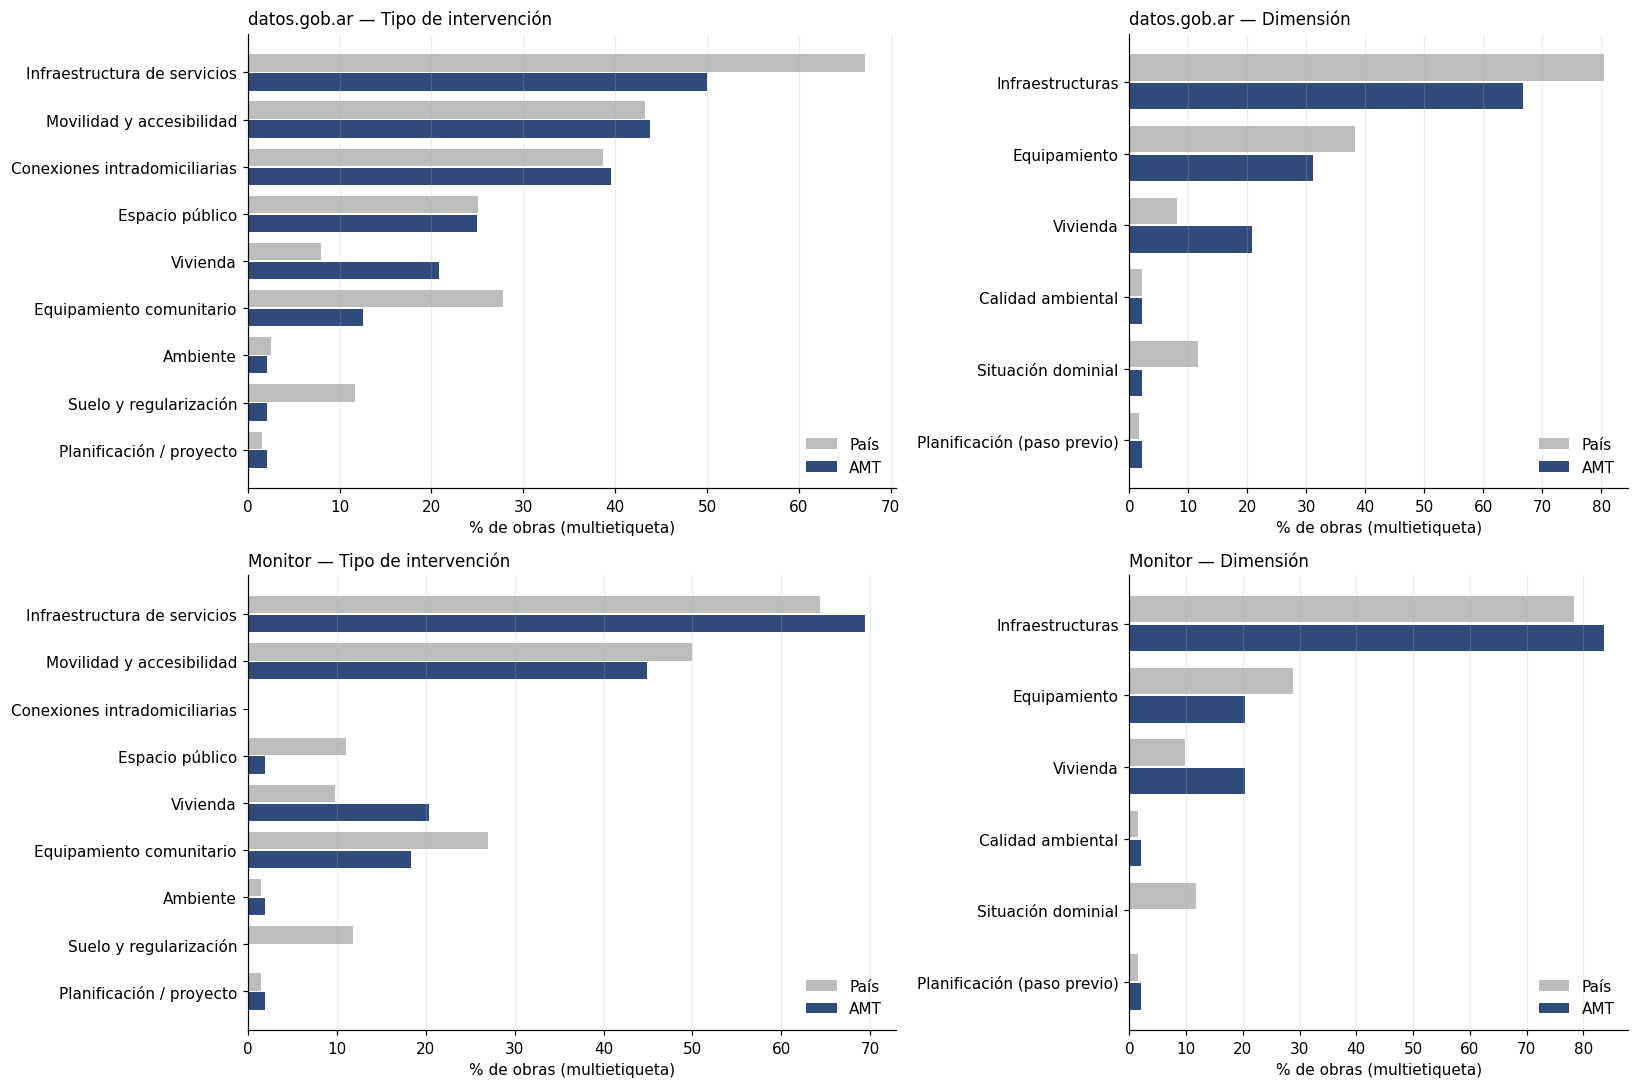

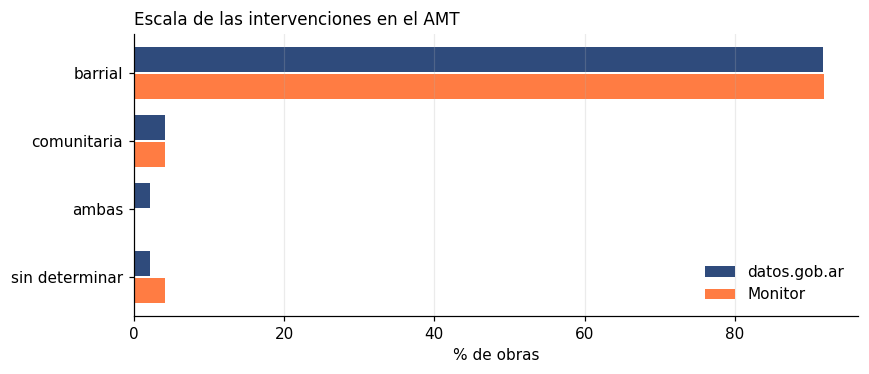

In [ ]:
# 4.4 (gráfico) — AMT vs. país por fuente: tipo y dimensión
fig, axes = plt.subplots(2, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1.3, 1]})
for fila, f in enumerate(FUENTES_AMT):
    for col, (k, etq, quitar) in enumerate([("tipo", "Tipo de intervención", ["Sin especificar (genéricos)"]),
                                             ("dimension", "Dimensión", [])]):
        t = F3_AMT[k][f][["% país", "%"]].rename(columns={"% país": "País", "%": "AMT"})
        barras_agrupadas(axes[fila, col], t.drop(index=quitar, errors="ignore").iloc[::-1],
                         COLOR_REFERENCIA, f"{f} — {etq}", "% de obras (multietiqueta)")
plt.tight_layout(); guardar_fig("4_f3_amt_vs_pais"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
barras_agrupadas(ax, F3_AMT["escala"].xs("%", axis=1, level=1).iloc[::-1], COLOR_FUENTE,
                 "Escala de las intervenciones en el AMT", "% de obras")
plt.tight_layout(); guardar_fig("4_escala_amt"); plt.show()

In [ ]:
# 4.4 (cont.) — Auditoría de escala en el AMT: obras sin escala definida
sin_escala_amt = auditar_escala(FUENTES_AMT, "amt")

Obras sin escala definida, según motivo:


fuente,Monitor,datos.gob.ar,Total
motivo,,,
acción fuera de matriz (COVID-19),2,2,4
"nombre genérico, sin componentes declarados",1,0,1
planificación: no produce impacto territorial,1,1,2
Total,4,3,7
obras de la fuente,51,50,101


Detalle (7 registros):


,fuente,id,provincia,municipio,barrios,linea_programatica,nombre,dimension_principal,motivo
4,Monitor,M01276,Varios,Varios,676/1449/1642/1669/1812/1813/2212/2460/2584/2701/3320/3527/3542/4064,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
5,Monitor,M01284,Varios,Varios,274/409/1654/1781/1804/1848/1853/2134/2135/2735/3638/3707/3709/4027/4144/4148/4354,NaN,Fortalecimiento comunitario en barrios populares el marco del COVID 19,Sin clasificar,acción fuera de matriz (COVID-19)
6,Monitor,M01299,Tucumán,San Miguel De Tucumán,2760/2762,NaN,Obras de integración urbana en Autopista Sur/ Los Vázquez,Sin especificar,"nombre genérico, sin componentes declarados"
3,Monitor,M01259,Tucumán,Tafí Viejo,4119/4120/4121,NaN,Asistencia técnica para formulación de proyecto en Niño Jesús/Cortada de Matorel/Ampliación Meloni,Planificación,planificación: no produce impacto territorial
0,datos.gob.ar,P01239,Varios,Varios,274/409/1654/1781/1804/1848/1853/2134/2135/2735/3638/3707/3709/4027/4144/4148/4354,INTEGRAR SALUD,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,Sin clasificar,acción fuera de matriz (COVID-19)
1,datos.gob.ar,P01245,Varios,Varios,676/1449/1642/1669/1812/1813/2212/2460/2584/2701/3320/3527/3542/4064,INTEGRAR SALUD,Acciones de emergencia y/o de recuperación de barrios en el marco del COVID-19,Sin clasificar,acción fuera de matriz (COVID-19)
2,datos.gob.ar,P01302,Tucumán,Tafí Viejo,4119/4120/4121,PrePEG,Diseño de un Proyecto Ejecutivo Integral,Planificación,planificación: no produce impacto territorial


La distribución por escala es el indicador más directo de la hipótesis: si lo *barrial* domina y lo *comunitario* se concentra en pocas obras, la afirmación de que la política circunscribe su alcance al mejoramiento intra-barrial queda respaldada por la propia declaración de las obras. Conviene reportarla junto con la columna *a verificar*: son valores de referencia, inferidos del nombre de la obra. El alcance efectivo de cada intervención se analiza en detalle en los casos de estudio del AMT.

### 4.5 Barrios alcanzados por las obras

In [ ]:
# 4.5 — Detalle por barrio de las obras en el AMT
det_obras = (obras_amt_barrio.groupby("id_renabap")
             .agg(proyectos=("proyecto_id", "nunique"),
                  municipio=("municipio", "first"),
                  lineas=("linea_programatica", lambda s: ", ".join(sorted(set(s.dropna())))),
                  financiamientos=("financiamiento", lambda s: ", ".join(sorted(set(s.dropna()))))))
det_obras = det_obras.join(monitor_amt_barrio.groupby("id_renabap").agg(obras_monitor=("obra_id", "nunique")),
                           how="outer")
det_obras.insert(0, "barrio", det_obras.index.map(NOMBRES_AMT))
det_obras = det_obras.sort_values("proyectos", ascending=False)
guardar_tabla(det_obras, "4_amt_obras_por_barrio")
det_obras.head(45)

,barrio,proyectos,municipio,lineas,financiamientos,obras_monitor
id_renabap,,,,,,
2745,ATE,5,San Miguel De Tucumán,POT,FISU,5
4507,Ampliación Muñecas III,4,San Miguel De Tucumán,POT,FISU,4
2762,Los Vázquez,4,San Miguel De Tucumán,POT,"BID, FISU",5
2760,Autopista Sur,3,San Miguel de Tucumán,POT,BID,4
4120,Cortada de Matorel,2,Tafí Viejo,"POT, PrePEG","FF, FISU",2
2763,Margaritas,2,San Miguel De Tucumán,POT,FISU,2
2779,Ciudadela Norte,2,San Miguel De Tucumán,POT,FISU,2
4050,La Nina,2,Tafí Viejo,POT,"FF, FISU",2
4073,Julio Abraham,2,Alderetes,POT,FISU,2


In [ ]:
# 4.5 (cont.) — ¿Los barrios con obra tienen un perfil distinto?
# Uso los atributos de 2023: los barrios que no figuran en ese relevamiento quedan afuera
base23 = amt["2023"].copy()
base23["intervenido"] = np.where(base23["id_renabap"].isin(b_gob), "Con obra", "Sin obra")
base23["familias"] = pd.to_numeric(base23["cantidad_familias_aproximada"], errors="coerce")
base23["superficie_m2"] = pd.to_numeric(base23["superficie_m2"], errors="coerce")

excluidos = sorted(b_gob & FUERA_2023)
print(f"Barrios con obra: {fmt_ar(len(b_gob))} · en el contraste: {fmt_ar((base23['intervenido'] == 'Con obra').sum())}"
      + (f" (sin atributos 2023: {', '.join(f'{i} {NOMBRES_AMT[i]}' for i in excluidos)})" if excluidos else ""))

perfil = base23.groupby("intervenido").agg(
    barrios=("id_renabap", "count"), familias_mediana=("familias", "median"),
    familias_total=("familias", "sum"), superficie_mediana_m2=("superficie_m2", "median"))
guardar_tabla(perfil, "4_amt_perfil_intervenidos")
display(perfil)
print("Tipología barrial (% por columna):")
display(pd.crosstab(base23["clasificacion_barrio"], base23["intervenido"], normalize="columns").mul(100).round(1))
print("Acceso al agua (% por columna):")
pd.crosstab(base23["agua_corriente"], base23["intervenido"], normalize="columns").mul(100).round(1)

Barrios con obra: 41 · en el contraste: 40 (sin atributos 2023: 2756 Barrio Santa Ana)


,barrios,familias_mediana,familias_total,superficie_mediana_m2
intervenido,,,,
Con obra,40,229,16.193,86.537
Sin obra,173,66,21.941,26.761


Tipología barrial (% por columna):


intervenido,Con obra,Sin obra
clasificacion_barrio,,
Asentamiento,"70,0","71,7"
Conjunto habitacional unifamiliar,"0,0","2,9"
Villa,"30,0","25,4"


Acceso al agua (% por columna):


intervenido,Con obra,Sin obra
agua_corriente,,
Bomba de agua de pozo comunitaria,"10,0","12,1"
Bomba de agua de pozo domiciliaria,"2,5","1,2"
Camión cisterna,"0,0","1,2"
Canilla comunitaria dentro del barrio,"0,0","0,6"
Conexión irregular a la red de agua,"85,0","82,7"
Conexión regular a la red de agua pero sin factura,"2,5","2,3"


---
## 5. Análisis financiero — deflación por ICC

Los montos se conservan **a precios corrientes** como referencia principal y se agrega en paralelo una columna **a precios constantes**, deflactada por el ICC nivel general del INDEC.

- El archivo trae **variaciones porcentuales mensuales**, no niveles: el índice se reconstruye encadenando las variaciones. La base de arranque (100 en el primer mes) es arbitraria porque la deflación trabaja con cocientes entre dos meses.
- El ICC mide costos de construcción en el Gran Buenos Aires. Es el deflactor estándar para obra pública, pero **no capta diferenciales regionales**: aplicado a Tucumán es una aproximación.
- Se deflacta según el **acta de inicio real**. Los proyectos sin acta quedan sin monto constante.
- **Sólo datos.gob.ar es deflactable.** El Monitor y Mi Pieza no informan fecha, por lo que sus montos quedan en corrientes.

### 5.1 Reconstrucción del índice

In [ ]:
# 5.1 — Índice ICC nivel general a partir de las variaciones mensuales
icc = (icc_crudo[icc_crudo["nivel_general_aperturas"] == "nivel_general"]
       .set_index("periodo_m")["variacion_indice_icc"].sort_index())

# Un mes faltante arrastraría el error a toda la serie posterior
esperados = pd.period_range(icc.index.min(), icc.index.max(), freq="M").astype(str)
print(f"Meses faltantes en la serie: {fmt_ar(len(set(esperados) - set(icc.index)))}")

ICC = 100 * (1 + icc / 100).cumprod()
if MES_BASE_ICC not in ICC.index:
    MES_BASE_ICC = ICC.index.max()
    print(f"Mes base fuera de la serie: se usa el último disponible ({MES_BASE_ICC})")
print(f"Índice reconstruido: {fmt_ar(len(ICC))} meses · mes base {MES_BASE_ICC} = {fmt_ar(ICC[MES_BASE_ICC], 2)}")
ICC.tail(6).to_frame("icc")

Meses faltantes en la serie: 0
Índice reconstruido: 129 meses · mes base 2023-12 = 5.152,76


,icc
periodo_m,
2026-02,"12.734,59"
2026-03,"12.982,07"
2026-04,"13.491,66"
2026-05,"13.862,33"
2026-06,"14.225,81"
2026-07,"14.525,91"


### 5.2 Deflación de los montos

In [ ]:
# 5.2 — Montos a precios constantes del mes base
def deflactar(df):
    d = df.copy()
    d["periodo_inicio"] = d["acta_inicio"].dt.to_period("M").astype(str).where(d["acta_inicio"].notna())
    d["icc_inicio"] = d["periodo_inicio"].map(ICC)
    d["monto_constante"] = d["monto_total"] * ICC[MES_BASE_ICC] / d["icc_inicio"]
    return d


obras = deflactar(obras)
obras_amt = deflactar(obras_amt)

for nombre, d in [("País", obras), ("AMT", obras_amt)]:
    ok = d["monto_constante"].notna()
    print(f"{nombre}: {fmt_ar(ok.sum())} de {fmt_ar(len(d))} proyectos deflactados "
          f"({fmt_ar(ok.mean() * 100, 1)} %) · sin acta: {fmt_ar(d['acta_inicio'].isna().sum())}")
    # El total constante se compara contra el corriente del MISMO subconjunto, no contra el total
    print(f"   corriente de esos proyectos: $ {fmt_ar(d.loc[ok, 'monto_total'].sum())} · "
          f"constante ({MES_BASE_ICC}): $ {fmt_ar(d['monto_constante'].sum())}")

País: 1.227 de 1.315 proyectos deflactados (93,3 %) · sin acta: 88
   corriente de esos proyectos: $ 529.524.864.441 · constante (2023-12): $ 1.272.254.117.178
AMT: 47 de 50 proyectos deflactados (94,0 %) · sin acta: 3
   corriente de esos proyectos: $ 20.119.329.987 · constante (2023-12): $ 50.705.576.005


### 5.3 Escala nacional

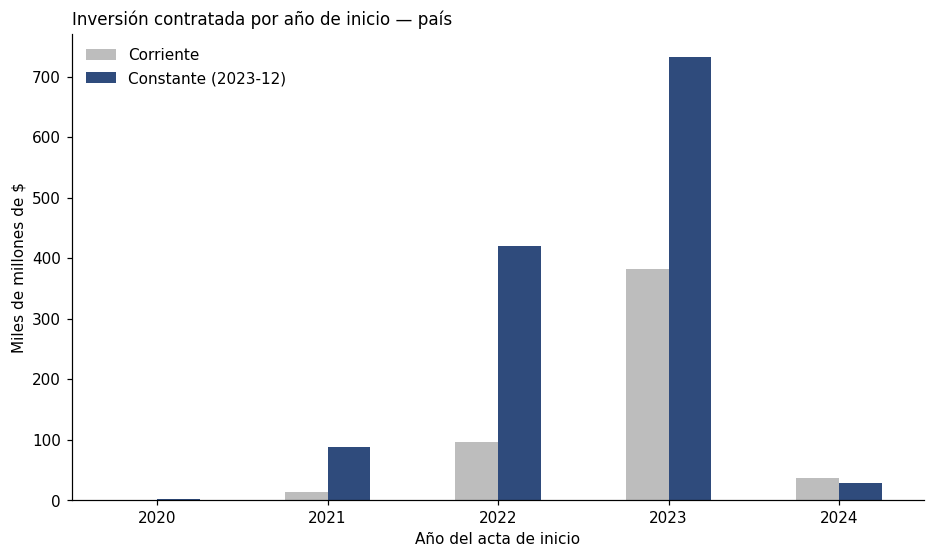

,Corriente,Constante (2023-12)
anio_inicio,,
2020,"230.076.471,29","2.426.469.271,09"
2021,"12.958.032.625,70","87.848.815.061,22"
2022,"96.237.028.553,36","420.811.709.998,04"
2023,"382.760.688.350,89","733.203.466.914,54"
2024,"37.339.038.439,48","27.963.655.933,20"


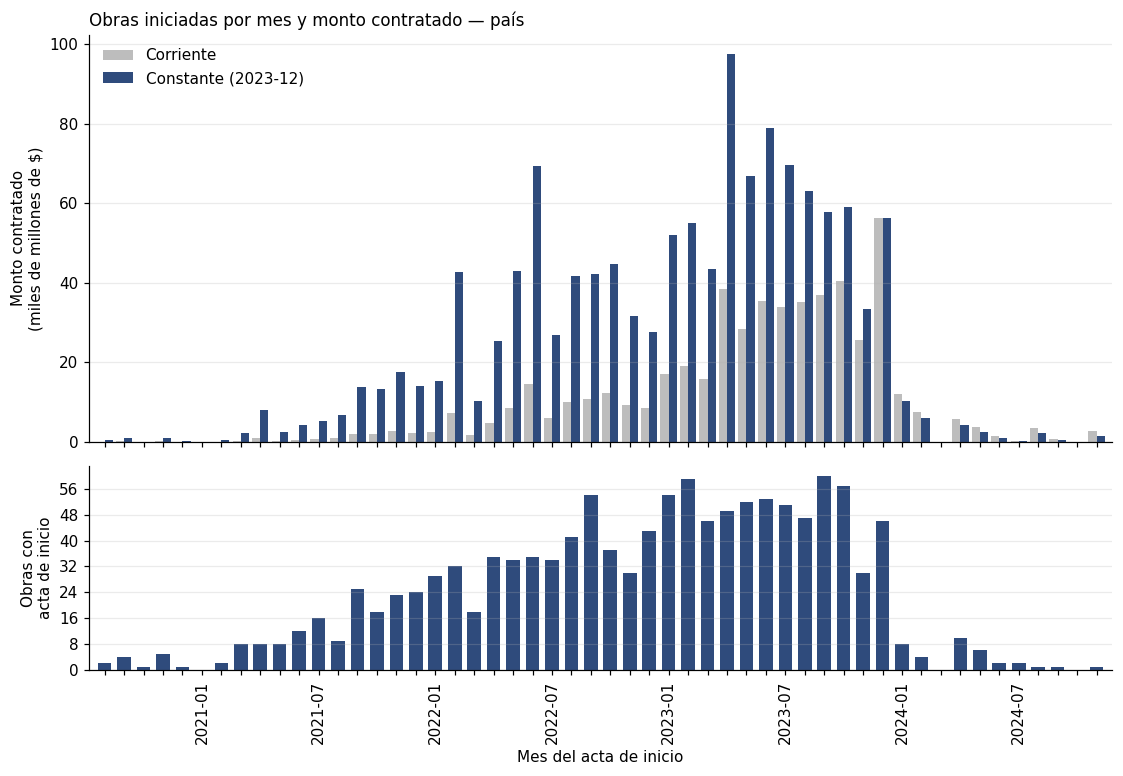

In [ ]:
# 5.3 — Inversión contratada por año y por mes (país)
display(por_anio(obras, "Inversión contratada por año de inicio — país", "5_por_anio_pais"))
serie_pais = serie_mensual(obras, "Obras iniciadas por mes y monto contratado — país", "5_serie_mensual_pais")

In [ ]:
# 5.3 (cont.) — Montos constantes por línea programática y por dimensión (país)
fin_lp = obras.groupby("linea_programatica")[["monto_total", "monto_constante"]].sum()
fin_dim = pd.DataFrame({d: obras.loc[obras[f"dim_{d}"], ["monto_total", "monto_constante"]].sum()
                        for d in DIMENSIONES}).T
for t in (fin_lp, fin_dim):
    t.columns = ["corriente", f"constante ({MES_BASE_ICC})"]
    t["%_constante"] = (t.iloc[:, 1] / t.iloc[:, 1].sum() * 100).round(1)
guardar_tabla(fin_lp, "5_montos_linea_pais")
guardar_tabla(fin_dim, "5_montos_dimension_pais")
print("Por línea programática:"); display(fin_lp.sort_values("corriente", ascending=False))
print("Por dimensión (multietiqueta: los montos no se suman entre filas):")
fin_dim

Por línea programática:


,corriente,constante (2023-12),%_constante
linea_programatica,,,
POT,"284.568.701.216,04","762.753.649.026,78","60,0"
LOTES,"172.148.222.353,90","232.453.017.880,65","18,3"
PEG,"102.849.806.716,62","269.646.253.271,17","21,2"
LOTES (Adq.),"6.457.798.847,75",0,"0,0"
VIVIENDA,"2.528.015.564,86","7.285.317.560,55","0,6"
MV,"788.493.479,96","115.879.438,93","0,0"
INTEGRAR SALUD,609.870.000,0,"0,0"
PrePEG,"228.940.988,32",0,"0,0"


Por dimensión (multietiqueta: los montos no se suman entre filas):


,corriente,constante (2023-12),%_constante
Infraestructuras,"456.565.837.110,83","1.080.017.491.927,42","50,4"
Equipamiento,185.531.005.656,"463.337.437.867,90","21,6"
Calidad ambiental,"31.215.660.942,53","60.863.849.906,01","2,8"
Situación dominial,"221.886.392.132,92","343.778.658.951,83","16,0"
Vivienda,"81.742.400.049,79","196.374.771.868,49","9,2"


### 5.4 Área Metropolitana de Tucumán

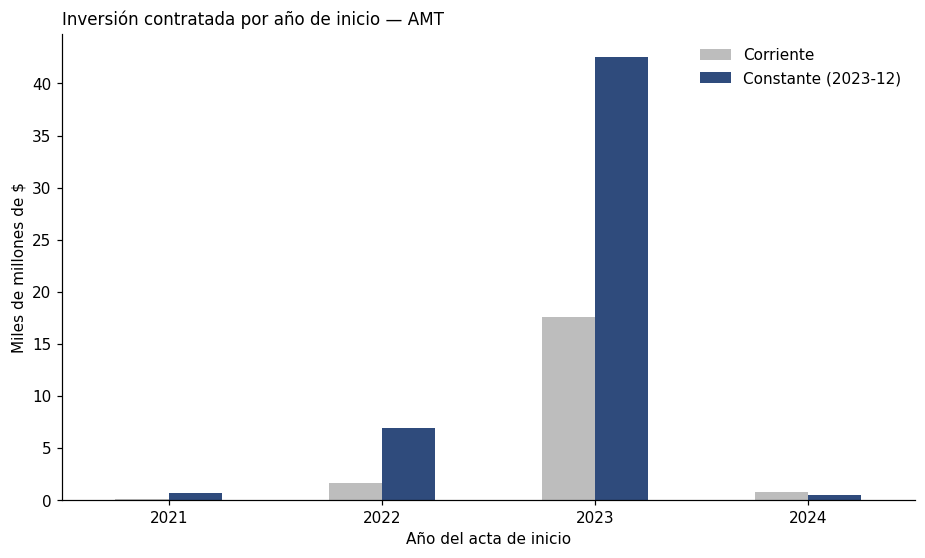

,Corriente,Constante (2023-12)
anio_inicio,,
2021,"96.297.257,35","681.320.565,85"
2022,"1.663.578.489,47","6.907.146.115,83"
2023,"17.615.362.403,35","42.583.558.437,98"
2024,"744.091.837,30","533.550.885,03"


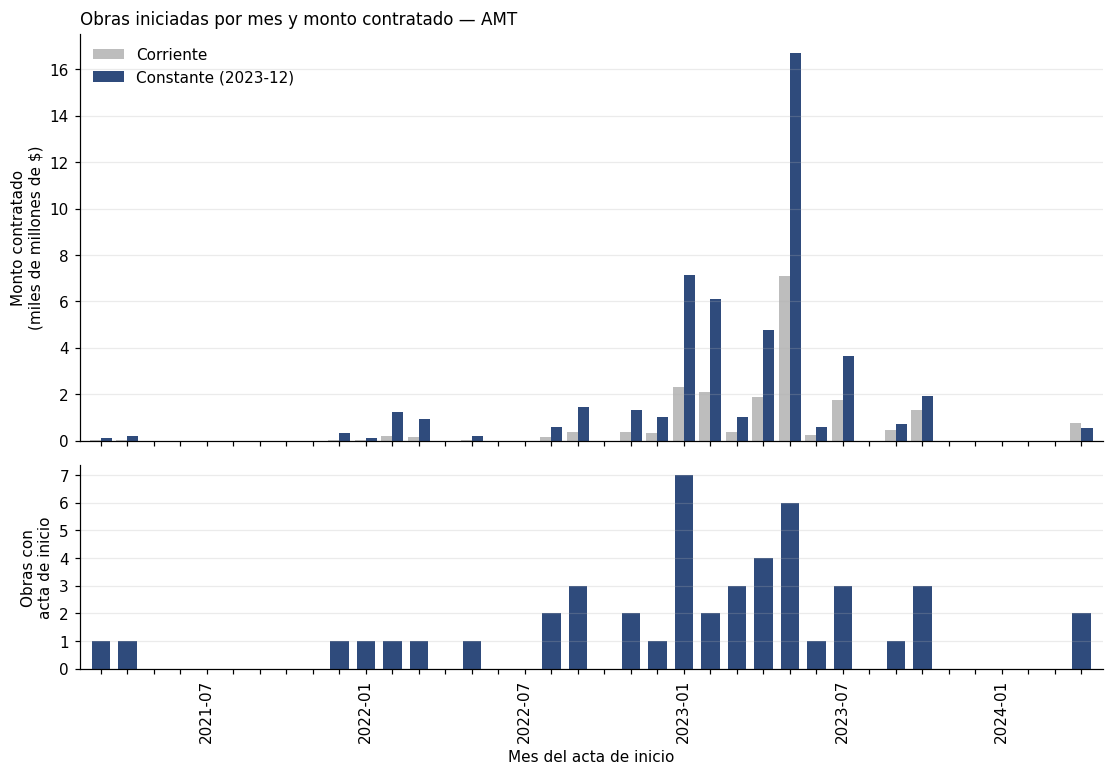

In [ ]:
# 5.4 — Inversión contratada por año y por mes (AMT)
display(por_anio(obras_amt, "Inversión contratada por año de inicio — AMT", "5_por_anio_amt"))
serie_amt = serie_mensual(obras_amt, "Obras iniciadas por mes y monto contratado — AMT", "5_serie_mensual_amt")

In [ ]:
# 5.4 (cont.) — Montos constantes por dimensión y participación del AMT en el país
fin_dim_amt = pd.DataFrame({d: obras_amt.loc[obras_amt[f"dim_{d}"], ["monto_total", "monto_constante"]].sum()
                            for d in DIMENSIONES}).T
fin_dim_amt.columns = ["corriente", f"constante ({MES_BASE_ICC})"]
fin_dim_amt["% del país (constante)"] = (fin_dim_amt.iloc[:, 1] / fin_dim.iloc[:, 1] * 100).round(1)
guardar_tabla(fin_dim_amt, "5_montos_dimension_amt")
print(f"Participación del AMT en el monto constante nacional: "
      f"{fmt_ar(obras_amt['monto_constante'].sum() / obras['monto_constante'].sum() * 100, 1)} %")
fin_dim_amt

Participación del AMT en el monto constante nacional: 4,0 %


,corriente,constante (2023-12),% del país (constante)
Infraestructuras,"14.565.031.878,38","36.477.781.022,54","3,4"
Equipamiento,"3.570.098.311,01","8.897.480.324,86","1,9"
Calidad ambiental,"1.097.517.556,25","2.255.099.248,41","3,7"
Situación dominial,"399.157.940,64","820.160.704,32","0,2"
Vivienda,"3.618.985.805,97","9.572.684.540,65","4,9"


### 5.5 Inversión relativa — por vivienda, por familia, por persona y por hectárea

El monto total no dice cuánto recibe cada barrio en relación con su tamaño. Aquí el monto constante de cada proyecto se reparte entre sus barrios **en proporción a las viviendas** de cada uno (si un barrio no tiene dato, en partes iguales) y se divide por viviendas, familias, personas y hectáreas.

* Atributos de los barrios: RENABAP 2023; para los que salieron del registro en 2023 se usan los de 2022.
* Se excluyen las acciones de fortalecimiento COVID-19 (fuera de matriz) y los proyectos sin acta de inicio, que no se pueden deflactar.
* **Personas**: ninguna edición del RENABAP releva población. Se estima con el tamaño medio del grupo familiar declarado en las solicitudes de Mi Pieza del mismo recorte (país o AMT). Es una aproximación: las solicitantes son hogares con mujer a cargo, que pueden no representar a todos los hogares del barrio.
* Se calculan dos cocientes: sobre los **barrios con obra** (intensidad donde la política llegó) y sobre el **universo** de barrios (esfuerzo medio por barrio popular).

In [ ]:
# 5.5 — Inversión relativa: por vivienda, por familia, por persona y por hectárea
ATR = {}
for anio, col_id in [("2022", "renabap_id"), ("2023", "id_renabap")]:
    d = leer_csv(f"{RAW}/RENABAP_{anio}.csv", dtype={col_id: str},
                 usecols=[col_id, "cantidad_viviendas_aproximadas",
                          "cantidad_familias_aproximada", "superficie_m2"])
    d = d.rename(columns={col_id: "id_renabap", "cantidad_viviendas_aproximadas": "viviendas",
                          "cantidad_familias_aproximada": "familias"})
    d["id_renabap"] = d["id_renabap"].astype(str).str.strip()
    ATR[anio] = d.drop_duplicates("id_renabap").set_index("id_renabap")
atributos = ATR["2023"].combine_first(ATR["2022"])          # 2023 tiene prioridad
for c in ["viviendas", "familias", "superficie_m2"]:
    atributos[c] = pd.to_numeric(atributos[c], errors="coerce")
atributos["hectareas"] = atributos["superficie_m2"] / 10_000

# Personas por hogar: tamaño medio del grupo familiar en las solicitudes de Mi Pieza
mipieza["grupo_familiar"] = pd.to_numeric(mipieza["cantidad_grupo_familiar"], errors="coerce")
TAM_HOGAR = {"País": mipieza["grupo_familiar"].mean(),
             "AMT": mipieza.loc[mipieza["id_barrio"].isin(IDS_AMT), "grupo_familiar"].mean()}
print("Tamaño medio del grupo familiar (solicitudes Mi Pieza): "
      + " · ".join(f"{k} {fmt_ar(v, 2)}" for k, v in TAM_HOGAR.items()))


def repartir(obras_df, barrio_df):
    """Monto constante de cada proyecto repartido entre sus barrios según viviendas."""
    pb = (barrio_df.loc[barrio_df["fuera_de_matriz"].isna(), ["proyecto_id", "id_renabap"]]
          .drop_duplicates()
          .merge(obras_df[["proyecto_id", "monto_constante"]], on="proyecto_id")
          .dropna(subset=["monto_constante"])
          .join(atributos[["viviendas"]], on="id_renabap"))
    peso = pb["viviendas"].fillna(0)
    total = peso.groupby(pb["proyecto_id"]).transform("sum")
    n = pb.groupby("proyecto_id")["id_renabap"].transform("count")
    pb["monto_asignado"] = np.where(total > 0, pb["monto_constante"] * peso / total.where(total > 0),
                                    pb["monto_constante"] / n)
    return pb.groupby("id_renabap")["monto_asignado"].sum()


def relativos(monto_barrio, ids_universo, escala):
    filas = {}
    con = atributos.reindex(monto_barrio.index)
    uni = atributos.reindex(sorted(ids_universo))
    for nombre, at in [("barrios con obra", con), ("universo de barrios", uni)]:
        m = monto_barrio.sum()
        filas[(escala, nombre)] = {
            "barrios": len(at), "monto constante": m,
            "viviendas": at["viviendas"].sum(), "familias": at["familias"].sum(),
            "hectáreas": at["hectareas"].sum(),
            "$ por vivienda": m / at["viviendas"].sum(),
            "$ por familia": m / at["familias"].sum(),
            "$ por persona (est.)": m / (at["familias"].sum() * TAM_HOGAR[escala]),
            "$ por hectárea": m / at["hectareas"].sum()}
    return pd.DataFrame(filas).T


inv_barrio_pais = repartir(obras, obras_barrio)
inv_barrio_amt = inv_barrio_pais[inv_barrio_pais.index.isin(IDS_AMT)]
relativa = pd.concat([relativos(inv_barrio_pais, ATR["2023"].index, "País"),
                      relativos(inv_barrio_amt, IDS_AMT, "AMT")])
relativa = relativa.astype({"barrios": int, "viviendas": int, "familias": int})
# Los barrios con obra son menos que en 4.1 porque quedan afuera los proyectos sin acta de inicio
guardar_tabla(relativa, "5_inversion_relativa")
print(f"Montos constantes ({MES_BASE_ICC}). Barrios con obra sin atributos: "
      f"{fmt_ar(atributos.reindex(inv_barrio_pais.index)['viviendas'].isna().sum())} (país)")
relativa


Tamaño medio del grupo familiar (solicitudes Mi Pieza): País 4,31 · AMT 4,79
Montos constantes (2023-12). Barrios con obra sin atributos: 9 (país)


barrios      monto constante  viviendas  familias  hectáreas  $ por vivienda  $ por familia  $ por persona (est.)  $ por hectárea
País barrios con obra        1071 1.032.515.781.736,88     443920    488369  20.089,02    2.325.905,08   2.114.212,37            490.853,67   51.397.008,67
     universo de barrios     6467 1.032.515.781.736,88    1124797   1237795  68.420,19      917.957,45     834.157,34            193.665,12   15.090.806,52
AMT  barrios con obra          38    50.705.576.004,68      14633     16099     529,06    3.465.152,46   3.149.610,29            657.258,59   95.841.405,41
     universo de barrios      214    50.705.576.004,68      34851     38354   1.372,70    1.454.924,56   1.322.041,40            275.882,72   36.938.632,60

$ por vivienda en los barrios con obra del AMT (millones, constantes): mediana 2,16 · mínimo 0,27 · máximo 56,96


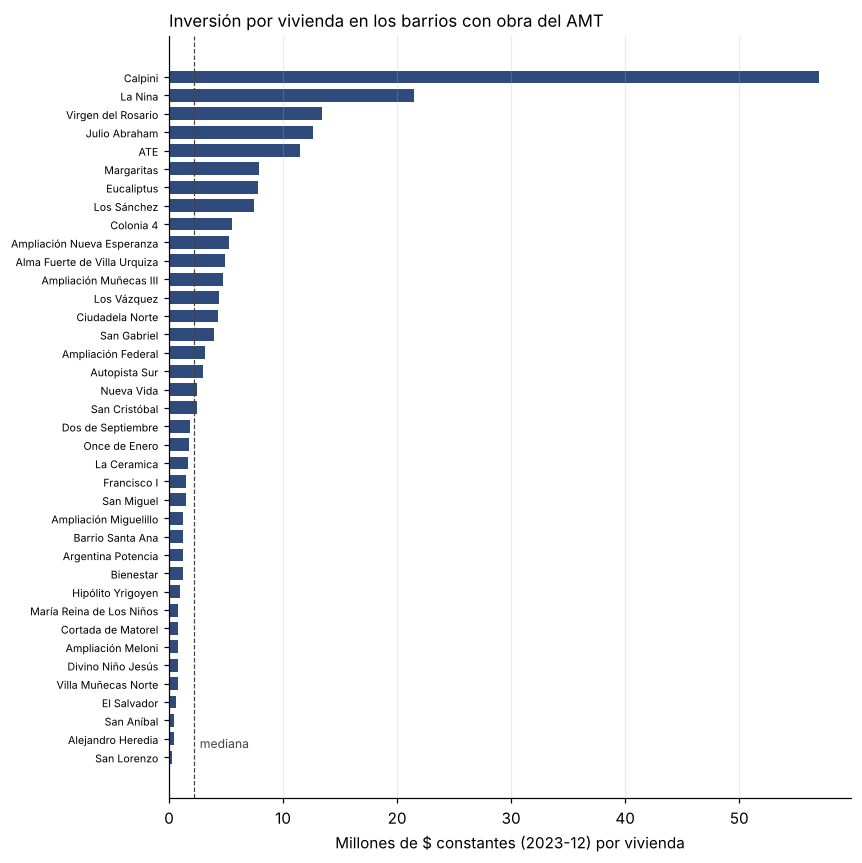

,barrio,viviendas,familias,hectareas,monto_constante,por_vivienda,por_hectarea
id_renabap,,,,,,,
4128,Calpini,45,50,"8,36","2.563.191.618,37","56.959.813,74","306.594.533,43"
4050,La Nina,50,55,"6,63","1.072.650.942,51","21.453.018,85","161.863.155,10"
4074,Virgen del Rosario,400,440,"17,96","5.372.659.163,93","13.431.647,91","299.130.843,33"
4073,Julio Abraham,1.200,1.320,"43,52","15.137.806.703,85","12.614.838,92","347.796.472,91"
2745,ATE,350,385,"16,04","4.016.089.795,04","11.474.542,27","250.340.644,85"
2763,Margaritas,190,209,"9,12","1.501.484.811,16","7.902.551,64","164.593.178,46"
2790,Eucaliptus,110,121,"12,68","855.564.879,74","7.777.862,54","67.447.506,86"
4096,Los Sánchez,110,121,"3,14","820.160.704,32","7.456.006,40","260.857.066,99"
4068,Colonia 4,216,238,"5,25","1.192.344.851,11","5.520.115,05","227.260.483,19"


In [ ]:
# 5.5 (cont.) — Inversión por vivienda en cada barrio con obra del AMT
por_barrio = (atributos.reindex(inv_barrio_amt.index)
              .assign(monto_constante=inv_barrio_amt,
                      barrio=lambda d: d.index.map(NOMBRES_AMT))
              .assign(por_vivienda=lambda d: d["monto_constante"] / d["viviendas"],
                      por_hectarea=lambda d: d["monto_constante"] / d["hectareas"]))
guardar_tabla(por_barrio, "5_inversion_por_barrio_amt")
pv = por_barrio.dropna(subset=["por_vivienda"]).set_index("barrio")["por_vivienda"] / 1e6
print(f"$ por vivienda en los barrios con obra del AMT (millones, constantes): "
      f"mediana {fmt_ar(pv.median(), 2)} · mínimo {fmt_ar(pv.min(), 2)} · máximo {fmt_ar(pv.max(), 2)}")
fig, ax = plt.subplots(figsize=(8, 9))
barras_h(ax, pv, "Inversión por vivienda en los barrios con obra del AMT",
         f"Millones de $ constantes ({MES_BASE_ICC}) por vivienda")
ax.axvline(pv.median(), color=TINTA, linestyle="--", linewidth=0.8)
ax.annotate("mediana", xy=(pv.median(), 0.5), xytext=(4, 0), textcoords="offset points",
            fontsize=8, color=TINTA)
ax.tick_params(axis="y", labelsize=7)
guardar_fig("5_inversion_por_vivienda_amt"); plt.show()
por_barrio.sort_values("por_vivienda", ascending=False)[
    ["barrio", "viviendas", "familias", "hectareas", "monto_constante", "por_vivienda", "por_hectarea"]].head(10)


---
## 6. Mi Pieza — escala nacional

Todo el análisis usa **sólo las adjudicaciones (`Activa`)**. Los otros estados aparecen únicamente donde se los compara de forma explícita (6.1 y 6.2).

### 6.1 Resumen y estados

In [ ]:
# 6.1 — Resumen de adjudicaciones y comparación entre estados
resumen_mp = pd.Series({
    "adjudicaciones": len(mp_adj),
    "monto adjudicado ($ corrientes)": mp_adj["monto"].sum(),
    "monto promedio": mp_adj["monto"].mean(),
    "barrios alcanzados": mp_adj["id_barrio"].nunique(),
    "provincias": mp_adj["provincia"].nunique(),
}, name="Mi Pieza — adjudicadas")
guardar_tabla(resumen_mp.to_frame(), "6_mipieza_resumen")
print(resumen_mp.ar.to_string())

# El monto de las inscriptas es SOLICITADO, no adjudicado: no se suma al de las activas
montos_estado = (mipieza.groupby("estado_norm")
                 .agg(registros=("id", "count"), monto=("monto", "sum"),
                      monto_promedio=("monto", "mean"), barrios=("id_barrio", "nunique")))
montos_estado["%_registros"] = (montos_estado["registros"] / len(mipieza) * 100).round(1)
guardar_tabla(montos_estado, "6_mipieza_estados")
montos_estado

adjudicaciones                            235.783
monto adjudicado ($ corrientes)    74.466.720.000
monto promedio                         315.827,35
barrios alcanzados                          5.076
provincias                                     24


,registros,monto,monto_promedio,barrios,%_registros
estado_norm,,,,,
Activa,235.783,74.466.720.000,"315.827,35",5.076,"48,2"
Inscripta,233.833,138.075.850.000,"590.489,15",5.251,"47,8"
Seleccionada,19.813,6.493.820.000,"327.755,51",3.594,"4,0"


### 6.2 Tipo de obra

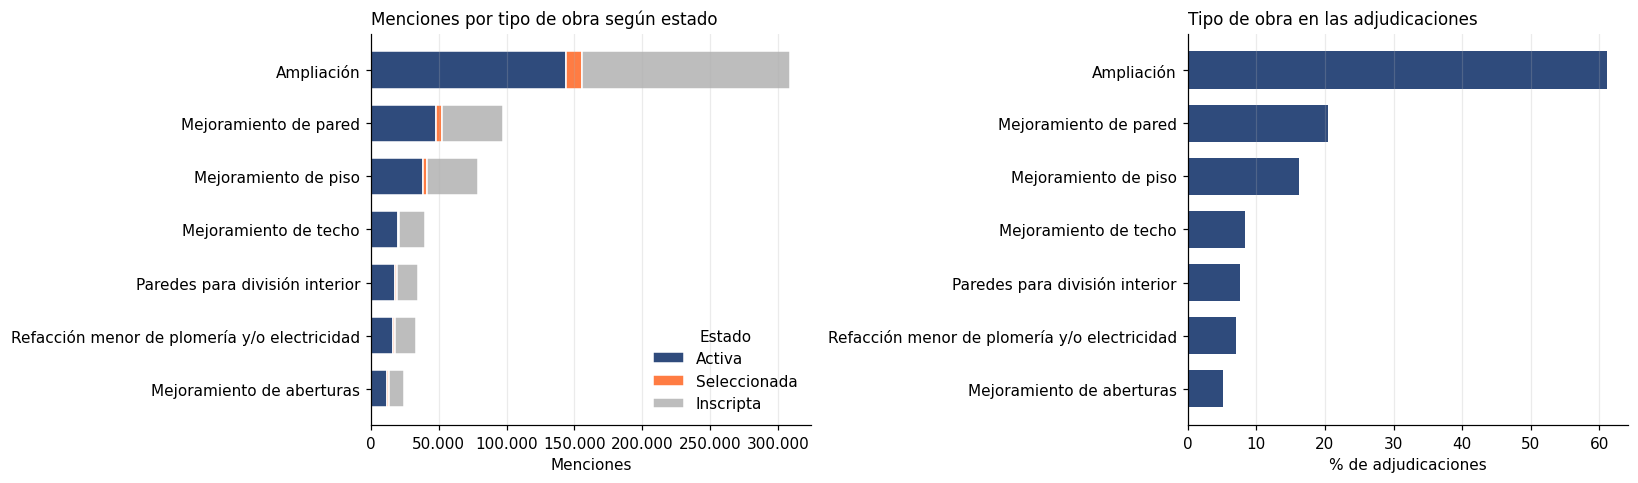

estado_norm,Activa,Seleccionada,Inscripta
tipo_obra_lista,,,
Ampliación,144.029,11.894,153.181
Mejoramiento de pared,48.106,4.219,44.720
Mejoramiento de piso,38.298,2.984,37.441
Mejoramiento de techo,19.679,1.419,18.656
Paredes para división interior,17.811,1.623,15.220
Refacción menor de plomería y/o electricidad,16.441,1.447,15.359
Mejoramiento de aberturas,12.095,1.031,11.175


,adjudicaciones,% de adjudicaciones,monto
tipo_obra_lista,,,
Ampliación,144.029,"61,1",47.489.640.000
Mejoramiento de pared,48.106,"20,4",14.471.630.000
Mejoramiento de piso,38.298,"16,2",11.918.770.000
Mejoramiento de techo,19.679,"8,3",6.210.480.000
Paredes para división interior,17.811,"7,6",5.210.650.000
Refacción menor de plomería y/o electricidad,16.441,"7,0",4.939.180.000
Mejoramiento de aberturas,12.095,"5,1",3.645.730.000


In [ ]:
# 6.2 — Tipo de obra: menciones por estado y composición de lo adjudicado
# Un registro puede declarar varios tipos: los porcentajes no suman 100
mp_largo = mipieza.explode("tipo_obra_lista").reset_index(drop=True)
mp_largo = mp_largo[mp_largo["tipo_obra_lista"].notna()]
tipo_x_estado = pd.crosstab(mp_largo["tipo_obra_lista"], mp_largo["estado_norm"])[list(COLOR_ESTADO_MP)]
tipo_x_estado = tipo_x_estado.sort_values("Activa", ascending=False)

tipos_mp = mp_adj.explode("tipo_obra_lista")["tipo_obra_lista"].value_counts()
tipos_mp_pct = (tipos_mp / len(mp_adj) * 100).round(1)
tabla_tipos_mp = pd.DataFrame({"adjudicaciones": tipos_mp, "% de adjudicaciones": tipos_mp_pct,
                               "monto": mp_adj.explode("tipo_obra_lista").groupby("tipo_obra_lista")["monto"].sum()}
                              ).sort_values("adjudicaciones", ascending=False)
guardar_tabla(tipo_x_estado, "6_mipieza_tipo_x_estado")
guardar_tabla(tabla_tipos_mp, "6_mipieza_tipos_adjudicadas")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
izq = np.zeros(len(tipo_x_estado))
t = tipo_x_estado.iloc[::-1]
for c in t.columns:
    axes[0].barh(t.index, t[c], left=izq[:len(t)], color=COLOR_ESTADO_MP[c], label=c,
                 edgecolor="white", linewidth=1, height=0.7)
    izq += t[c].values
axes[0].set_title("Menciones por tipo de obra según estado"); axes[0].set_xlabel("Menciones")
axes[0].legend(title="Estado", loc="lower right")
barras_h(axes[1], tipos_mp_pct, "Tipo de obra en las adjudicaciones", "% de adjudicaciones")
plt.tight_layout(); guardar_fig("6_mipieza_tipos"); plt.show()

display(tipo_x_estado)
tabla_tipos_mp

### 6.3 Condiciones de la vivienda

Materiales declarados al momento de la solicitud: el total de solicitudes describe la **demanda**; las adjudicadas, a quienes efectivamente alcanzó el programa.

In [ ]:
# 6.3 — Materiales de la vivienda: todas las solicitudes vs. adjudicadas (% por columna)
for col in ["piso_vivienda", "pared_vivienda", "techo_vivienda"]:
    t = pd.DataFrame({"solicitudes (%)": mipieza[col].value_counts(normalize=True) * 100,
                      "adjudicadas (%)": mp_adj[col].value_counts(normalize=True) * 100}).round(1)
    t.index.name = col
    guardar_tabla(t, f"6_mipieza_{col}")
    display(t.sort_values("solicitudes (%)", ascending=False).head(8))

,solicitudes (%),adjudicadas (%)
piso_vivienda,,
Cemento alisado,"58,7","54,8"
Mosaico baldosa cerámica o mármol,"17,2","16,6"
Ladrillo suelto o tierra,"11,9","12,8"
Cemento o ladrillo fijo,"8,2","11,8"
Madera,"3,6","3,7"
Alfombra o goma,"0,4","0,4"


,solicitudes (%),adjudicadas (%)
pared_vivienda,,
Ladrillo,"74,8","74,1"
Madera,"15,1","15,6"
Piedra bloque u hormigón,"5,6","5,6"
Chapa metal o fibrocemento,"2,7","2,9"
Cartón paja o material de desecho,"1,1","1,1"
Adobe,"0,7","0,7"


,solicitudes (%),adjudicadas (%)
techo_vivienda,,
Chapa,"77,0","78,1"
Losa,"16,4","15,4"
"Cubierta provisoria (paja, caña, plástico, cartón, etc)","5,9","6,0"
Teja,"0,6","0,6"
Cubierta provisoria,"0,0","0,0"
Madera,"0,0",NaN


### 6.4 Distribución por jurisdicción

Jurisdicciones con Mi Pieza adjudicada: 24 de 24


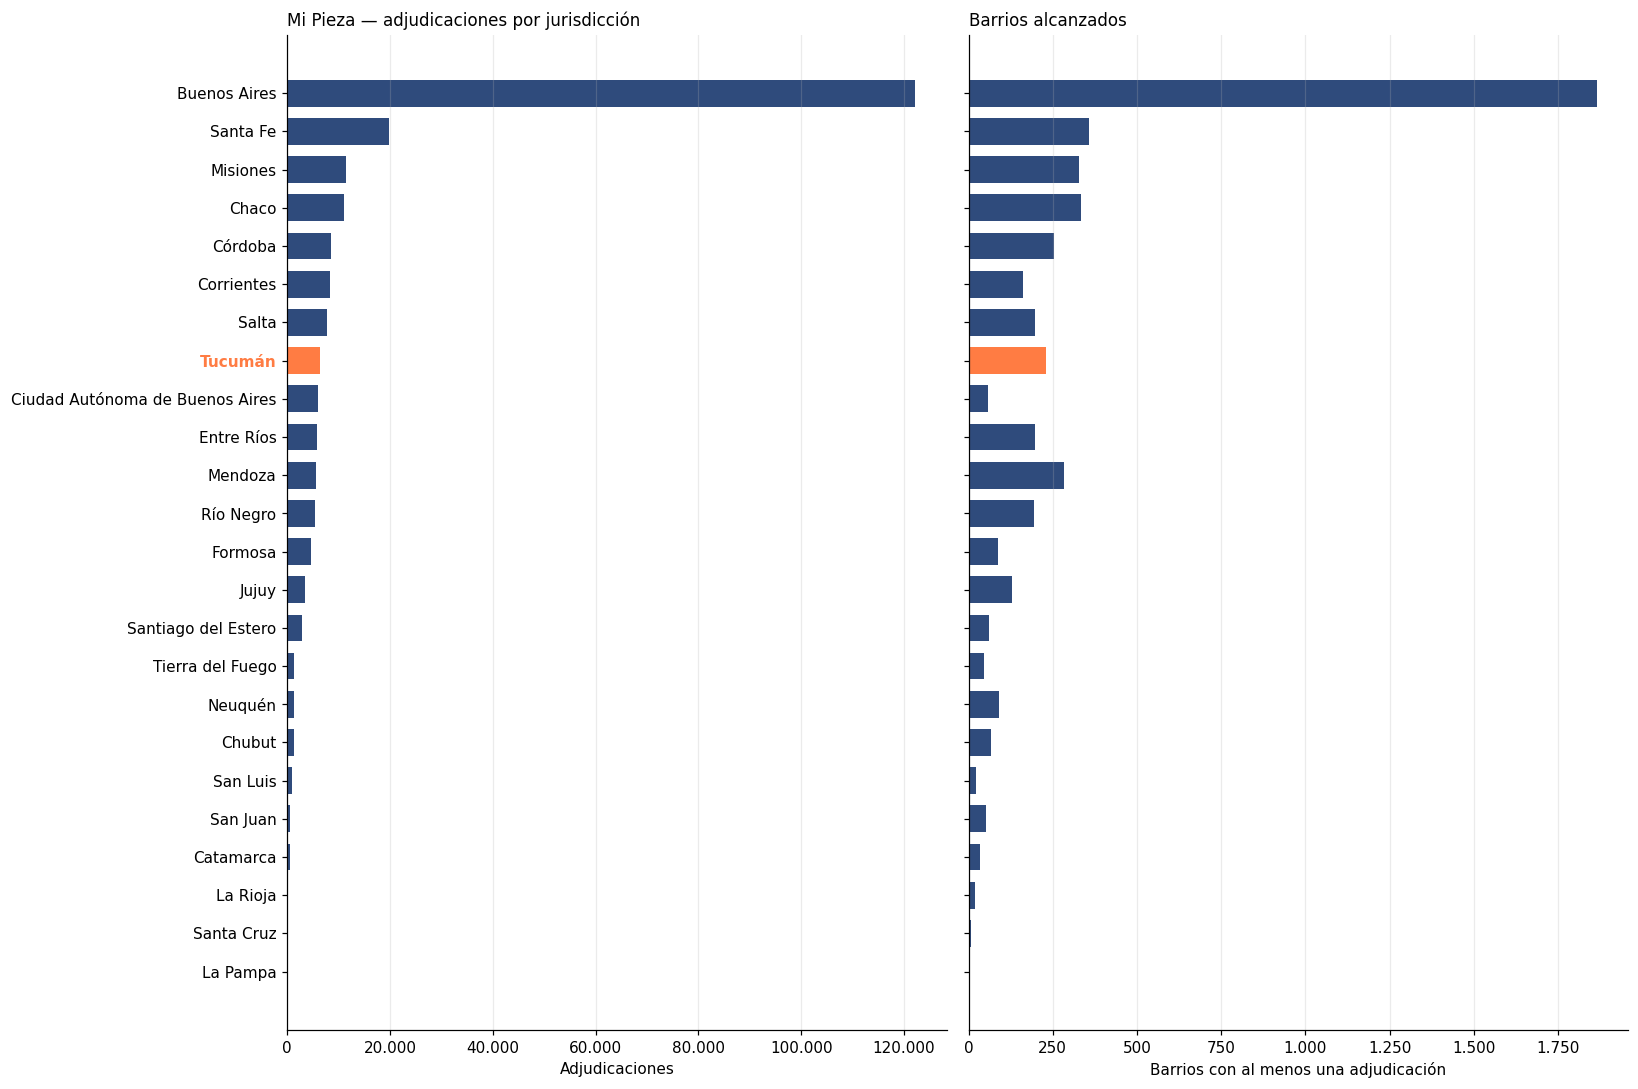

,adjudicaciones,monto,barrios,%_adjudicaciones,%_monto
jurisdicción,,,,,
Buenos Aires,122.187,38.008.800.000,1.864,"51,8","51,0"
Santa Fe,19.885,6.488.160.000,358,"8,4","8,7"
Misiones,11.499,3.752.580.000,327,"4,9","5,0"
Chaco,11.083,3.683.840.000,333,"4,7","4,9"
Córdoba,8.608,2.632.610.000,254,"3,7","3,5"
Corrientes,8.395,2.578.830.000,161,"3,6","3,5"
Salta,7.723,2.483.990.000,196,"3,3","3,3"
Tucumán,6.399,2.138.250.000,231,"2,7","2,9"
Ciudad Autónoma de Buenos Aires,6.009,1.889.970.000,59,"2,5","2,5"


In [ ]:
# 6.4 — Adjudicaciones por jurisdicción (las 24, aunque alguna esté en cero)
prov_mp = (mp_adj.assign(jurisdiccion=mp_adj["provincia"].map(jurisdiccion))
                 .groupby("jurisdiccion")
                 .agg(adjudicaciones=("id", "count"), monto=("monto", "sum"),
                      barrios=("id_barrio", "nunique"))
                 .reindex(PROVINCIAS, fill_value=0)
                 .sort_values("adjudicaciones", ascending=False))
prov_mp["%_adjudicaciones"] = (prov_mp["adjudicaciones"] / prov_mp["adjudicaciones"].sum() * 100).round(1)
prov_mp["%_monto"] = (prov_mp["monto"] / prov_mp["monto"].sum() * 100).round(1)
prov_mp.index.name = "jurisdicción"
guardar_tabla(prov_mp, "6_mipieza_provincias")
print(f"Jurisdicciones con Mi Pieza adjudicada: {fmt_ar((prov_mp['adjudicaciones'] > 0).sum())} de {fmt_ar(len(PROVINCIAS))}")

# Mismo orden en los dos paneles para leer cada jurisdicción en una sola fila
t = prov_mp.iloc[::-1]
colores = [NARANJA if p == "Tucumán" else AZUL for p in t.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=True)
axes[0].barh(t.index, t["adjudicaciones"], color=colores, height=0.7)
axes[0].set_title("Mi Pieza — adjudicaciones por jurisdicción"); axes[0].set_xlabel("Adjudicaciones")
axes[1].barh(t.index, t["barrios"], color=colores, height=0.7)
axes[1].set_title("Barrios alcanzados"); axes[1].set_xlabel("Barrios con al menos una adjudicación")
for etiqueta in axes[0].get_yticklabels():
    if etiqueta.get_text() == "Tucumán":
        etiqueta.set_color(NARANJA); etiqueta.set_fontweight("bold")
plt.tight_layout(); guardar_fig("6_mipieza_provincias"); plt.show()
prov_mp

### 6.5 Contraste con el Monitor Mi Pieza

Una vez filtrado el microdato, las dos fuentes coinciden: las adjudicaciones `Activa` igualan las obras del Monitor (no iniciadas + en ejecución + terminadas) en todas las provincias; las `Seleccionada` igualan las adjudicaciones rechazadas, y la inversión del Monitor es la suma de los montos de ambas. A nivel nacional los tres totales son idénticos; la única diferencia es una adjudicación rechazada ($ 360.000) que el microdato asigna a la Ciudad de Buenos Aires y el Monitor a la provincia de Buenos Aires.

No son universos distintos sino dos cortes de la misma publicación. Por eso la inversión del Monitor **no** se usa como monto invertido: incluye lo rechazado.

In [ ]:
# 6.5 — Validación cruzada entre el microdato y el Monitor, por provincia
grupo = mipieza.groupby(["provincia_norm", "estado_norm"])
n = grupo.size().unstack(fill_value=0)
m = grupo["monto"].sum().unstack(fill_value=0)
mon = (mipieza_mon.groupby("provincia_norm")[["obras_total", "adjudicaciones_rechazadas", "inversion_total"]]
       .sum().astype("int64"))

comp_mp = pd.DataFrame({
    "microdato Activa": n["Activa"], "Monitor obras": mon["obras_total"],
    "microdato Seleccionada": n["Seleccionada"], "Monitor rechazadas": mon["adjudicaciones_rechazadas"],
    "microdato monto Activa + Seleccionada": m["Activa"] + m["Seleccionada"],
    "Monitor inversión": mon["inversion_total"],
})
comp_mp["coincide"] = ((comp_mp["microdato Activa"] == comp_mp["Monitor obras"])
                       & (comp_mp["microdato Seleccionada"] == comp_mp["Monitor rechazadas"])
                       & np.isclose(comp_mp["microdato monto Activa + Seleccionada"], comp_mp["Monitor inversión"]))
comp_mp.index = comp_mp.index.map({norm_texto(p): p for p in PROVINCIAS})
comp_mp.index.name = "jurisdicción"
guardar_tabla(comp_mp, "6_mipieza_contraste_fuentes")
print(f"Provincias donde las dos fuentes coinciden en los tres valores: "
      f"{fmt_ar(comp_mp['coincide'].sum())} de {fmt_ar(len(comp_mp))}")
print("Totales nacionales:")
display(comp_mp.drop(columns="coincide").sum().to_frame("total"))
comp_mp.sort_values("microdato Activa", ascending=False)

Provincias donde las dos fuentes coinciden en los tres valores: 22 de 24
Totales nacionales:


,total
microdato Activa,235.783
Monitor obras,235.783
microdato Seleccionada,19.813
Monitor rechazadas,19.813
microdato monto Activa + Seleccionada,80.960.540.000
Monitor inversión,80.960.540.000


,microdato Activa,Monitor obras,microdato Seleccionada,Monitor rechazadas,microdato monto Activa + Seleccionada,Monitor inversión,coincide
jurisdicción,,,,,,,
Buenos Aires,122.187,122.187,9.240,9.241,41.045.510.000,41.045.870.000,False
Santa Fe,19.885,19.885,1.584,1.584,7.001.070.000,7.001.070.000,True
Misiones,11.499,11.499,1.004,1.004,4.074.990.000,4.074.990.000,True
Chaco,11.083,11.083,1.016,1.016,4.029.480.000,4.029.480.000,True
Córdoba,8.608,8.608,830,830,2.916.180.000,2.916.180.000,True
Corrientes,8.395,8.395,637,637,2.791.540.000,2.791.540.000,True
Salta,7.723,7.723,754,754,2.726.910.000,2.726.910.000,True
Tucumán,6.399,6.399,558,558,2.319.880.000,2.319.880.000,True
Ciudad Autónoma de Buenos Aires,6.009,6.009,634,633,2.084.400.000,2.084.040.000,False


### 6.6 Relación con las obras de integración

In [ ]:
# 6.6 — Barrios con Mi Pieza adjudicada y con obra de integración (país)
s_mp = set(mp_adj["id_barrio"])
s_obra = s_gob | s_mon
print(f"Barrios con Mi Pieza adjudicada: {fmt_ar(len(s_mp))}")
print(f"  también con obra de integración: {fmt_ar(len(s_mp & s_obra))}")
print(f"  sólo con Mi Pieza: {fmt_ar(len(s_mp - s_obra))}")
print(f"Barrios con obra y sin Mi Pieza: {fmt_ar(len(s_obra - s_mp))}")

Barrios con Mi Pieza adjudicada: 5.076
  también con obra de integración: 1.202
  sólo con Mi Pieza: 3.874
Barrios con obra y sin Mi Pieza: 23


La cifra de barrios *sólo con Mi Pieza* es sustantiva para el argumento: mide cuántos barrios recibieron únicamente la transferencia individual, sin ninguna obra de integración urbana asociada.

---
## 7. Mi Pieza — Área Metropolitana de Tucumán

### 7.1 Resumen y verificación con el Monitor

In [ ]:
# 7.1 — Mi Pieza en el AMT
mp_amt = mipieza[mipieza["id_barrio"].isin(IDS_AMT)].copy()
mp_amt_adj = mp_amt[mp_amt["adjudicada"]].copy()
mp_mon_amt = mipieza_mon_barrio[mipieza_mon_barrio["id_renabap"].isin(IDS_AMT)]

print(f"Registros en el AMT: {fmt_ar(len(mp_amt))}")
display(mp_amt.groupby("estado_norm").agg(registros=("id", "count"), monto=("monto", "sum"),
                                          barrios=("id_barrio", "nunique")))
print(f"Adjudicaciones: {fmt_ar(len(mp_amt_adj))} · monto $ {fmt_ar(mp_amt_adj['monto'].sum())} "
      f"· promedio $ {fmt_ar(mp_amt_adj['monto'].mean())}")
print(f"Barrios alcanzados: {fmt_ar(mp_amt_adj['id_barrio'].nunique())} de {fmt_ar(len(IDS_AMT))} "
      f"({fmt_ar(mp_amt_adj['id_barrio'].nunique() / len(IDS_AMT) * 100, 1)} %)")
print(f"\nVerificación con el Monitor — obras: {fmt_ar(mp_mon_amt['obras_total'].sum())} · "
      f"barrios con obras: {fmt_ar((mp_mon_amt['obras_total'] > 0).sum())} · "
      f"rechazadas: {fmt_ar(mp_mon_amt['adjudicaciones_rechazadas'].sum())}")

Registros en el AMT: 12.012


,registros,monto,barrios
estado_norm,,,
Activa,5.599,1.845.030.000,144
Inscripta,5.957,3.535.500.000,150
Seleccionada,456,147.850.000,95


Adjudicaciones: 5.599 · monto $ 1.845.030.000 · promedio $ 329.528
Barrios alcanzados: 144 de 214 (67,3 %)

Verificación con el Monitor — obras: 5.599 · barrios con obras: 144 · rechazadas: 456


### 7.2 Tipo de obra — AMT frente al país

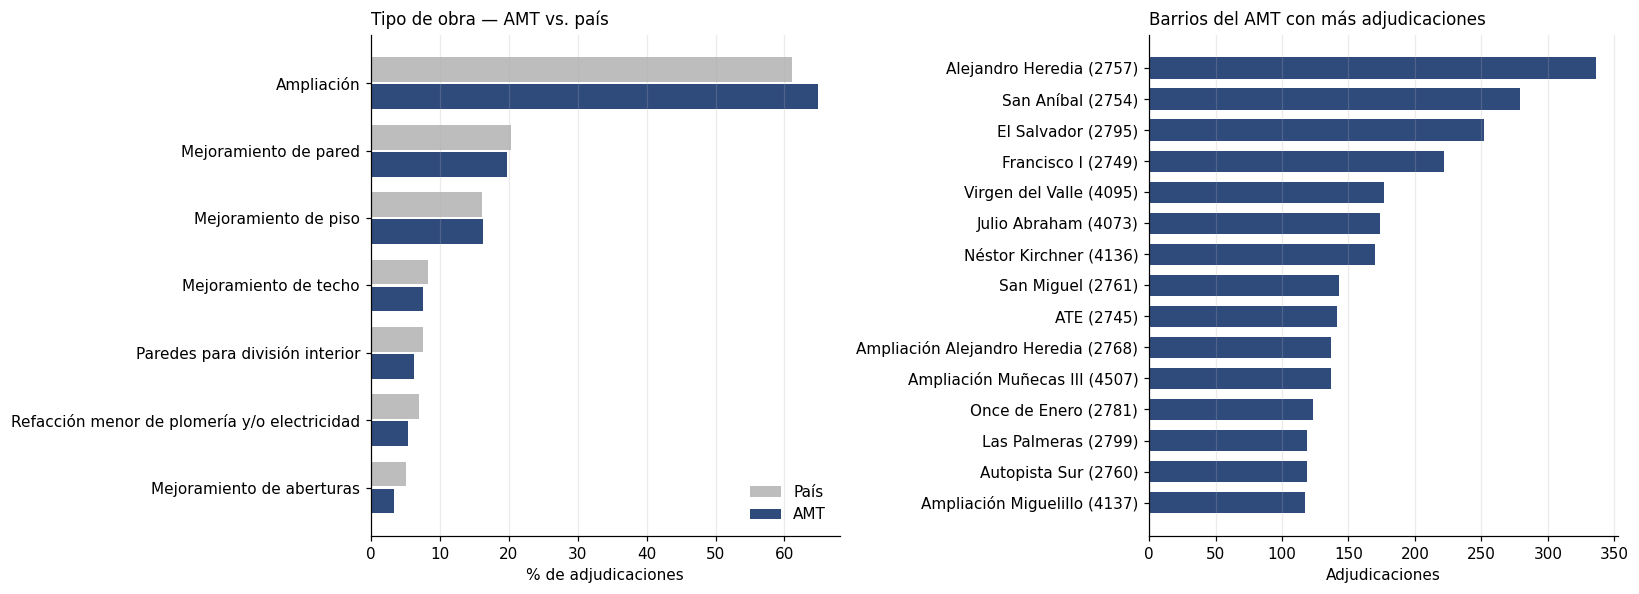

,AMT — adjudicaciones,AMT (%),País (%),Brecha
tipo de obra (adjudicadas),,,,
Ampliación,3.629,"64,8","61,1","3,7"
Mejoramiento de pared,1.105,"19,7","20,4","-0,7"
Mejoramiento de piso,913,"16,3","16,2","0,1"
Mejoramiento de techo,426,"7,6","8,3","-0,7"
Paredes para división interior,353,"6,3","7,6","-1,3"
Refacción menor de plomería y/o electricidad,303,"5,4","7,0","-1,6"
Mejoramiento de aberturas,192,"3,4","5,1","-1,7"


In [ ]:
# 7.2 — Tipo de obra en las adjudicaciones del AMT y del país
tipos_amt = mp_amt_adj.explode("tipo_obra_lista")["tipo_obra_lista"].value_counts()
comp_tipos = pd.DataFrame({"AMT — adjudicaciones": tipos_amt,
                           "AMT (%)": (tipos_amt / len(mp_amt_adj) * 100).round(1),
                           "País (%)": tipos_mp_pct})
comp_tipos["Brecha"] = (comp_tipos["AMT (%)"] - comp_tipos["País (%)"]).round(1)
comp_tipos.index.name = "tipo de obra (adjudicadas)"
guardar_tabla(comp_tipos, "7_mipieza_tipos_amt")

top_b = mp_amt_adj.groupby("id_barrio").size().nlargest(15)
top_b.index = [f"{NOMBRES_AMT.get(i, i)} ({i})" for i in top_b.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
barras_agrupadas(axes[0], comp_tipos[["País (%)", "AMT (%)"]].rename(columns=lambda c: c[:-4])
                 .sort_values("AMT"), COLOR_REFERENCIA, "Tipo de obra — AMT vs. país", "% de adjudicaciones")
barras_h(axes[1], top_b, "Barrios del AMT con más adjudicaciones", "Adjudicaciones")
plt.tight_layout(); guardar_fig("7_mipieza_amt"); plt.show()
comp_tipos

### 7.3 Relación entre las dos políticas en el territorio

Cruce, barrio por barrio, entre la obra de integración (colectiva, de infraestructura) y Mi Pieza (individual, de mejoramiento habitacional). Para "con obra" se usa datos.gob.ar, la fuente con línea y financiamiento.

In [ ]:
# 7.3 — Cruce obra × Mi Pieza en los barrios del AMT
cruce = pd.DataFrame(index=pd.Index(sorted(IDS_AMT), name="id_renabap"))
cruce["con_obra"] = cruce.index.isin(b_gob)
cruce["con_mipieza"] = cruce.index.isin(set(mp_amt_adj["id_barrio"]))
cruce["situacion"] = np.select(
    [cruce["con_obra"] & cruce["con_mipieza"], cruce["con_obra"], cruce["con_mipieza"]],
    ["Obra + Mi Pieza", "Sólo obra", "Sólo Mi Pieza"], default="Sin intervención")

matriz = pd.crosstab(cruce["con_obra"].map({True: "Con obra", False: "Sin obra"}),
                     cruce["con_mipieza"].map({True: "Con Mi Pieza", False: "Sin Mi Pieza"}),
                     margins=True, margins_name="Total")
guardar_tabla(matriz, "7_amt_cruce_politicas")
display(matriz)

det_barrio = det_obras.join(mp_amt_adj.groupby("id_barrio").agg(mipieza_adj=("id", "count"),
                                                                mipieza_monto=("monto", "sum")), how="outer")
det_barrio["barrio"] = det_barrio.index.map(NOMBRES_AMT)
det_barrio[["proyectos", "obras_monitor", "mipieza_adj", "mipieza_monto"]] = \
    det_barrio[["proyectos", "obras_monitor", "mipieza_adj", "mipieza_monto"]].fillna(0).astype("int64")
det_barrio = det_barrio.sort_values(["proyectos", "mipieza_adj"], ascending=False)
guardar_tabla(det_barrio, "7_amt_detalle_por_barrio")
det_barrio.head(30)

con_mipieza,Con Mi Pieza,Sin Mi Pieza,Total
con_obra,,,
Con obra,41,0,41
Sin obra,103,70,173
Total,144,70,214


,barrio,proyectos,municipio,lineas,financiamientos,obras_monitor,mipieza_adj,mipieza_monto
2745,ATE,5,San Miguel De Tucumán,POT,FISU,5,141,49.150.000
4507,Ampliación Muñecas III,4,San Miguel De Tucumán,POT,FISU,4,137,40.230.000
2762,Los Vázquez,4,San Miguel De Tucumán,POT,"BID, FISU",5,47,15.840.000
2760,Autopista Sur,3,San Miguel de Tucumán,POT,BID,4,119,40.650.000
4073,Julio Abraham,2,Alderetes,POT,FISU,2,174,74.830.000
2763,Margaritas,2,San Miguel De Tucumán,POT,FISU,2,49,17.770.000
4128,Calpini,2,Tafí Viejo,POT,FISU,2,38,15.360.000
4119,Divino Niño Jesús,2,Tafí Viejo,"POT, PrePEG","FF, FISU",2,26,7.180.000
2779,Ciudadela Norte,2,San Miguel De Tucumán,POT,FISU,2,22,12.850.000
4050,La Nina,2,Tafí Viejo,POT,"FF, FISU",2,20,7.180.000


In [ ]:
# 7.3 (cont.) — Barrios del AMT sin ninguna intervención registrada
sin_interv = sorted(cruce.index[cruce["situacion"] == "Sin intervención"])
tabla_sin = amt["2023"].loc[amt["2023"]["id_renabap"].isin(sin_interv),
                            ["id_renabap", "nombre_barrio", "localidad", "cantidad_familias_aproximada",
                             "clasificacion_barrio", "agua_corriente", "efluentes_cloacales",
                             "energia_electrica"]].set_index("id_renabap")
guardar_tabla(tabla_sin, "7_amt_barrios_sin_intervencion")
print(f"Barrios del AMT sin intervención registrada: {fmt_ar(len(sin_interv))}")
tabla_sin.head(30)

Barrios del AMT sin intervención registrada: 70


,nombre_barrio,localidad,cantidad_familias_aproximada,clasificacion_barrio,agua_corriente,efluentes_cloacales,energia_electrica
id_renabap,,,,,,,
2747,Villa 9 de Julio II,San Miguel De Tucumán,28,Villa,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión irregular a la red
2785,130 Vivendas,Alderetes,36,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4053,Entrada de Los Sánchez,Los Nogales,22,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión irregular a la red
4058,Holguín,El Manantial,32,Asentamiento,Bomba de agua de pozo comunitaria,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4075,Presidente Perón,Banda Del Río Salí,275,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4077,Tres de Noviembre,Alderetes,80,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4078,Sin Nombre,Alderetes,40,Villa,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4079,Evangelina Salazar,Alderetes,110,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura
4080,Nahuel Huapi,Alderetes,169,Asentamiento,Conexión irregular a la red de agua,Desagüe sólo a pozo negro/ciego u hoyo,Conexión formal a la red con medidor domiciliario con factura


Esta tabla es el reverso analítico del bloque: permite preguntar si los barrios **no alcanzados** se diferencian sistemáticamente de los alcanzados en tamaño, tipología o déficit de servicios.

### 7.4 Cobertura de Mi Pieza en los barrios del AMT

Mi Pieza es una transferencia por hogar, por eso su alcance se mide como **cobertura**: adjudicaciones sobre viviendas del barrio (RENABAP 2023, o 2022 para los que salieron del registro). Las personas alcanzadas son la suma del grupo familiar declarado en cada adjudicación. Los montos son nominales: cada convocatoria fijó un monto ($ 100.000 a $ 600.000) y el microdato no trae la fecha del sorteo, por lo que no se deflactan.

AMT: 5.599 adjudicaciones sobre 34.851 viviendas (16,1 %) · personas alcanzadas: 27.822 · $ por persona: 66.316
País: 235.783 adjudicaciones sobre 1.124.797 viviendas (21,0 %)
Cobertura en barrios alcanzados: mediana 16,6 %


,barrios,barrios_con_mp,adjudicaciones,viviendas,personas,monto,cobertura_%
localidad,,,,,,,
San Miguel De Tucumán,82,74,3.664,20.970,18.377,"1.198.800.000,0","17,5"
Las Talitas,16,9,376,1.642,1.889,"109.740.000,0","22,9"
Barrio San Felipe,6,3,332,731,1.678,"107.120.000,0","45,4"
Alderetes,20,6,246,4.591,1.124,"107.760.000,0","5,4"
"Diagonal Norte, Luz Y Fuerza, Los Pocitos, Villa Nueva Italia",4,4,240,512,1.198,"72.740.000,0","46,9"
Tafí Viejo,21,16,239,1.270,1.112,"83.070.000,0","18,8"
El Manantial,14,12,204,979,973,"67.310.000,0","20,8"
Ingenio San Pablo,9,3,111,676,580,"31.730.000,0","16,4"
Barrio San José III,4,4,64,416,343,"21.180.000,0","15,4"


Cobertura según presencia de obra de integración:


,barrios,barrios_con_mp,adjudicaciones,viviendas,cobertura_%
con_obra,,,,,
Con obra,41,41,3.181,14.918,"21,3"
Sin obra,173,103,2.418,19.933,"12,1"


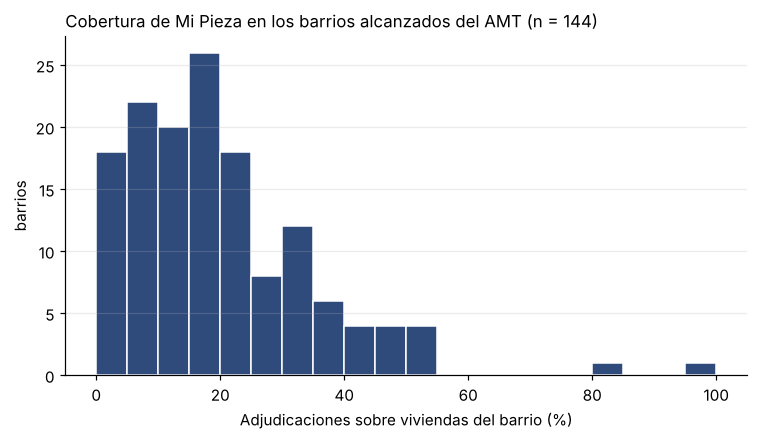

In [ ]:
# 7.4 — Cobertura de Mi Pieza por barrio y por localidad (AMT)
mp_amt_adj["grupo_familiar"] = pd.to_numeric(mp_amt_adj["cantidad_grupo_familiar"], errors="coerce")
cob = (mp_amt_adj.groupby("id_barrio")
       .agg(adjudicaciones=("id", "count"), personas=("grupo_familiar", "sum"), monto=("monto", "sum"))
       .reindex(sorted(IDS_AMT)).fillna(0).astype({"adjudicaciones": int, "personas": int})
       .join(atributos[["viviendas", "familias"]]))
cob["localidad"] = cob.index.map(UBICACION["localidad"]).fillna("San Miguel De Tucumán")
cob["cobertura_%"] = cob["adjudicaciones"] / cob["viviendas"] * 100
cob["con_obra"] = np.where(cob.index.isin(b_gob), "Con obra", "Sin obra")

tot = cob[["adjudicaciones", "personas", "monto", "viviendas"]].sum()
print(f"AMT: {fmt_ar(tot['adjudicaciones'])} adjudicaciones sobre {fmt_ar(tot['viviendas'])} viviendas "
      f"({fmt_ar(tot['adjudicaciones'] / tot['viviendas'] * 100, 1)} %) · personas alcanzadas: "
      f"{fmt_ar(tot['personas'])} · $ por persona: {fmt_ar(tot['monto'] / tot['personas'])}")
pais_viv = atributos.reindex(ATR["2023"].index)["viviendas"].sum()
print(f"País: {fmt_ar(len(mp_adj))} adjudicaciones sobre {fmt_ar(pais_viv)} viviendas "
      f"({fmt_ar(len(mp_adj) / pais_viv * 100, 1)} %)")
print(f"Cobertura en barrios alcanzados: mediana {fmt_ar(cob.loc[cob['adjudicaciones'] > 0, 'cobertura_%'].median(), 1)} %")

por_loc = (cob.groupby("localidad")
           .agg(barrios=("viviendas", "size"),
                barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                adjudicaciones=("adjudicaciones", "sum"), viviendas=("viviendas", "sum"),
                personas=("personas", "sum"), monto=("monto", "sum"))
           .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)})
           .sort_values("adjudicaciones", ascending=False))
guardar_tabla(por_loc, "7_amt_mipieza_localidad")
display(por_loc)
print("Cobertura según presencia de obra de integración:")
display(cob.groupby("con_obra").agg(barrios=("viviendas", "size"),
                                    barrios_con_mp=("adjudicaciones", lambda s: int((s > 0).sum())),
                                    adjudicaciones=("adjudicaciones", "sum"),
                                    viviendas=("viviendas", "sum"))
        .assign(**{"cobertura_%": lambda d: (d["adjudicaciones"] / d["viviendas"] * 100).round(1)}))

c = cob.loc[cob["adjudicaciones"] > 0, "cobertura_%"].clip(upper=100)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(c, bins=range(0, 105, 5), color=AZUL, edgecolor="white")
ax.set_title(f"Cobertura de Mi Pieza en los barrios alcanzados del AMT (n = {len(c)})")
ax.set_xlabel("Adjudicaciones sobre viviendas del barrio (%)"); ax.set_ylabel("barrios")
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
guardar_fig("7_amt_mipieza_cobertura"); plt.show()


---
## 8. Cartografía

Mapas **de trabajo** sobre los polígonos RENABAP 2023 (columna `WKT` del archivo nacional) y el límite metropolitano. Sirven para leer resultados y detectar errores de asignación; la cartografía final se arma en QGIS 3.34.13 con el GeoPackage que exporta 8.8.

Los barrios que sólo existen en 2018 o 2022 no tienen polígono 2023: se listan en lugar de desaparecer sin aviso.

Debajo de cada mapa va un **mapa base en escala de grises** con calles y vías principales (CARTO Positron, sobre datos de OpenStreetMap), que se descarga al momento: hace falta conexión a internet. Para dibujar, las capas se pasan a EPSG:3857, el sistema de los mapas base web; los cálculos de superficie siguen en EPSG:5345.

### 8.1 Polígonos y límite del AMT

In [ ]:
# 8.1 — Polígonos de los barrios del AMT y límite metropolitano
try:
    import geopandas as gpd
except ImportError:
    !pip install geopandas --quiet
    import geopandas as gpd
try:
    import contextily as ctx
except ImportError:
    !pip install contextily --quiet
    import contextily as ctx
from shapely import wkt
import tempfile, urllib.request

# Mapas base en grises con vías (estilo Google Maps), sin API key. Se prueba en orden
# y se usa el primero que responde. Lista vacía = sin mapa base
MAPA_BASE = [
    ("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
     "Esri, HERE, Garmin, © OpenStreetMap contributors"),
    ("https://a.basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png",
     "© OpenStreetMap contributors © CARTO"),
]

geo23 = leer_csv(FUENTES["renabap_2023"], dtype={"id_renabap": str},
                 usecols=["id_renabap", "nombre_barrio", "localidad", "cantidad_familias_aproximada",
                          "clasificacion_barrio", "superficie_m2", "WKT"])
geo23["id_renabap"] = geo23["id_renabap"].str.strip()
geo23 = geo23[geo23["id_renabap"].isin(IDS_AMT)].copy()
barrios_amt = gpd.GeoDataFrame(geo23.drop(columns="WKT"), geometry=geo23["WKT"].apply(wkt.loads), crs=CRS_GEO)
print(f"Barrios con geometría 2023: {fmt_ar(len(barrios_amt))} de {fmt_ar(len(IDS_AMT))}")
print("Sin geometría 2023 (no se dibujan):", sorted(IDS_AMT - set(barrios_amt["id_renabap"])) or "ninguno")

# geopandas no lee el .gpkg directo desde la URL: lo bajo a un temporal
ruta_limite = os.path.join(tempfile.gettempdir(), "limite_amt.gpkg")
urllib.request.urlretrieve(FUENTES["limite_amt"], ruta_limite)
# El GeoPackage trae dos capas: uso "limite_amt" (la otra, "amt_mascara", es una máscara cartográfica)
limite_amt = gpd.read_file(ruta_limite, layer="limite_amt")
limite_amt = (limite_amt.set_crs(CRS_GEO) if limite_amt.crs is None else limite_amt).to_crs(CRS_GEO)
limite_map = limite_amt.to_crs(CRS_MAPA)

Barrios con geometría 2023: 213 de 214
Sin geometría 2023 (no se dibujan): ['2756']


### 8.2 Atributos de intervención sobre la capa de barrios

In [ ]:
# 8.2 — Atributos de intervención por barrio
# Dimensión y escala sólo con obras clasificables (sin acciones fuera de matriz)
obras_amt_barrio_clas = clasificables(obras_amt_barrio)
dim_barrio = (obras_amt_barrio_clas.groupby("id_renabap")["dimension_principal"]
              .agg(lambda s: s.value_counts().idxmax()))       # la más frecuente entre sus obras
escala_barrio = (obras_amt_barrio_clas.groupby("id_renabap")["escala"]
                 .agg(lambda s: "ambas" if s.nunique() > 1 else s.iloc[0]))

barrios_amt = barrios_amt.merge(
    pd.concat([obras_amt_barrio.groupby("id_renabap").agg(n_proyectos=("proyecto_id", "nunique")),
               mp_amt_adj.groupby("id_barrio").agg(mipieza_adj=("id", "count"),
                                                   mipieza_monto=("monto", "sum")),
               dim_barrio.rename("dimension_predominante"),
               escala_barrio.rename("escala_barrio"),
               cruce["situacion"]], axis=1),
    left_on="id_renabap", right_index=True, how="left")
barrios_amt[["n_proyectos", "mipieza_adj", "mipieza_monto"]] = \
    barrios_amt[["n_proyectos", "mipieza_adj", "mipieza_monto"]].fillna(0)
barrios_amt["superficie_ha"] = barrios_amt.to_crs(CRS_METRICO).area / 10_000
barrios_map = barrios_amt.to_crs(CRS_MAPA)          # sólo para dibujar sobre el mapa base
print(barrios_amt["situacion"].value_counts().ar.to_string())

situacion
Sólo Mi Pieza       103
Sin intervención     70
Obra + Mi Pieza      40


### 8.3 Mapa 1 — Situación de intervención

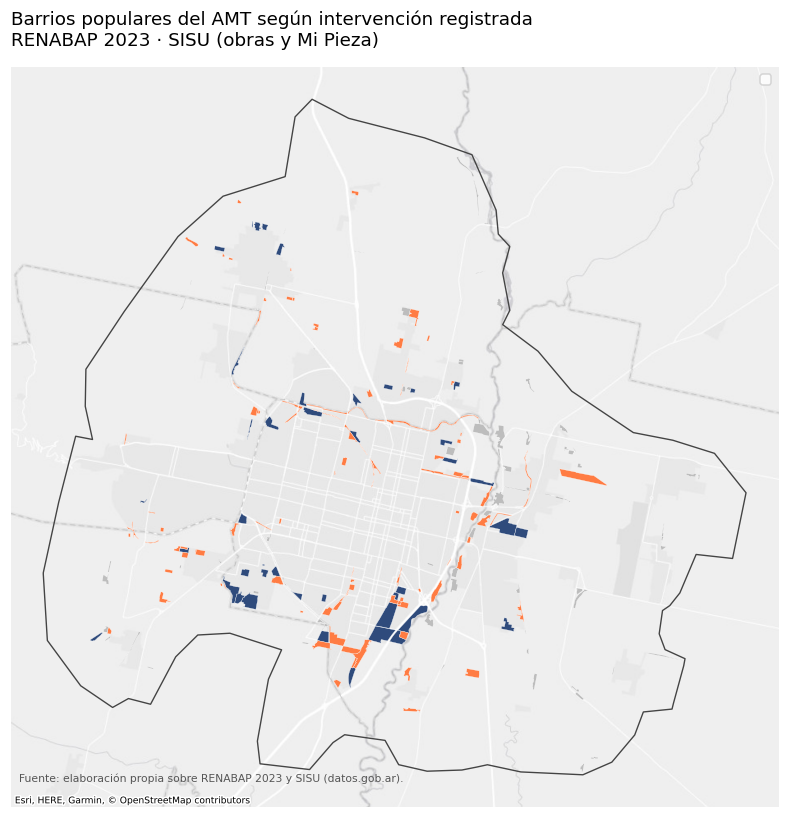

In [ ]:
# 8.3 — Mapa de situación de intervención
fig, ax = mapa_base("Barrios populares del AMT según intervención registrada\nRENABAP 2023 · SISU (obras y Mi Pieza)")
for sit, color in COLOR_SITUACION.items():
    sub = barrios_map[barrios_map["situacion"] == sit]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2, zorder=2,
                 label=f"{sit} (n = {fmt_ar(len(sub))})")
ax.legend(loc="upper right", frameon=True, fontsize=9)
guardar_fig("8_mapa_situacion"); plt.show()

### 8.4 Mapa 2 — Dimensión predominante

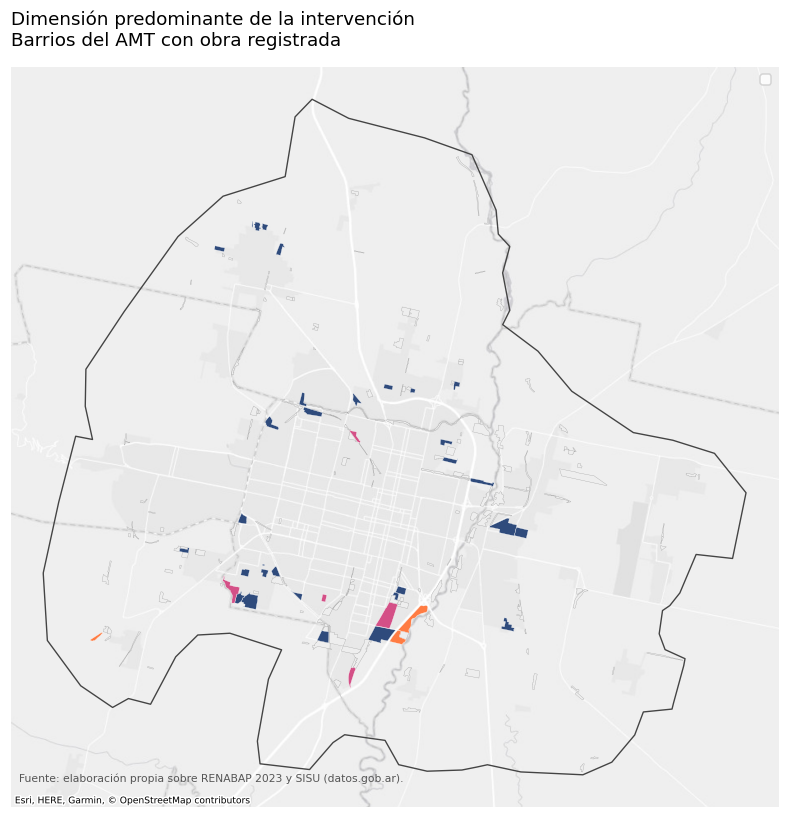

In [ ]:
# 8.4 — Mapa de la dimensión predominante de las obras
fig, ax = mapa_base("Dimensión predominante de la intervención\nBarrios del AMT con obra registrada")
barrios_map[barrios_map["dimension_predominante"].isna()].plot(
    ax=ax, color=GRIS_CLARO, edgecolor="#9E9E9E", linewidth=0.2, zorder=2)
for dim, color in COLOR_DIMENSION.items():
    sub = barrios_map[barrios_map["dimension_predominante"] == dim]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2, zorder=3,
                 label=f"{dim} (n = {fmt_ar(len(sub))})")
ax.legend(loc="upper right", frameon=True, fontsize=9)
guardar_fig("8_mapa_dimension"); plt.show()

### 8.5 Mapa 3 — Intensidad de Mi Pieza

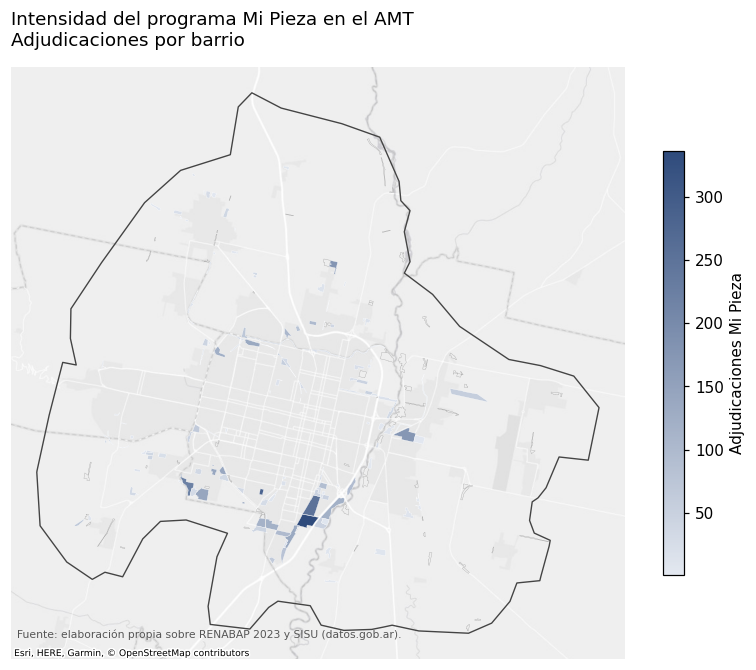

In [ ]:
# 8.5 — Mapa de adjudicaciones de Mi Pieza por barrio
fig, ax = mapa_base("Intensidad del programa Mi Pieza en el AMT\nAdjudicaciones por barrio")
barrios_map[barrios_map["mipieza_adj"] == 0].plot(ax=ax, color=GRIS_CLARO, edgecolor="#9E9E9E",
                                                  linewidth=0.2, zorder=2)
barrios_map[barrios_map["mipieza_adj"] > 0].plot(
    ax=ax, column="mipieza_adj", cmap=CMAP_MAGNITUD, edgecolor="white", linewidth=0.2, zorder=3,
    legend=True, legend_kwds={"label": "Adjudicaciones Mi Pieza", "shrink": 0.5})
guardar_fig("8_mapa_mipieza"); plt.show()

### 8.6 Mapa 4 — Escala de las intervenciones

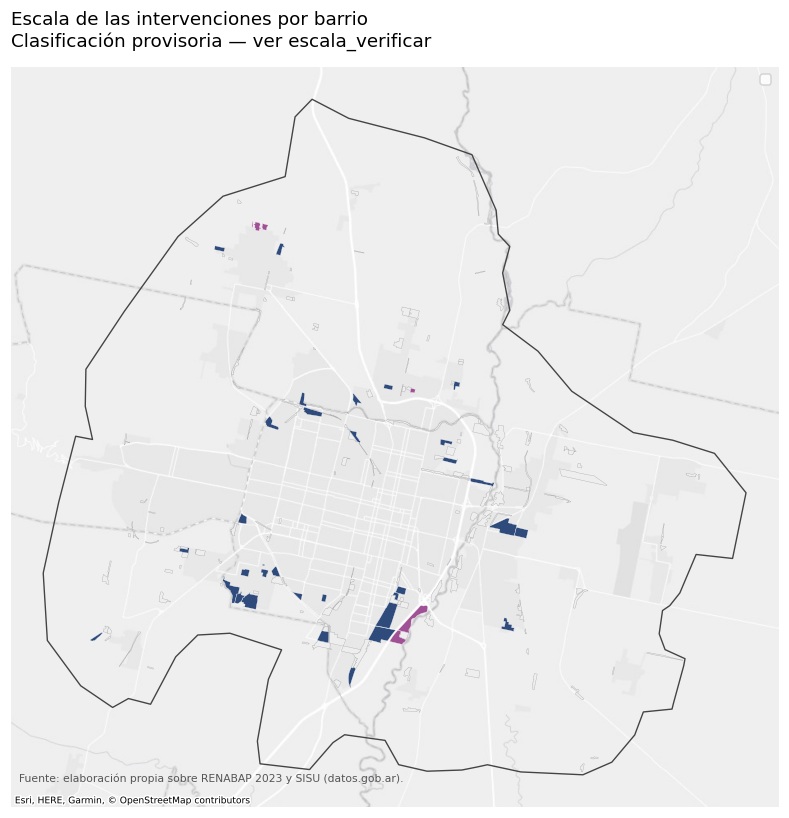

In [ ]:
# 8.6 — Mapa de la escala declarada de las obras (provisoria: ver escala_verificar)
fig, ax = mapa_base("Escala de las intervenciones por barrio\nClasificación provisoria — ver escala_verificar")
barrios_map[barrios_map["escala_barrio"].isna()].plot(ax=ax, color=GRIS_CLARO, edgecolor="#9E9E9E",
                                                      linewidth=0.2, zorder=2)
for esc, color in COLOR_ESCALA.items():
    sub = barrios_map[barrios_map["escala_barrio"] == esc]
    if len(sub):
        sub.plot(ax=ax, color=color, edgecolor="white", linewidth=0.2, zorder=3,
                 label=f"{esc} (n = {fmt_ar(len(sub))})")
ax.legend(loc="upper right", frameon=True, fontsize=9)
guardar_fig("8_mapa_escala"); plt.show()

### 8.7 Exportación para QGIS 3.34.13

In [ ]:
# 8.7 — GeoPackage con la clasificación F3 como atributos
# Paso los booleanos a entero (QGIS los simboliza mejor) y descarto las columnas con listas
def para_gpkg(gdf):
    g = gdf.drop(columns=[c for c in gdf.columns if gdf[c].dtype == object
                          and gdf[c].map(type).eq(list).any()])
    for c in g.columns:
        if g[c].dtype == bool:
            g[c] = g[c].astype(int)
    return g


if EXPORTAR:
    salida_gpkg = "salidas/barrios_amt_intervenciones.gpkg"
    para_gpkg(barrios_amt).to_file(salida_gpkg, layer="barrios_amt", driver="GPKG")
    proy_geo = gpd.GeoDataFrame(obras_amt_barrio.merge(barrios_amt[["id_renabap", "geometry"]],
                                                       on="id_renabap", how="left"),
                                geometry="geometry", crs=CRS_GEO)
    para_gpkg(proy_geo).to_file(salida_gpkg, layer="proyectos_amt", driver="GPKG")
    print(f"GeoPackage exportado: {salida_gpkg} (capas barrios_amt y proyectos_amt)")
    print(f"CRS {CRS_GEO}: reproyectar a {CRS_METRICO} en QGIS para cálculos métricos")

GeoPackage exportado: salidas/barrios_amt_intervenciones.gpkg (capas barrios_amt y proyectos_amt)
CRS EPSG:4326: reproyectar a EPSG:5345 en QGIS para cálculos métricos


---
## 9. Exportación

Las tablas quedan en `salidas/tablas/`, las figuras en `salidas/figuras/` y las bases armonizadas en `salidas/`. La celda comprime todo para descargarlo desde Colab.

In [ ]:
# 9 — Bases armonizadas y archivo comprimido de salidas
import shutil

if EXPORTAR:
    sin_listas = lambda d: d.drop(columns=["ids_renabap", "tipo_obra_lista"], errors="ignore")
    sin_listas(obras).to_csv("salidas/obras_armonizadas.csv", index=False, encoding="utf-8-sig")
    sin_listas(monitor).to_csv("salidas/monitor_armonizado.csv", index=False, encoding="utf-8-sig")
    sin_listas(obras_barrio).to_csv("salidas/obras_por_barrio.csv", index=False, encoding="utf-8-sig")
    sin_listas(obras_amt).to_csv("salidas/obras_amt.csv", index=False, encoding="utf-8-sig")
    det_barrio.to_csv("salidas/amt_detalle_barrio.csv", encoding="utf-8-sig")
    shutil.make_archive("salidas_bloque2", "zip", "salidas")
    print("Archivo generado: salidas_bloque2.zip")

# En Colab, para descargar:
# from google.colab import files
# files.download("salidas_bloque2.zip")

Archivo generado: salidas_bloque2.zip


### Pendientes de calibración

1. **Escala.** Primer análisis a gran escala, con valores de referencia. El alcance depende de cada proyecto: en el AMT se estudia caso por caso, con las planillas `3_escala_revision_*.csv` como punto de partida.
2. **`MUNICIPIOS_AMT`.** Verificar la lista contra las jurisdicciones que corta `limite_amt` (sólo afecta el control 4.2).
3. **Barrios sin geometría 2023.** No se dibujan; si son relevantes, recuperar su polígono del relevamiento correspondiente.